# Tema 2 IA


## 1. Setup si imports



In [1]:
import os
import json
import time
import random
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch._utils
import torch._dynamo
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    confusion_matrix, accuracy_score, f1_score, classification_report
)
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## 2. Configurare path-uri

**Optiunea A (recomandata pentru viteza)**: dezarhiveaza zip-urile in `/content/` (storage local Colab) - acolo I/O-ul este mult mai rapid decat din Drive direct.

**Optiunea B**: foloseste datele direct din Drive (mai lent, dar nu trebuie redezarhivat la fiecare runtime nou).

Pune zip-urile in Drive (de ex. `MyDrive/Tema2_IA/`) si decomenteaza varianta dorita mai jos.


In [2]:
dataset_alunite = "/kaggle/input/datasets/oncioiumirunaelena/moless" 

MOLES_TRAIN_CSV = f"{dataset_alunite}/train.csv"
MOLES_TEST_CSV  = f"{dataset_alunite}/test.csv"
MOLES_TRAIN_IMG_DIR = f"{dataset_alunite}/train"           
MOLES_TEST_IMG_DIR  = f"{dataset_alunite}/test"            
MOLES_KAGGLE_CSV = f"{dataset_alunite}/kaggle_test.csv"
MOLES_KAGGLE_IMG_DIR = f"{dataset_alunite}/kaggle_test"

MOLES_MEAN = [0.7646, 0.5464, 0.5712]
MOLES_STD  = [0.1410, 0.1532, 0.1706]
MOLES_CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

dataset_emotii = "/kaggle/input/datasets/oncioiumirunaelena/emotions"

EMOTIONS_TRAIN_CSV      = f"{dataset_emotii}/splits/train.csv"
EMOTIONS_LOCAL_TEST_CSV = f"{dataset_emotii}/splits/local_test.csv"
EMOTIONS_REMOTE_TEST_CSV = f"{dataset_emotii}/splits/remote_test.csv"
EMOTIONS_IMG_ROOT       = f"{dataset_emotii}/DATASET"

EMOTIONS_CLASS_NAMES = {1: 'Surprise', 2: 'Fear', 3: 'Disgust', 4: 'Happiness', 5: 'Sadness',  6: 'Anger', 7: 'Neutral'}

WORK_DIR = "/kaggle/working"

In [3]:
EMOTIONS_MEAN = [0.485, 0.456, 0.406]
EMOTIONS_STD  = [0.229, 0.224, 0.225]

print(f"Emotions stats setate direct (Kaggle fix): mean={EMOTIONS_MEAN}, std={EMOTIONS_STD}")

Emotions stats setate direct (Kaggle fix): mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]


## 3. Dataset-uri PyTorch

Implementam doua clase `Dataset` adaptate la format-urile reale ale CSV-urilor:

- **`MolesDataset`**: CSV cu coloane `imagine` (doar numele fisierului) si `diagnostic` (numele clasei). Imaginile traiesc intr-un folder separat pe split (`train/`, `test/`, ...).
- **`EmotionsDataset`**: CSV cu coloane `path` (relativa la radacina emotions) si `label` (1..7, scazut 1 ca sa fie 0..6 cu PyTorch).


In [4]:
class MolesDataset(Dataset):
    def __init__(self, csv_path, img_dir, class_names=None, transform=None):
        # Salvez transformarile (Resize, Normalize, Augmentari) ca sa le aplic
        self.transform = transform
        # Dir unde sunt pozele
        self.img_dir = img_dir
        # Dc nu dau o lista de clase la init, o fol pe cea def anterior (MOLES_CLASS_NAMES)
        self.class_names = class_names or MOLES_CLASS_NAMES
        # Creez un dict care transf numele cls in nr ('akiec' -> 0, 'bcc' -> 1)
        # pt ca etelele neurale stiu sa lucreze doar cu nr
        self.class_to_idx = {c: i for i, c in enumerate(self.class_names)}
        # Creez dict inv, de la nr la nume (pt a afisa rezultatele)
        self.idx_to_class = {i: c for c, i in self.class_to_idx.items()}
        # Citire fis csv
        df = pd.read_csv(csv_path)
        # Dc exista coloana 'imagine', o ia pe aia. Dc nu, ia prima coloana din CSV.
        path_col  = 'imagine'   if 'imagine'   in df.columns else df.columns[0]
        # La fel si pentru eticheta (diagnostic).
        label_col = 'diagnostic' if 'diagnostic' in df.columns else (
            df.columns[1] if len(df.columns) > 1 else None)
        # toate perechile de tipul (calea_catre_imagine, eticheta_ei_numerica)
        self.samples = []
        # fiecare rand din tabelul CSV, unul cate unul
        for _, row in df.iterrows():
            fname = str(row[path_col]) # nume poza
            # calea completa (folder + nume fisier)
            full_path = os.path.join(img_dir, fname)
            # Verif dc am o eticheta valida pe acest rand
            if label_col is not None and not pd.isna(row[label_col]):
                lbl = row[label_col]
                # Dc eticheta e text, o transf in nr fol dict
                if isinstance(lbl, str):
                    if lbl not in self.class_to_idx:
                        continue
                    lbl = self.class_to_idx[lbl]
                 # Adaug perechea (cale, eticheta_numerica) in lista
                self.samples.append((full_path, int(lbl)))
            else:
                # dc nu s etichete pun -1
                self.samples.append((full_path, -1))  # caz kaggle_test (fara etichete)

    # Functie standard PyTorch: ii spune sist ct imagini sunt in total in acest dataset
    def __len__(self):
        return len(self.samples)

    # Functie standard PyTorch: se apeleaza cand cer o anumita imagine (ex: dataset[5])
    def __getitem__(self, idx):
        path, label = self.samples[idx] # extrag calea si eticheta
        # Deschid imag cu biblioteca PIL in format RGB
        # esential pt ca reteaua CNN (sau MLP) va astepta mereu 3 canale de intrare
        img = Image.open(path).convert("RGB")
        # Dc am definit transformari (resize, crop, normalizare in tensor), le aplic acum pe imagine
        if self.transform is not None:
            img = self.transform(img)
        # Returnez imaginea (devenita Tensor dc am aplicat transforms.ToTensor) si eticheta ei
        return img, label

    # nr rapid cate imagini sunt din fiecare clasa
    # pt a rez pb setului de date dezechilibrat (calculare de ponderi).
    def get_labels(self):
        return np.array([lbl for _, lbl in self.samples])


# 1. Clasa "Glonț" cu căutare recursivă
class EmotionsDataset(Dataset):
    def __init__(self, csv_path, img_dir, transform=None):
        self.df = pd.read_csv(csv_path)
        self.df.columns = [c.strip() for c in self.df.columns]
        self.transform = transform
        self.id_col = [c for c in self.df.columns if c != 'label'][0]
        
        import glob
        import os
        # MAGIC FIX: Caută peste tot, la orice adâncime!
        paths = glob.glob(os.path.join(img_dir, '**', '*.jpg'), recursive=True)
        self.name2path = {os.path.basename(p): p for p in paths}
        
        self.samples = []
        for _, row in self.df.iterrows():
            raw_fname = str(row[self.id_col]).strip()
            fname = os.path.basename(raw_fname) 
            
            if fname not in self.name2path and fname + ".jpg" in self.name2path:
                fname += ".jpg"
                
            if fname in self.name2path:
                label = int(row['label']) - 1
                full_path = self.name2path[fname]
                self.samples.append((full_path, label))
        
        # Un mic print ca să fim 100% siguri că le-a găsit
        print(f"Dataset inițializat. S-au găsit {len(self.samples)} poze valide!")
        
    def __len__(self): 
        return len(self.samples)
        
    def get_labels(self): 
        return np.array([lbl for _, lbl in self.samples])
        
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform: 
            img = self.transform(img)
        return img, label


# Cerinta 3.1: Vizualizarea augmentarii seturilor de date

## Justificarea augmentarilor alese

### Pentru setul Moles (aluntite dermatoscopice)

Imaginile dermatoscopice **NU au orientare naturala** (un mole "nu are sus si jos") - aceasta este o caracteristica importanta a problemei.

| Augmentare | De ce este OK / utila |
|------------|----------------------|
| `Resize(96, 96)` | Uniformizeaza dimensiunea (originalul este 130x100); 96x96 pastreaza majoritatea informatiei la cost computational redus |
| `RandomHorizontalFlip` | Imaginile dermatoscopice nu au orientare preferata - flip-ul orizontal pastreaza semantica |
| `RandomVerticalFlip` | Acelasi argument ca mai sus - **OK pentru moles, NU pentru fete** |
| `RandomRotation(180)` | Idem - rotatia completa este sigura |
| `ColorJitter(0.1, 0.1, 0.05)` | **Subtila!** Culoarea (asimetrie pigmentara, structuri rosii) este DIAGNOSTICA pentru melanom; un jitter agresiv ar distruge informatia |
| `Normalize(MOLES_MEAN, MOLES_STD)` | Statistici dataset-specifice (din enunt) - mult mai potrivite decat ImageNet |

### Pentru setul Emotions (expresii faciale)

Fetele AU orientare naturala (gura jos, ochii sus) - asta dicteaza ce augmentari sunt sigure.

| Augmentare | De ce este OK / utila |
|------------|----------------------|
| `Resize(96, 96)` | Aproape de rezolutia originala 100x100 |
| `RandomHorizontalFlip` | Fetele sunt aproximativ simetrice - emotia se pastreaza |
| **NU** `RandomVerticalFlip` | Fetele nu apar cu capul in jos - ar schimba semantica |
| `RandomRotation(15)` | Mici inclinari naturale (pe fotografii reale); **NU** rotatii mari |
| `RandomAffine(translate, scale)` | Compenseaza alinierea imperfecta a fetei |
| `ColorJitter(0.2, 0.2, 0.1)` | Iluminarea variaza puternic in conditii reale (in-the-wild) |
| `Normalize(EMOTIONS_MEAN, EMOTIONS_STD)` | Statistici calculate **doar pe train** (din `norm_stats.json` - ca sa nu existe leak de la test) |

In ambele cazuri, validarea/testul folosesc **doar `Resize + ToTensor + Normalize`** - nicio augmentare aleatoare.


In [5]:
IMG_SIZE = 96 # fortez dimensiunea imaginilor la 96

# Pipeline-uri pentru ALUNITE
moles_train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=180),     # nu exista orientare naturala
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05),  # subtil
    transforms.ToTensor(),
    transforms.Normalize(mean=MOLES_MEAN, std=MOLES_STD),
])

moles_eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MOLES_MEAN, std=MOLES_STD),
])

# Pipeline-uri pentru EMOTII
emotions_train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),     # fete aprox simetrice
    # nu fol VerticalFlip - fetele nu apar cu capul in jos
    transforms.RandomRotation(degrees=15),      # inclinari mici
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=EMOTIONS_MEAN, std=EMOTIONS_STD),
])

emotions_eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=EMOTIONS_MEAN, std=EMOTIONS_STD),
])

In [6]:
# Construire dataset-uri (cu augmentarile aplicate la train, fara la test)

# ALUNITE
moles_train_ds = MolesDataset(MOLES_TRAIN_CSV, MOLES_TRAIN_IMG_DIR, transform=moles_train_transform)
moles_test_ds  = MolesDataset(MOLES_TEST_CSV,  MOLES_TEST_IMG_DIR, transform=moles_eval_transform)
print(f"Moles - train: {len(moles_train_ds)}, test: {len(moles_test_ds)}")
print(f"  Distributie clase (train):")
labels = moles_train_ds.get_labels()
for i, name in enumerate(MOLES_CLASS_NAMES):
    print(f"    {name:6s}: {(labels == i).sum():4d}")

# EMOTII
emotions_train_ds = EmotionsDataset(EMOTIONS_TRAIN_CSV, EMOTIONS_IMG_ROOT, transform=emotions_train_transform)
emotions_test_ds  = EmotionsDataset(EMOTIONS_LOCAL_TEST_CSV, EMOTIONS_IMG_ROOT, transform=emotions_eval_transform)
print(f"\nEmotions - train: {len(emotions_train_ds)}, local_test: {len(emotions_test_ds)}")
print(f"  Distributie clase (train):")
labels = emotions_train_ds.get_labels()
for i in range(7):
    print(f"    {EMOTIONS_CLASS_NAMES[i+1]:10s}: {(labels == i).sum():5d}")


Moles - train: 6009, test: 2003
  Distributie clase (train):
    akiec :  196
    bcc   :  308
    bkl   :  660
    df    :   69
    mel   :  668
    nv    : 4023
    vasc  :   85
Dataset inițializat. S-au găsit 10434 poze valide!
Dataset inițializat. S-au găsit 1837 poze valide!

Emotions - train: 10434, local_test: 1837
  Distributie clase (train):
    Surprise  :  1097
    Fear      :   239
    Disgust   :   610
    Happiness :  4057
    Sadness   :  1685
    Anger     :   600
    Neutral   :  2146


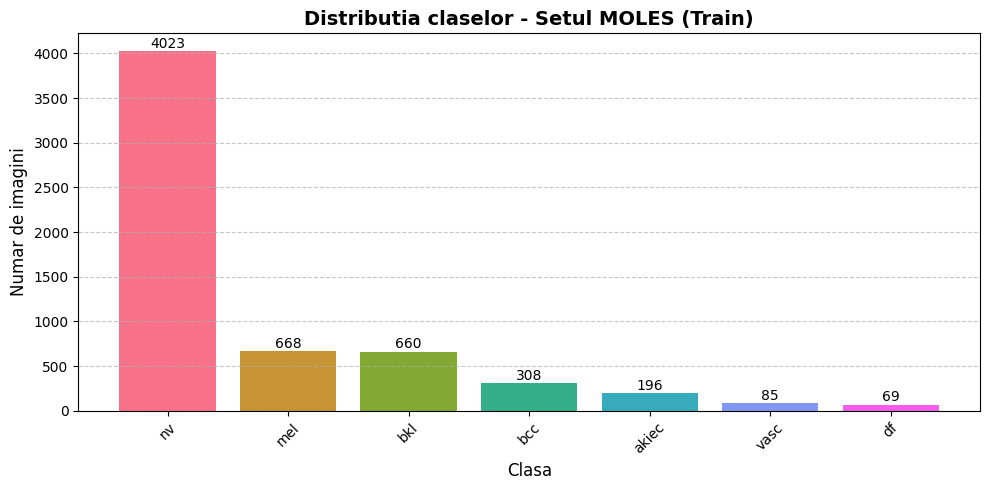

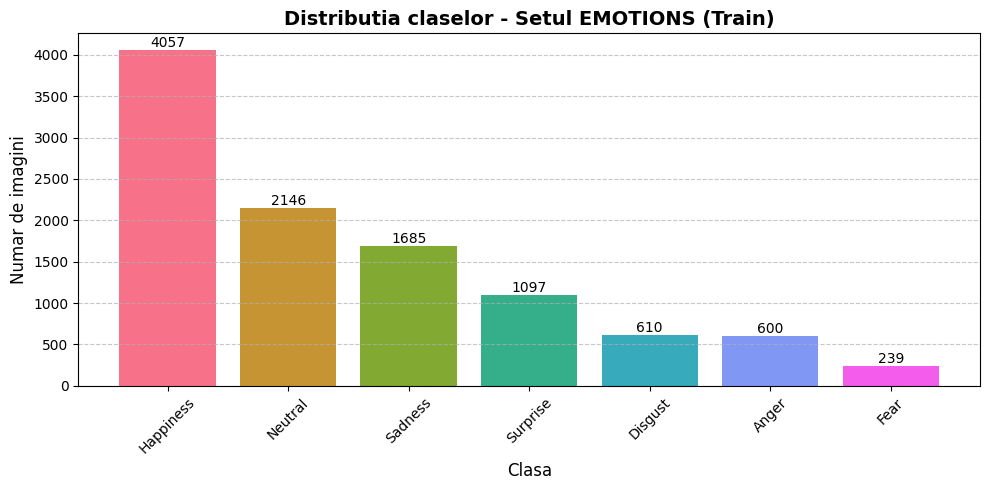

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_class_distribution(dataset, class_names, title):
    labels = dataset.get_labels()
    unique, counts = np.unique(labels, return_counts=True)
    if isinstance(class_names, dict):
        names = [class_names[i+1] for i in unique]
    else:
        names = [class_names[i] for i in unique]
    sorted_idx = np.argsort(counts)[::-1]
    sorted_names = [names[i] for i in sorted_idx]
    sorted_counts = [counts[i] for i in sorted_idx]
    plt.figure(figsize=(10, 5))
    colors = sns.color_palette("husl", len(sorted_names))
    bars = plt.bar(sorted_names, sorted_counts, color=colors)
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom', fontsize=10)

    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel("Clasa", fontsize=12)
    plt.ylabel("Numar de imagini", fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
# Pentru Alunite
plot_class_distribution(moles_train_ds, MOLES_CLASS_NAMES, "Distributia claselor - Setul MOLES (Train)")
# Pentru Emotii
plot_class_distribution(emotions_train_ds, EMOTIONS_CLASS_NAMES, "Distributia claselor - Setul EMOTIONS (Train)")

## 3.1.1 Vizualizare augmentari - cate o imagine per clasa

Pentru fiecare clasa selectam un sample si afisam:
- Imaginea **originala** (doar resize, fara augmentari)
- 4 augmentari **aleatoare** aplicate aceleiasi imagini

Asa putem vedea direct ce face pipeline-ul nostru de augmentari.


In [8]:
def visualize_augmentations(samples_dict, train_transform, eval_transform, mean, std, class_names_map, title, n_aug=4):
    # Calc dimensiunile tabelului de imagini:
    # Coloane = cate o clasa pe coloana
    # Randuri = 1 rand original + n_aug randuri de augmentari
    n_classes = len(samples_dict)
    n_cols = n_classes
    n_rows = n_aug + 1

    # Creare figura si axe (inversam proportiile de figsize ca sa arate bine)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.0 * n_cols, 2.0 * n_rows))

    # Daca am cere o singura augmentare sau e o singura clasa, forțăm axes sa fie un tablou 2D
    if n_rows == 1:
        axes = axes[None, :]
    if n_cols == 1:
        axes = axes[:, None]

    # Pregatire tensori pt denormalizare o singura data
    mean_t = torch.tensor(mean).view(3, 1, 1)
    std_t = torch.tensor(std).view(3, 1, 1)

    # Sortam cheile dict-ului ca sa pastram ordinea claselor
    sorted_items = sorted(samples_dict.items())

    # Parcurg fiecare clasa, care va fi o COLOANA
    for col, (lbl, path) in enumerate(sorted_items):
        cls_name = class_names_map[lbl]
        img_pil = Image.open(path).convert("RGB")

        # RANDUL 0: Procesez si desenez imaginea originala (fara augmentari)
        img_orig = eval_transform(img_pil)
        img_orig_denorm = (img_orig * std_t + mean_t).clamp(0, 1)

        axes[0, col].imshow(img_orig_denorm.permute(1, 2, 0))
        # Titlul se pune pe prima poza din fiecare coloana
        axes[0, col].set_title(f"{cls_name}\n(original)", fontsize=9)
        axes[0, col].axis("off")

        # RANDURILE 1..n_aug: Procesez si desenez augmentarile
        for row in range(1, n_rows):
            img_aug = train_transform(img_pil)
            img_aug_denorm = (img_aug * std_t + mean_t).clamp(0, 1)

            axes[row, col].imshow(img_aug_denorm.permute(1, 2, 0))
            axes[row, col].set_title(f"aug {row}", fontsize=9)
            axes[row, col].axis("off")

    fig.suptitle(title, fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

def pick_one_per_class(dataset, n_classes):
    """Returneaza un dict {label: path_imagine} cu cate un sample din fiecare clasa."""
    seen = {}
    for path, lbl in dataset.samples:
        if lbl not in seen:
            seen[lbl] = path
        if len(seen) == n_classes:
            break
    return seen

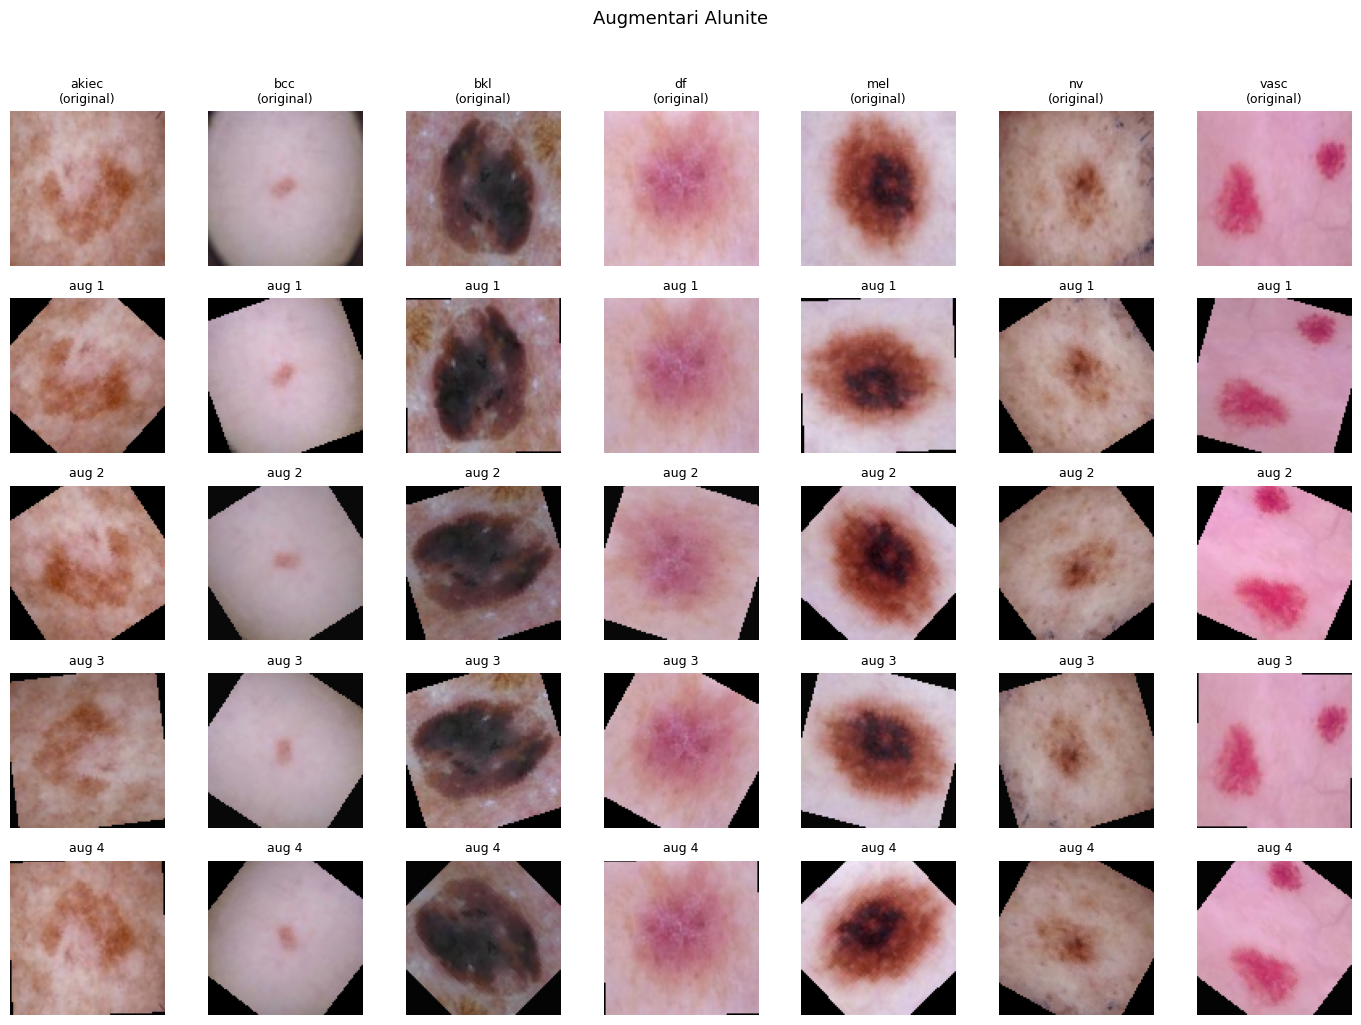

In [9]:

sample_moles = pick_one_per_class(moles_train_ds, n_classes=len(MOLES_CLASS_NAMES))
visualize_augmentations(
    samples_dict=sample_moles,
    train_transform=moles_train_transform,
    eval_transform=moles_eval_transform,
    mean=MOLES_MEAN,
    std=MOLES_STD,
    class_names_map=moles_train_ds.idx_to_class,
    title="Augmentari Alunite",
    n_aug=4
)

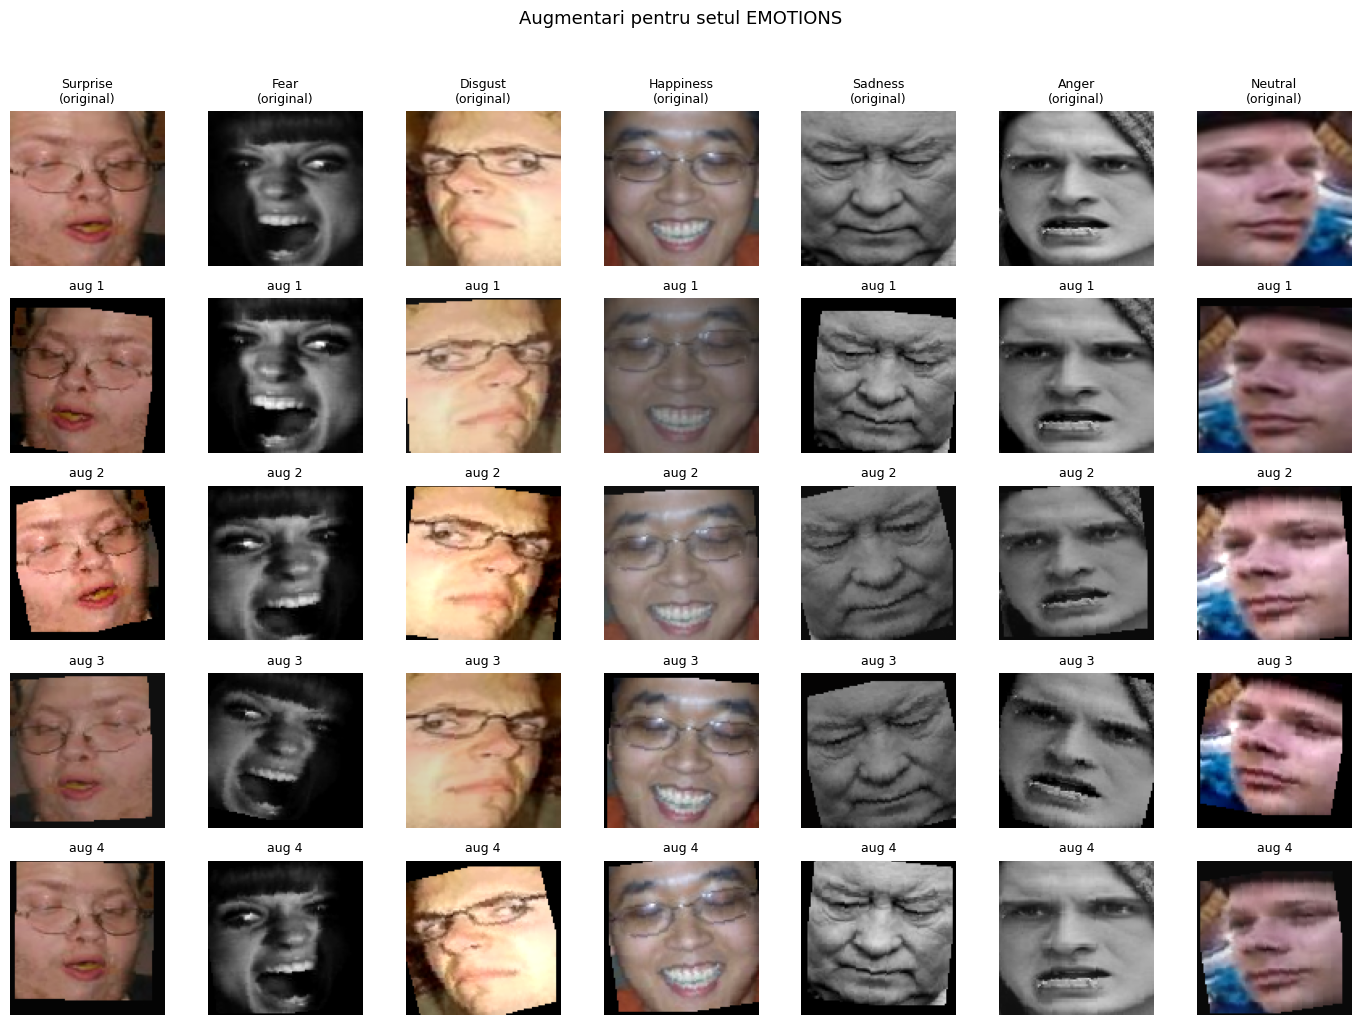

In [10]:
# Vizualizare EMOTII
emo_samples = pick_one_per_class(emotions_train_ds, n_classes=7)
emo_class_names_0idx = {k - 1: v for k, v in EMOTIONS_CLASS_NAMES.items()}
visualize_augmentations(
    samples_dict=emo_samples,
    train_transform=emotions_train_transform,
    eval_transform=emotions_eval_transform,
    mean=EMOTIONS_MEAN, std=EMOTIONS_STD,
    class_names_map=emo_class_names_0idx,
    title="Augmentari pentru setul EMOTIONS",
    n_aug=4,
)


# Cerinta 3.2: Arhitectura MLP

## Documentarea arhitecturii alese

Folosim aceeasi arhitectura MLP pe ambele probleme (singura diferenta: numarul de clase si statisticile de normalizare).

**Intrare**: imagine RGB 96x96 -> dupa Flatten = 27.648 features

**Bloc repetat** (de 3 ori, cu dimensiuni descrescatoare):
```
Linear(in -> out, bias=False)
BatchNorm1d(out)        # stabilizeaza antrenarea, permite lr mai mare
ReLU(inplace=True)
Dropout(p=0.3)          # regularizare (ablatie ceruta la 3.5)
```

**Capul de clasificare**: `Linear(256 -> num_classes)` - logits, fara activare (CrossEntropyLoss aplica softmax intern).

| Aspect | Alegere | Justificare |
|--------|---------|-------------|
| Numar straturi ascunse | 3 | Compromis: suficient pentru a invata reprezentari, nu prea mult ca sa overfit-ueze pe seturi mici (~10k imagini) |
| Dimensiuni | 1024 -> 512 -> 256 | Compresie progresiva tipica; primul strat este cel mai mare pt ca trebuie sa "absoarba" 27k de pixeli |
| Activare | ReLU | Standard, evita vanishing gradient, rapid de calculat |
| Normalizare | BatchNorm1d | Stabilizeaza antrenarea, accelereaza convergenta |
| Regularizare | Dropout 0.3 | Moderat - util pe seturi mici; este si subiectul ablatiei 3.5 |
| Bias la Linear | False inainte de BN | BN are deja parametrul `beta` care joaca rolul de bias |

**Hiperparametri de antrenare**:
- Optimizator: **Adam**, lr=1e-3, weight_decay=1e-4
- Scheduler: **CosineAnnealingLR** (lr scade lin la 0)
- Functie de loss: **CrossEntropyLoss** (clasificare multi-clasa)
- Batch size: **64**
- Epoci: **25**


In [11]:
class MLP(nn.Module):
    def __init__(self, num_classes, img_size=IMG_SIZE, in_channels=3,
                 hidden_dims=(1024, 512, 256), dropout=0.3, use_dropout=True, use_batchnorm=True):
        super().__init__()
        layers = [nn.Flatten()]
        in_dim = in_channels * img_size * img_size  # 3 * 96 * 96 = 27648 intrari

        for h in hidden_dims:
            layers.append(nn.Linear(in_dim, h, bias=not use_batchnorm))
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU(inplace=True))
            if use_dropout:
                layers.append(nn.Dropout(dropout))
            in_dim = h

        layers.append(nn.Linear(in_dim, num_classes))  # logits
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


## 3.2.1 Bucla de antrenare si evaluare

Implementam o bucla generica reutilizabila si pentru CNN-ul de la cerinta 3.3.


In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total_correct, total_seen = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss    += loss.item() * images.size(0)
        total_correct += (logits.argmax(1) == labels).sum().item()
        total_seen    += labels.size(0)
    return total_loss / total_seen, total_correct / total_seen


@torch.no_grad()
def evaluate(model, loader, criterion, device, return_preds=False):
    model.eval()
    total_loss, total_correct, total_seen = 0.0, 0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        preds = logits.argmax(1)

        total_loss    += loss.item() * images.size(0)
        total_correct += (preds == labels).sum().item()
        total_seen    += labels.size(0)
        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

    avg_loss = total_loss / total_seen
    avg_acc  = total_correct / total_seen
    if return_preds:
        return avg_loss, avg_acc, np.concatenate(all_preds), np.concatenate(all_labels)
    return avg_loss, avg_acc


def fit(model, train_loader, test_loader, num_epochs=25, lr=1e-3, weight_decay=1e-4,
        device=device, verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "lr": []}
    for epoch in range(num_epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        te_loss, te_acc = evaluate(model, test_loader, criterion, device)
        scheduler.step()

        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if verbose:
            print(f"Epoca {epoch+1:02d}/{num_epochs} | "
                  f"train loss={tr_loss:.4f} acc={tr_acc:.3f} | "
                  f"test loss={te_loss:.4f} acc={te_acc:.3f} | "
                  f"{time.time()-t0:.1f}s")
    return history


In [13]:
def plot_curves(history, title=""):
    """Ploteaza curbele de loss si accuracy (train + test pe acelasi grafic)."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(epochs, history["train_loss"], label="train", marker='o', markersize=3)
    axes[0].plot(epochs, history["test_loss"],  label="test",  marker='s', markersize=3)
    axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Loss - {title}"); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history["train_acc"], label="train", marker='o', markersize=3)
    axes[1].plot(epochs, history["test_acc"],  label="test",  marker='s', markersize=3)
    axes[1].set_xlabel("Epoca"); axes[1].set_ylabel("Accuracy")
    axes[1].set_title(f"Accuracy - {title}"); axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout(); plt.show()


def evaluate_full(model, loader, class_names, title="", device=device):
    """
    Calculeaza si afiseaza:
      - Accuracy
      - F1-macro si F1-micro
      - Matricea de confuzie (heatmap)
      - Classification report (per-clasa)
    """
    criterion = nn.CrossEntropyLoss()
    _, acc, preds, labels = evaluate(model, loader, criterion, device, return_preds=True)

    f1_macro = f1_score(labels, preds, average="macro", zero_division=0)
    f1_micro = f1_score(labels, preds, average="micro", zero_division=0)

    print(f"\n Rezultate pentru {title} ")
    print(f"Accuracy : {acc:.4f}")
    print(f"F1-macro : {f1_macro:.4f}")
    print(f"F1-micro : {f1_micro:.4f}")
    print("\nClassification report per-clasa:")
    print(classification_report(labels, preds, target_names=class_names, digits=4, zero_division=0))

    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="RdPu",
                xticklabels=class_names, yticklabels=class_names, cbar=False)
    plt.xlabel("Predictie"); plt.ylabel("Adevar")
    plt.title(f"Matrice de confuzie - {title}")
    plt.tight_layout(); plt.show()

    return {"acc": acc, "f1_macro": f1_macro, "f1_micro": f1_micro, "preds": preds, "labels": labels, "cm": cm}


## 3.2.2 Antrenare MLP pe setul MOLES

In [14]:
import torch._utils

In [15]:
import torch._utils
BATCH_SIZE = 64
NUM_EPOCHS = 25

moles_train_loader = DataLoader(moles_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
moles_test_loader  = DataLoader(moles_test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
moles_mlp = MLP(num_classes=len(MOLES_CLASS_NAMES),use_dropout=True, use_batchnorm=True).to(device)
print(f"Parametri MLP: {sum(p.numel() for p in moles_mlp.parameters()):,}")
moles_history = fit(moles_mlp, moles_train_loader, moles_test_loader, num_epochs=NUM_EPOCHS, lr=1e-3, weight_decay=1e-4)


Parametri MLP: 28,972,295
Epoca 01/25 | train loss=1.0595 acc=0.626 | test loss=0.9281 acc=0.676 | 39.1s
Epoca 02/25 | train loss=0.9199 acc=0.673 | test loss=0.8985 acc=0.683 | 11.4s
Epoca 03/25 | train loss=0.8986 acc=0.684 | test loss=0.8934 acc=0.682 | 11.5s
Epoca 04/25 | train loss=0.8867 acc=0.680 | test loss=0.8886 acc=0.693 | 11.2s
Epoca 05/25 | train loss=0.8765 acc=0.687 | test loss=0.8496 acc=0.703 | 11.2s
Epoca 06/25 | train loss=0.8731 acc=0.688 | test loss=0.8897 acc=0.687 | 11.2s
Epoca 07/25 | train loss=0.8556 acc=0.693 | test loss=0.8551 acc=0.702 | 11.3s
Epoca 08/25 | train loss=0.8505 acc=0.692 | test loss=0.8461 acc=0.703 | 11.5s
Epoca 09/25 | train loss=0.8392 acc=0.698 | test loss=0.8538 acc=0.696 | 11.3s
Epoca 10/25 | train loss=0.8412 acc=0.698 | test loss=0.8373 acc=0.701 | 11.2s
Epoca 11/25 | train loss=0.8295 acc=0.697 | test loss=0.8486 acc=0.698 | 11.2s
Epoca 12/25 | train loss=0.8212 acc=0.699 | test loss=0.8293 acc=0.706 | 11.4s
Epoca 13/25 | train loss=0

In [16]:
# Salvarea modelului pe disc
torch.save(moles_mlp.state_dict(), f"{WORK_DIR}/moles_mlp_best.pth")
np.save(f"{WORK_DIR}/moles_history.npy", moles_history)
print("Modelul si istoricul au fost salvate pe disc!")

Modelul si istoricul au fost salvate pe disc!


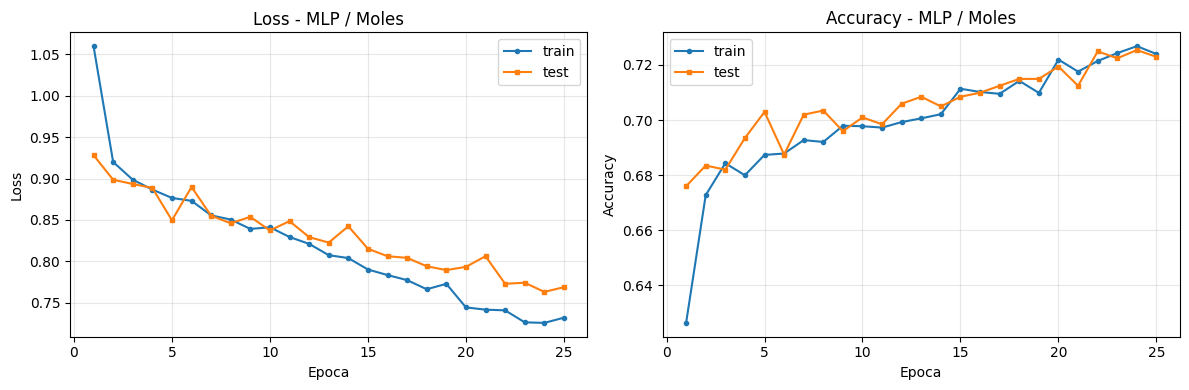


 Rezultate pentru MLP / Moles (test) 
Accuracy : 0.7229
F1-macro : 0.3500
F1-micro : 0.7229

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.4400    0.1692    0.2444        65
         bcc     0.5185    0.5437    0.5308       103
         bkl     0.5207    0.2864    0.3695       220
          df     0.0000    0.0000    0.0000        23
         mel     0.4348    0.0450    0.0816       222
          nv     0.7593    0.9694    0.8516      1341
        vasc     0.5714    0.2759    0.3721        29

    accuracy                         0.7229      2003
   macro avg     0.4635    0.3271    0.3500      2003
weighted avg     0.6630    0.7229    0.6604      2003



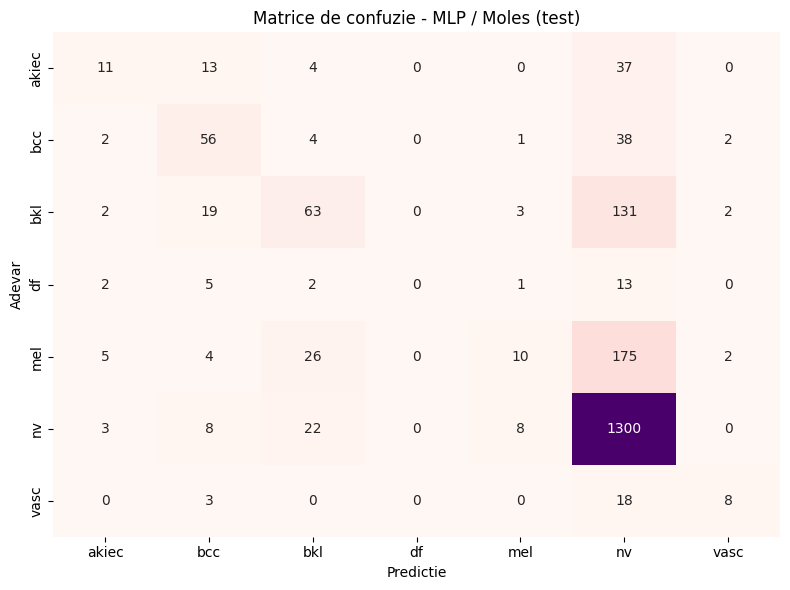

In [17]:
moles_mlp = MLP(num_classes=len(MOLES_CLASS_NAMES), use_dropout=True, use_batchnorm=True).to(device)
moles_mlp.load_state_dict(torch.load(f"{WORK_DIR}/moles_mlp_best.pth"))
moles_mlp.eval()
moles_history = np.load(f"{WORK_DIR}/moles_history.npy", allow_pickle=True).item()
plot_curves(moles_history, title="MLP / Moles")
moles_results = evaluate_full(moles_mlp, moles_test_loader, class_names=MOLES_CLASS_NAMES, title="MLP / Moles (test)")


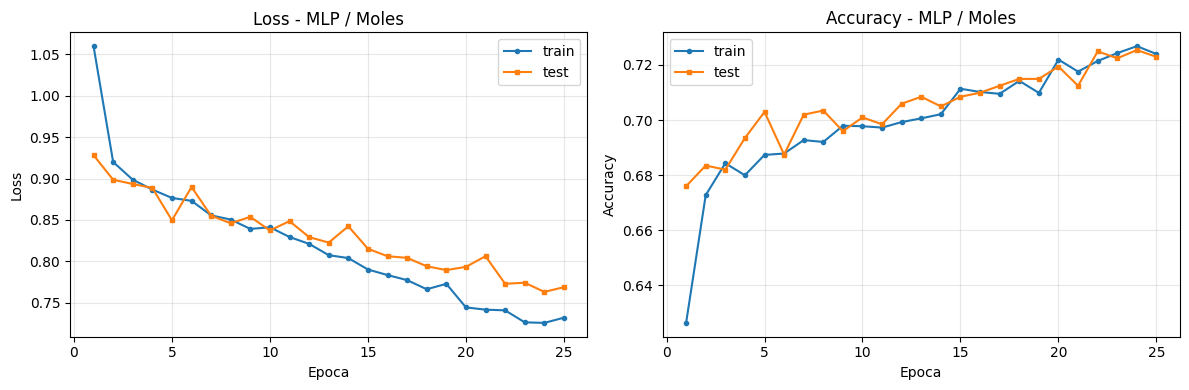


 Rezultate pentru MLP / Moles (test) 
Accuracy : 0.7229
F1-macro : 0.3500
F1-micro : 0.7229

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.4400    0.1692    0.2444        65
         bcc     0.5185    0.5437    0.5308       103
         bkl     0.5207    0.2864    0.3695       220
          df     0.0000    0.0000    0.0000        23
         mel     0.4348    0.0450    0.0816       222
          nv     0.7593    0.9694    0.8516      1341
        vasc     0.5714    0.2759    0.3721        29

    accuracy                         0.7229      2003
   macro avg     0.4635    0.3271    0.3500      2003
weighted avg     0.6630    0.7229    0.6604      2003



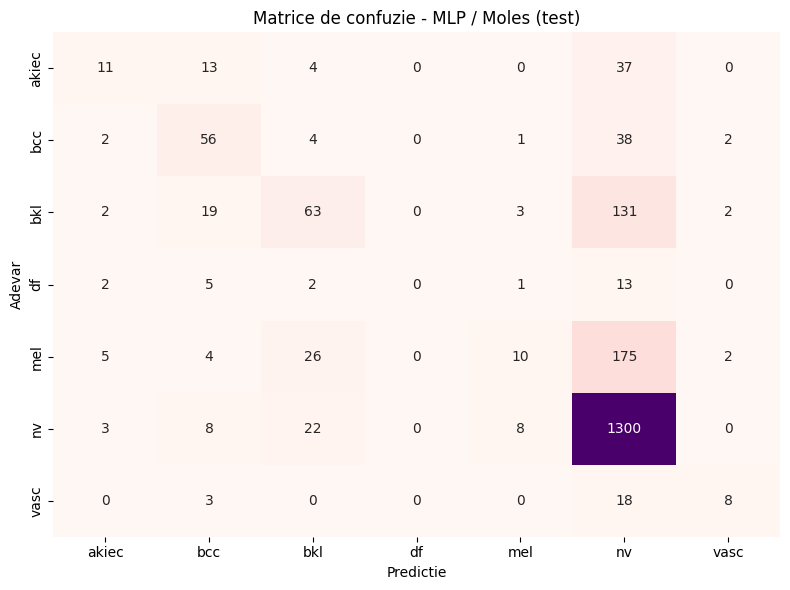

In [18]:
plot_curves(moles_history, title="MLP / Moles")
moles_results = evaluate_full(moles_mlp, moles_test_loader,class_names=MOLES_CLASS_NAMES, title="MLP / Moles (test)")


## 3.2.3 Antrenare MLP pe setul EMOTIONS

In [19]:
emo_train_loader = DataLoader(emotions_train_ds, batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=2, drop_last=True)
emo_test_loader  = DataLoader(emotions_test_ds,  batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=2)

emo_mlp = MLP(num_classes=len(EMOTIONS_CLASS_NAMES),
              use_dropout=True, use_batchnorm=True).to(device)
print(f"Parametri MLP: {sum(p.numel() for p in emo_mlp.parameters()):,}")

emo_history = fit(emo_mlp, emo_train_loader, emo_test_loader,
                  num_epochs=NUM_EPOCHS, lr=1e-3, weight_decay=1e-4)


Parametri MLP: 28,972,295
Epoca 01/25 | train loss=1.6057 acc=0.399 | test loss=1.3879 acc=0.476 | 53.4s
Epoca 02/25 | train loss=1.4581 acc=0.464 | test loss=1.3431 acc=0.474 | 17.9s
Epoca 03/25 | train loss=1.4185 acc=0.475 | test loss=1.2931 acc=0.536 | 17.7s
Epoca 04/25 | train loss=1.3855 acc=0.492 | test loss=1.2573 acc=0.536 | 18.8s
Epoca 05/25 | train loss=1.3709 acc=0.496 | test loss=1.2707 acc=0.537 | 20.1s
Epoca 06/25 | train loss=1.3577 acc=0.504 | test loss=1.2938 acc=0.519 | 17.9s
Epoca 07/25 | train loss=1.3491 acc=0.507 | test loss=1.2388 acc=0.561 | 17.8s
Epoca 08/25 | train loss=1.3328 acc=0.514 | test loss=1.2211 acc=0.557 | 17.7s
Epoca 09/25 | train loss=1.3267 acc=0.517 | test loss=1.2323 acc=0.571 | 17.7s
Epoca 10/25 | train loss=1.3140 acc=0.516 | test loss=1.2251 acc=0.556 | 17.5s
Epoca 11/25 | train loss=1.3116 acc=0.525 | test loss=1.2020 acc=0.562 | 17.9s
Epoca 12/25 | train loss=1.3053 acc=0.521 | test loss=1.1972 acc=0.572 | 17.6s
Epoca 13/25 | train loss=1

In [20]:
# Salvare model
torch.save(emo_mlp.state_dict(), f"{WORK_DIR}/emo_mlp_best.pth")
np.save(f"{WORK_DIR}/emo_history.npy", emo_history)
print("Modelul MLP Emotions și istoricul au fost salvate!")

Modelul MLP Emotions și istoricul au fost salvate!


In [21]:
emo_mlp = MLP(num_classes=len(EMOTIONS_CLASS_NAMES), 
              use_dropout=True, 
              use_batchnorm=True).to(device)
emo_mlp.load_state_dict(torch.load(f"{WORK_DIR}/emo_mlp_best.pth"))
emo_mlp.eval()
emo_history = np.load(f"{WORK_DIR}/emo_history.npy", allow_pickle=True).item()
print("Modelul si istoricul au fost încarcate. Poti rula evaluarile!")

Modelul si istoricul au fost încarcate. Poti rula evaluarile!


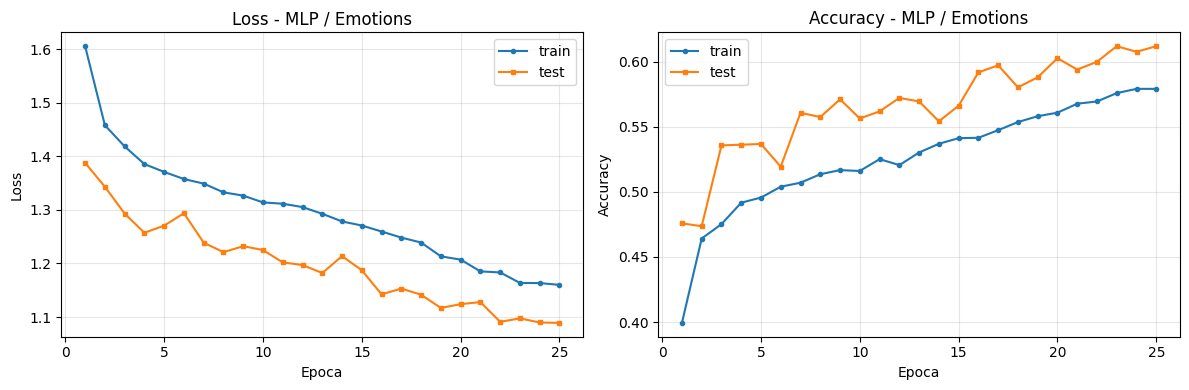


 Rezultate pentru MLP / Emotions (test) 
Accuracy : 0.6119
F1-macro : 0.4803
F1-micro : 0.6119

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.5676    0.5440    0.5556       193
        Fear     0.5625    0.2143    0.3103        42
     Disgust     0.4762    0.0935    0.1562       107
   Happiness     0.8252    0.7594    0.7910       715
     Sadness     0.4792    0.4646    0.4718       297
       Anger     0.5143    0.5143    0.5143       105
     Neutral     0.4699    0.7011    0.5626       378

    accuracy                         0.6119      1837
   macro avg     0.5564    0.4702    0.4803      1837
weighted avg     0.6250    0.6119    0.6039      1837



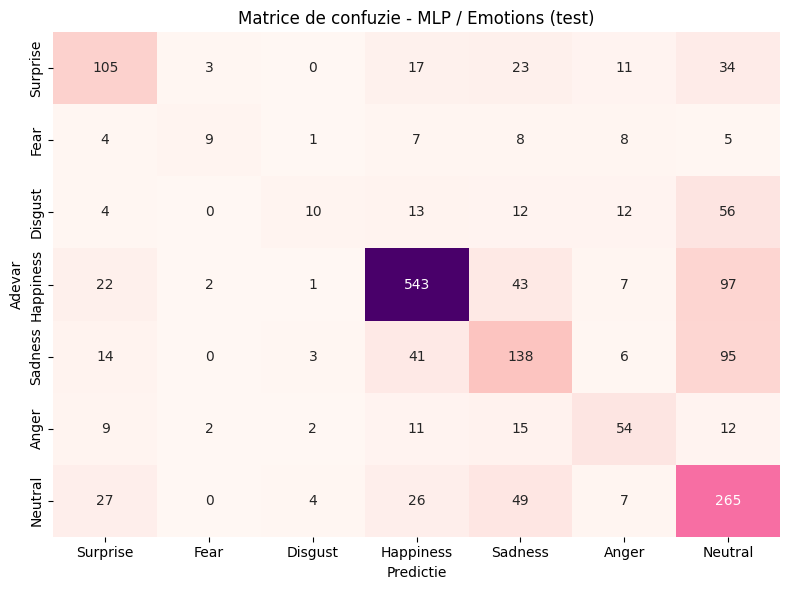

In [22]:
plot_curves(emo_history, title="MLP / Emotions")
emo_class_list = [EMOTIONS_CLASS_NAMES[k] for k in sorted(EMOTIONS_CLASS_NAMES)]
emo_results = evaluate_full(emo_mlp, emo_test_loader, class_names=emo_class_list, title="MLP / Emotions (test)")


## Salvarea modelelor (pentru cerintele urmatoare)

In [23]:
# Salvam state_dict-urile pentru a le folosi la ablatii (cerinta 3.5) sau ulterior
SAVE_DIR = f"{WORK_DIR}/models"
os.makedirs(SAVE_DIR, exist_ok=True)
torch.save(moles_mlp.state_dict(), f"{SAVE_DIR}/mlp_moles.pt")
torch.save(emo_mlp.state_dict(),   f"{SAVE_DIR}/mlp_emotions.pt")
# Salvam si historicile (pentru a putea regenera plot-urile fara a re-antrena)
import pickle
with open(f"{SAVE_DIR}/history_mlp_moles.pkl", "wb") as f:
    pickle.dump(moles_history, f)
with open(f"{SAVE_DIR}/history_mlp_emotions.pkl", "wb") as f:
    pickle.dump(emo_history, f)
print(f"Modele salvate in {SAVE_DIR}")

Modele salvate in /kaggle/working/models


## Observatii pentru raport

In raportul PDF, pentru fiecare set de date trebuie sa comentezi (cel putin 1-2 fraze):

1. **Curbele train/test** - exista overfit (train acc >> test acc) sau underfit (ambele mici)?
2. **Matricea de confuzie** - care clase sunt confundate intre ele?
   - La Moles: probabil `mel` (melanom) cu `nv` (alunita normala) - pericol diagnostic important
   - La Emotions: posibil `Surprise` cu `Fear`, sau `Sadness` cu `Neutral`
3. **Diferenta dintre accuracy si F1-macro** - pe seturile dezechilibrate (e.g. Moles cu 67% `nv`, Emotions cu 39% `Happiness`), daca F1-macro este mult mai mic decat accuracy, modelul prezice prea des clasele majoritare. Asta motiveaza ablatia 3.5 cu tehnici pentru dezechilibru.


# Cerinta 3.3: Arhitectura CNN

In [24]:
class SimpleCNN(nn.Module):
    """
    CNN comun pentru cele doua seturi de date.
    Respecta restrictiile: max 4 conv + max 2 linear.
    Args:
        num_classes: numarul de clase de iesire
        first_kernel: dimensiunea kernel-ului primului strat conv
            - 3 pentru Emotions (trasaturi faciale mici)
            - 5 pentru Moles (trasaturi dermatoscopice de scara mai mare)
        use_batchnorm: pentru ablatia 3.5 (cu / fara BN)
        dropout: probabilitate dropout in head-ul de clasificare
    """
    def __init__(self, num_classes, first_kernel=3, use_batchnorm=True, dropout=0.3):
        super().__init__()
        bn = use_batchnorm
        first_padding = first_kernel // 2  # 'same' padding (1 pt 3x3, 2 pt 5x5)

        def bn2d(c):
            return nn.BatchNorm2d(c) if bn else nn.Identity()

        self.features = nn.Sequential(
            # Block 1 - primul strat are kernel particularizat per dataset
            nn.Conv2d(3, 32, kernel_size=first_kernel, padding=first_padding, bias=not bn),
            bn2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 96 -> 48

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=not bn),
            bn2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 48 -> 24

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=not bn),
            bn2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 24 -> 12

            # Block 4 - fara pool, urmat de GAP
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=not bn),
            bn2d(256),
            nn.ReLU(inplace=True),

            # Global Average Pooling - face reteaua agnostica la rezolutia de intrare
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        # Head de clasificare: exact 2 straturi liniare (in conformitate cu restrictia)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128, bias=not bn),
            nn.BatchNorm1d(128) if bn else nn.Identity(),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

## 3.3.1 Antrenare CNN pe setul MOLES (kernel 5x5 in primul strat)

In [25]:
# CNN pe Moles - reutilizez data loaders deja construiti (moles_train_loader, moles_test_loader)
moles_cnn = SimpleCNN(num_classes=len(MOLES_CLASS_NAMES),
                      first_kernel=5,  # particularizare pentru moles
                      use_batchnorm=True,
                      dropout=0.3).to(device)
print(f"Parametri CNN (Moles): {sum(p.numel() for p in moles_cnn.parameters()):,}")

moles_cnn_history = fit(moles_cnn, moles_train_loader, moles_test_loader,
                        num_epochs=NUM_EPOCHS, lr=1e-3, weight_decay=1e-4)


Parametri CNN (Moles): 424,359
Epoca 01/25 | train loss=1.0995 acc=0.627 | test loss=0.8919 acc=0.687 | 15.2s
Epoca 02/25 | train loss=0.8852 acc=0.682 | test loss=0.8860 acc=0.700 | 11.3s
Epoca 03/25 | train loss=0.8423 acc=0.700 | test loss=0.7953 acc=0.716 | 11.4s
Epoca 04/25 | train loss=0.8039 acc=0.703 | test loss=0.8225 acc=0.706 | 11.2s
Epoca 05/25 | train loss=0.7880 acc=0.707 | test loss=0.8537 acc=0.709 | 11.4s
Epoca 06/25 | train loss=0.7706 acc=0.715 | test loss=0.7605 acc=0.719 | 11.1s
Epoca 07/25 | train loss=0.7533 acc=0.718 | test loss=0.7577 acc=0.723 | 11.4s
Epoca 08/25 | train loss=0.7368 acc=0.724 | test loss=0.7350 acc=0.729 | 11.4s
Epoca 09/25 | train loss=0.7245 acc=0.728 | test loss=0.7311 acc=0.723 | 11.3s
Epoca 10/25 | train loss=0.7102 acc=0.731 | test loss=0.7197 acc=0.721 | 11.3s
Epoca 11/25 | train loss=0.6952 acc=0.740 | test loss=0.6960 acc=0.734 | 11.2s
Epoca 12/25 | train loss=0.6827 acc=0.743 | test loss=0.7419 acc=0.727 | 11.3s
Epoca 13/25 | train l

In [26]:
# Salvare model CNN Moles
torch.save(moles_cnn.state_dict(), f"{WORK_DIR}/moles_cnn_best.pth")
np.save(f"{WORK_DIR}/moles_cnn_history.npy", moles_cnn_history)
print("Modelul CNN Moles si istoricul au fost salvate!")

Modelul CNN Moles si istoricul au fost salvate!


In [27]:
moles_cnn = SimpleCNN(num_classes=len(MOLES_CLASS_NAMES), 
                      first_kernel=5, 
                      use_batchnorm=True, 
                      dropout=0.3).to(device)
moles_cnn.load_state_dict(torch.load(f"{WORK_DIR}/moles_cnn_best.pth"))
moles_cnn.eval()
moles_cnn_history = np.load(f"{WORK_DIR}/moles_cnn_history.npy", allow_pickle=True).item()
print("Modelul si istoricul au fost incarcate.!")

Modelul si istoricul au fost incarcate.!


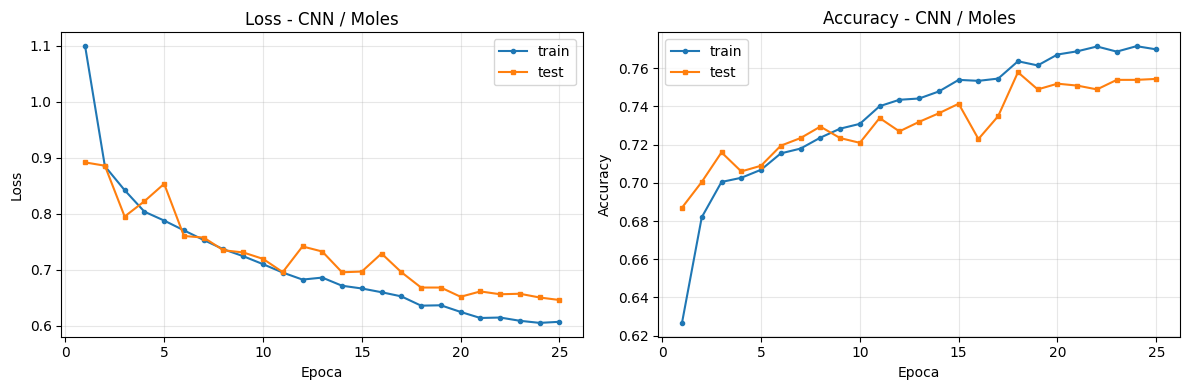


 Rezultate pentru CNN / Moles (test) 
Accuracy : 0.7544
F1-macro : 0.4505
F1-micro : 0.7544

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.3654    0.2923    0.3248        65
         bcc     0.6441    0.3689    0.4691       103
         bkl     0.4670    0.4818    0.4743       220
          df     0.0000    0.0000    0.0000        23
         mel     0.5203    0.3468    0.4162       222
          nv     0.8391    0.9374    0.8855      1341
        vasc     0.7368    0.4828    0.5833        29

    accuracy                         0.7544      2003
   macro avg     0.5104    0.4157    0.4505      2003
weighted avg     0.7264    0.7544    0.7342      2003



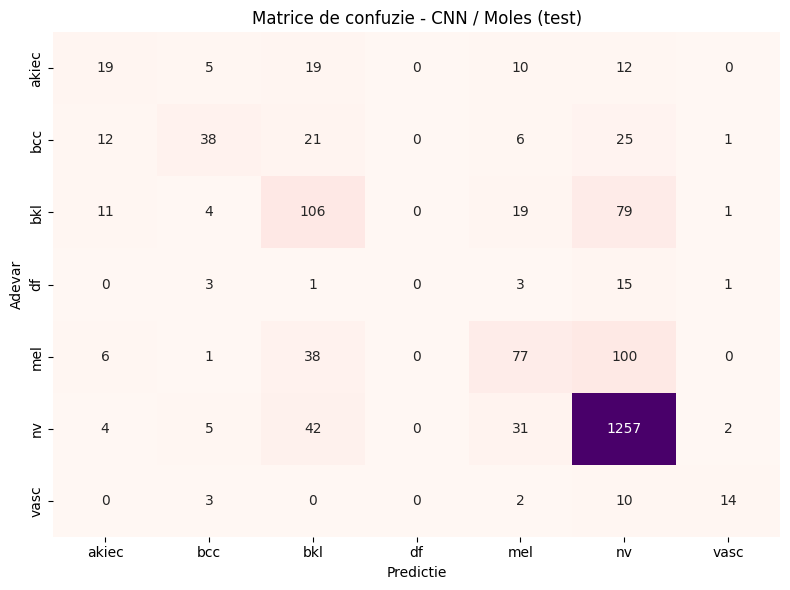

In [28]:
plot_curves(moles_cnn_history, title="CNN / Moles")
moles_cnn_results = evaluate_full(moles_cnn, moles_test_loader,
                                  class_names=MOLES_CLASS_NAMES,
                                  title="CNN / Moles (test)")

## 3.3.2 Antrenare CNN pe setul EMOTIONS (kernel 3x3 in primul strat)

In [29]:
# CNN pe Emotions - reutilizez data loaders deja construiti (emo_train_loader, emo_test_loader)
emo_cnn = SimpleCNN(num_classes=len(EMOTIONS_CLASS_NAMES),
                    first_kernel=3,  # particularizare pentru fete
                    use_batchnorm=True,
                    dropout=0.3).to(device)
print(f"Parametri CNN (Emotions): {sum(p.numel() for p in emo_cnn.parameters()):,}")

emo_cnn_history = fit(emo_cnn, emo_train_loader, emo_test_loader,
                      num_epochs=NUM_EPOCHS, lr=1e-3, weight_decay=1e-4)



Parametri CNN (Emotions): 422,823
Epoca 01/25 | train loss=1.6402 acc=0.387 | test loss=1.6750 acc=0.394 | 21.8s
Epoca 02/25 | train loss=1.5950 acc=0.397 | test loss=1.7117 acc=0.390 | 17.9s
Epoca 03/25 | train loss=1.5663 acc=0.405 | test loss=1.5542 acc=0.399 | 18.6s
Epoca 04/25 | train loss=1.5333 acc=0.426 | test loss=1.5351 acc=0.414 | 18.3s
Epoca 05/25 | train loss=1.4886 acc=0.440 | test loss=1.6185 acc=0.363 | 18.0s
Epoca 06/25 | train loss=1.4167 acc=0.474 | test loss=1.5289 acc=0.419 | 17.8s
Epoca 07/25 | train loss=1.3369 acc=0.511 | test loss=1.5208 acc=0.416 | 18.0s
Epoca 08/25 | train loss=1.2664 acc=0.537 | test loss=2.1121 acc=0.263 | 18.1s
Epoca 09/25 | train loss=1.1749 acc=0.577 | test loss=1.3319 acc=0.522 | 17.7s
Epoca 10/25 | train loss=1.1007 acc=0.602 | test loss=1.2902 acc=0.549 | 17.8s
Epoca 11/25 | train loss=1.0480 acc=0.625 | test loss=1.1733 acc=0.576 | 17.9s
Epoca 12/25 | train loss=0.9943 acc=0.641 | test loss=1.2906 acc=0.532 | 18.0s
Epoca 13/25 | trai

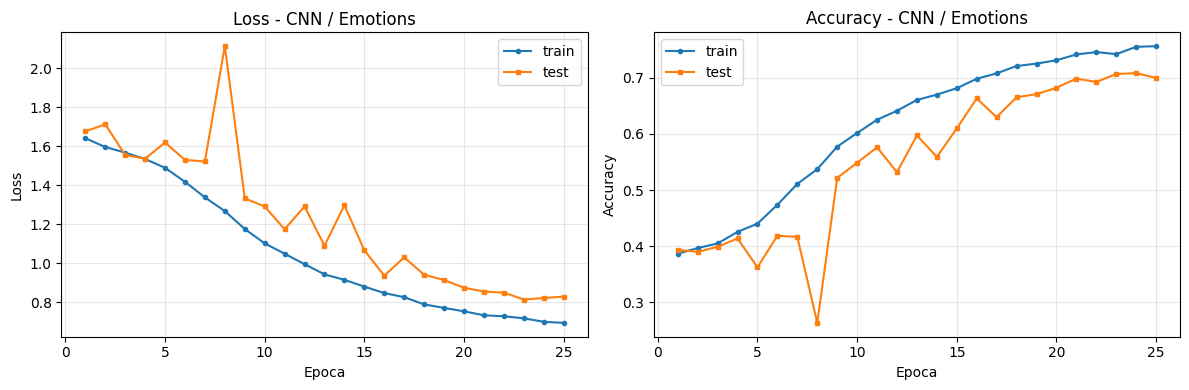


 Rezultate pentru CNN / Emotions (test) 
Accuracy : 0.6995
F1-macro : 0.5793
F1-micro : 0.6995

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.6840    0.7513    0.7160       193
        Fear     0.4545    0.2381    0.3125        42
     Disgust     0.4000    0.2991    0.3422       107
   Happiness     0.8930    0.8056    0.8471       715
     Sadness     0.5520    0.6431    0.5941       297
       Anger     0.5289    0.6095    0.5664       105
     Neutral     0.6496    0.7063    0.6768       378

    accuracy                         0.6995      1837
   macro avg     0.5946    0.5790    0.5793      1837
weighted avg     0.7063    0.6995    0.6997      1837



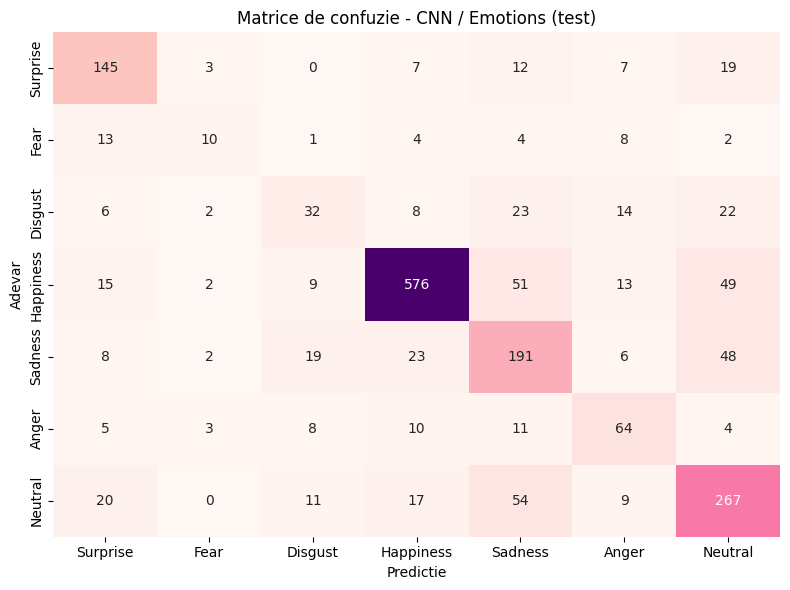

In [30]:
plot_curves(emo_cnn_history, title="CNN / Emotions")
emo_cnn_results = evaluate_full(emo_cnn, emo_test_loader,
                                class_names=emo_class_list,
                                title="CNN / Emotions (test)")

In [31]:
# 1. Salvarea modelului (checkpoint)
# Salvează "emo_cnn.pth" în folderul /kaggle/working
model_save_path = f"{WORK_DIR}/emo_cnn_best.pth"
torch.save(emo_cnn.state_dict(), model_save_path)
print(f"Modelul a fost salvat la: {model_save_path}")

Modelul a fost salvat la: /kaggle/working/emo_cnn_best.pth


## 3.3.3 Salvarea modelelor CNN si compararea cu MLP

In [32]:
# Salvez modelele CNN + historicile (pentru ablatii / fine-tuning ulterior)
torch.save(moles_cnn.state_dict(), f"{SAVE_DIR}/cnn_moles.pt")
torch.save(emo_cnn.state_dict(),   f"{SAVE_DIR}/cnn_emotions.pt")

import pickle
with open(f"{SAVE_DIR}/history_cnn_moles.pkl", "wb") as f:
    pickle.dump(moles_cnn_history, f)
with open(f"{SAVE_DIR}/history_cnn_emotions.pkl", "wb") as f:
    pickle.dump(emo_cnn_history, f)

print(f"Modele CNN salvate in {SAVE_DIR}")

# Tabel comparativ MLP vs CNN
print(f"{'Model':<25} {'Params':>12} {'Acc':>8} {'F1-macro':>10}")
print(f"{'MLP / Moles':<25} {sum(p.numel() for p in moles_mlp.parameters()):>12,} "
      f"{moles_results['acc']:>8.4f} {moles_results['f1_macro']:>10.4f}")
print(f"{'CNN / Moles':<25} {sum(p.numel() for p in moles_cnn.parameters()):>12,} "
      f"{moles_cnn_results['acc']:>8.4f} {moles_cnn_results['f1_macro']:>10.4f}")
print(f"{'MLP / Emotions':<25} {sum(p.numel() for p in emo_mlp.parameters()):>12,} "
      f"{emo_results['acc']:>8.4f} {emo_results['f1_macro']:>10.4f}")
print(f"{'CNN / Emotions':<25} {sum(p.numel() for p in emo_cnn.parameters()):>12,} "
      f"{emo_cnn_results['acc']:>8.4f} {emo_cnn_results['f1_macro']:>10.4f}")


Modele CNN salvate in /kaggle/working/models
Model                           Params      Acc   F1-macro
MLP / Moles                 28,972,295   0.7229     0.3500
CNN / Moles                    424,359   0.7544     0.4505
MLP / Emotions              28,972,295   0.6119     0.4803
CNN / Emotions                 422,823   0.6995     0.5793


# Cerinta 3.4: Fine-tuning pe o retea pre-antrenata

## Alegerea modelului

Folosesc **ResNet-18** pre-antrenat pe ImageNet. Motivatie:
- Arhitectura simpla, bine documentata, standard pentru transfer learning


In [212]:
# Pipeline-uri de transformari adaptate pentru fine-tuning pe ResNet18 (224x224)
IMG_SIZE_FT = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# MOLES — fine-tuning
moles_ft_train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE_FT, IMG_SIZE_FT)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=180),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
moles_ft_eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE_FT, IMG_SIZE_FT)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# EMOTIONS — fine-tuning
emo_ft_train_transform = transforms.Compose([
    transforms.Resize((232, 232)),                       
    transforms.RandomCrop(224),                           
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),                
    transforms.ColorJitter(brightness=0.2, contrast=0.2,
                           saturation=0.2, hue=0.05),      
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.1)), 
])
emo_ft_eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE_FT, IMG_SIZE_FT)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
print("Transforms pentru fine-tuning construite (224x224, ImageNet norm).")


Transforms pentru fine-tuning construite (224x224, ImageNet norm).


In [213]:
moles_ft_train_ds = MolesDataset(MOLES_TRAIN_CSV, MOLES_TRAIN_IMG_DIR,
                                 transform=moles_ft_train_transform)
moles_ft_test_ds  = MolesDataset(MOLES_TEST_CSV,  MOLES_TEST_IMG_DIR,
                                 transform=moles_ft_eval_transform)

emo_ft_train_ds = EmotionsDataset(EMOTIONS_TRAIN_CSV, EMOTIONS_IMG_ROOT,
                                  transform=emo_ft_train_transform)
emo_ft_test_ds  = EmotionsDataset(EMOTIONS_LOCAL_TEST_CSV, EMOTIONS_IMG_ROOT,
                                  transform=emo_ft_eval_transform)

# acelasi batch_size ca la MLP/CNN
BATCH_SIZE_FT = 64

moles_ft_train_loader = DataLoader(moles_ft_train_ds, batch_size=BATCH_SIZE_FT,
                                   shuffle=True, num_workers=2, drop_last=True)
moles_ft_test_loader  = DataLoader(moles_ft_test_ds,  batch_size=BATCH_SIZE_FT,
                                   shuffle=False, num_workers=2)
emo_ft_train_loader = DataLoader(emo_ft_train_ds, batch_size=BATCH_SIZE_FT,
                                 shuffle=True, num_workers=2, drop_last=True)
emo_ft_test_loader  = DataLoader(emo_ft_test_ds,  batch_size=BATCH_SIZE_FT,
                                 shuffle=False, num_workers=2)

print(f"Moles FT: train {len(moles_ft_train_ds)}, test {len(moles_ft_test_ds)}")
print(f"Emotions FT: train {len(emo_ft_train_ds)}, test {len(emo_ft_test_ds)}")


Dataset inițializat. S-au găsit 10434 poze valide!
Dataset inițializat. S-au găsit 1837 poze valide!
Moles FT: train 6009, test 2003
Emotions FT: train 10434, test 1837


In [215]:
import torchvision.models as models
from torch.optim.lr_scheduler import LambdaLR, CosineAnnealingLR, SequentialLR
from sklearn.metrics import f1_score
from torch.utils.data import WeightedRandomSampler
import time
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

def make_finetune_model(num_classes, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    if freeze_backbone:
        for name, param in model.named_parameters():
            param.requires_grad = name.startswith('fc.')
    return model

def mixup_batch(images, labels, alpha=0.2, device='cpu'):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(images.size(0)).to(device)
    mixed_images = lam * images + (1 - lam) * images[idx]
    return mixed_images, labels, labels[idx], lam

def fit_finetune(model, train_loader, test_loader,
                 num_epochs=20, backbone_lr=1e-4, head_lr=1e-3,
                 weight_decay=1e-4, warmup_epochs=3,
                 use_warmup=True, class_weights=None, label_smoothing=0.1,
                 use_mixup=False,  
                 device=device, verbose=True):

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=label_smoothing)

    backbone_params = [p for n, p in model.named_parameters() if not n.startswith('fc.') and p.requires_grad]
    head_params = [p for n, p in model.named_parameters() if n.startswith('fc.') and p.requires_grad]
    
    param_groups = []
    if backbone_params:
        param_groups.append({'params': backbone_params, 'lr': backbone_lr})
    param_groups.append({'params': head_params, 'lr': head_lr})
    optimizer = optim.AdamW(param_groups, weight_decay=weight_decay)

    if use_warmup and warmup_epochs > 0:
        warmup = LambdaLR(optimizer, lr_lambda=lambda e: (e + 1) / warmup_epochs)
        cosine = CosineAnnealingLR(optimizer, T_max=num_epochs - warmup_epochs, eta_min=1e-6)
        scheduler = SequentialLR(optimizer, [warmup, cosine], milestones=[warmup_epochs])
    else:
        scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)

    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "lr_backbone": [], "lr_head": [], "test_f1": []}
    best_f1 = 0.0

    for epoch in range(num_epochs):
        t0 = time.time()
        # TRAIN
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            
            # --- LOGICA DE MIXUP ---
            if use_mixup:
                images_mix, y_a, y_b, lam = mixup_batch(images, labels, alpha=0.2, device=device)
                logits = model(images_mix)
                loss = lam * criterion(logits, y_a) + (1 - lam) * criterion(logits, y_b)
                correct += (logits.argmax(1) == y_a).sum().item() 
            else:
                logits = model(images)
                loss = criterion(logits, labels)
                correct += (logits.argmax(1) == labels).sum().item()

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * images.size(0)
            total += labels.size(0)
            
        tr_loss, tr_acc = total_loss / total, correct / total

        # EVAL
        te_loss, te_acc = evaluate(model, test_loader, nn.CrossEntropyLoss(), device)
        scheduler.step()

        # F1-macro pe test
        model.eval()
        all_p, all_l = [], []
        with torch.no_grad():
            for imgs, lbls in test_loader:
                all_p.append(model(imgs.to(device)).argmax(1).cpu().numpy())
                all_l.append(lbls.numpy())
        te_f1 = f1_score(np.concatenate(all_l), np.concatenate(all_p), average='macro')

        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss); history["test_acc"].append(te_acc)
        history["test_f1"].append(te_f1)
        
        if len(optimizer.param_groups) == 2:
            history["lr_backbone"].append(optimizer.param_groups[0]['lr'])
            history["lr_head"].append(optimizer.param_groups[1]['lr'])
        else:
            history["lr_backbone"].append(0.0)
            history["lr_head"].append(optimizer.param_groups[0]['lr'])

        marker = ""
        # cel mai bun model bazat pe F1-Macro
        if te_f1 > best_f1:
            best_f1 = te_f1
            torch.save(model.state_dict(), f"{WORK_DIR}/best_ft.pt")
            marker = " *BEST*"

        if verbose:
            print(f"Ep {epoch+1:02d}/{num_epochs} | train loss={tr_loss:.4f} acc={tr_acc:.3f} | "
                  f"test acc={te_acc:.3f} F1={te_f1:.4f}{marker} | {time.time()-t0:.1f}s")

    model.load_state_dict(torch.load(f"{WORK_DIR}/best_ft.pt"))
    print(f"\nBest F1-macro: {best_f1:.4f}")
    return history

## 3.4.1 Fine-tuning ResNet18 pe setul MOLES

In [202]:
moles_ft = make_finetune_model(num_classes=len(MOLES_CLASS_NAMES), freeze_backbone=False).to(device)

moles_ft_history = fit_finetune(moles_ft, moles_ft_train_loader, moles_ft_test_loader,
                                num_epochs=40,
                                backbone_lr=5e-5, head_lr=1e-3,
                                warmup_epochs=5, use_warmup=True,
                                use_mixup=False)

Ep 01/40 | train loss=1.1831 acc=0.655 | test acc=0.698 F1=0.2666 *BEST* | 32.4s
Ep 02/40 | train loss=0.9960 acc=0.738 | test acc=0.758 F1=0.4178 *BEST* | 28.6s
Ep 03/40 | train loss=0.9263 acc=0.770 | test acc=0.782 F1=0.5223 *BEST* | 28.3s
Ep 04/40 | train loss=0.8858 acc=0.794 | test acc=0.788 F1=0.5995 *BEST* | 27.9s
Ep 05/40 | train loss=0.8597 acc=0.805 | test acc=0.759 F1=0.5785 | 29.1s
Ep 06/40 | train loss=0.8388 acc=0.814 | test acc=0.804 F1=0.6253 *BEST* | 29.9s
Ep 07/40 | train loss=0.8110 acc=0.830 | test acc=0.807 F1=0.6506 *BEST* | 29.2s
Ep 08/40 | train loss=0.7897 acc=0.837 | test acc=0.808 F1=0.6477 | 29.2s
Ep 09/40 | train loss=0.7655 acc=0.849 | test acc=0.807 F1=0.6466 | 28.9s
Ep 10/40 | train loss=0.7461 acc=0.861 | test acc=0.817 F1=0.6677 *BEST* | 29.1s
Ep 11/40 | train loss=0.7324 acc=0.871 | test acc=0.828 F1=0.6695 *BEST* | 29.0s
Ep 12/40 | train loss=0.7198 acc=0.877 | test acc=0.820 F1=0.6672 | 28.6s
Ep 13/40 | train loss=0.7034 acc=0.887 | test acc=0.825 

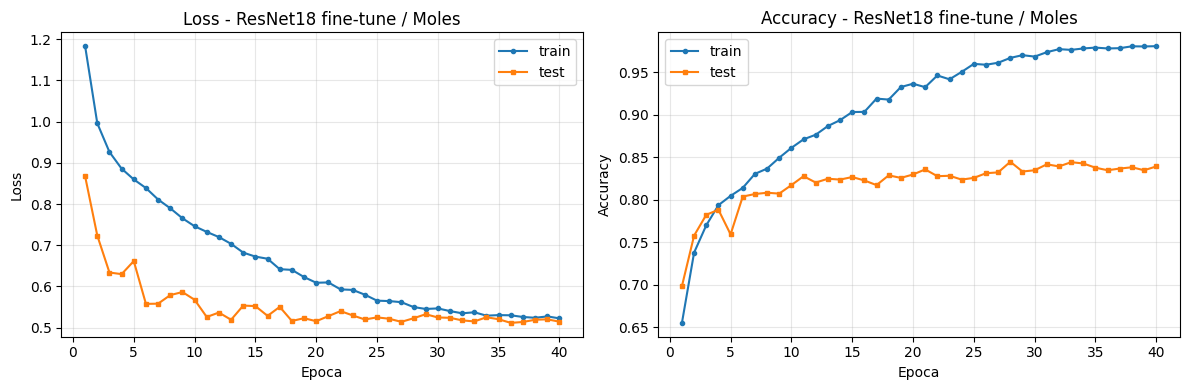

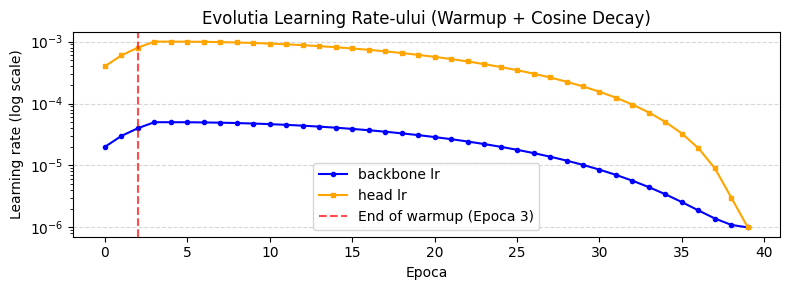


 Rezultate pentru ResNet18 fine-tune / Moles (test) 
Accuracy : 0.8417
F1-macro : 0.7344
F1-micro : 0.8417

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.6500    0.6000    0.6240        65
         bcc     0.7069    0.7961    0.7489       103
         bkl     0.6959    0.6136    0.6522       220
          df     0.9286    0.5652    0.7027        23
         mel     0.5966    0.6396    0.6174       222
          nv     0.9226    0.9336    0.9281      1341
        vasc     0.9583    0.7931    0.8679        29

    accuracy                         0.8417      2003
   macro avg     0.7798    0.7059    0.7344      2003
weighted avg     0.8422    0.8417    0.8408      2003



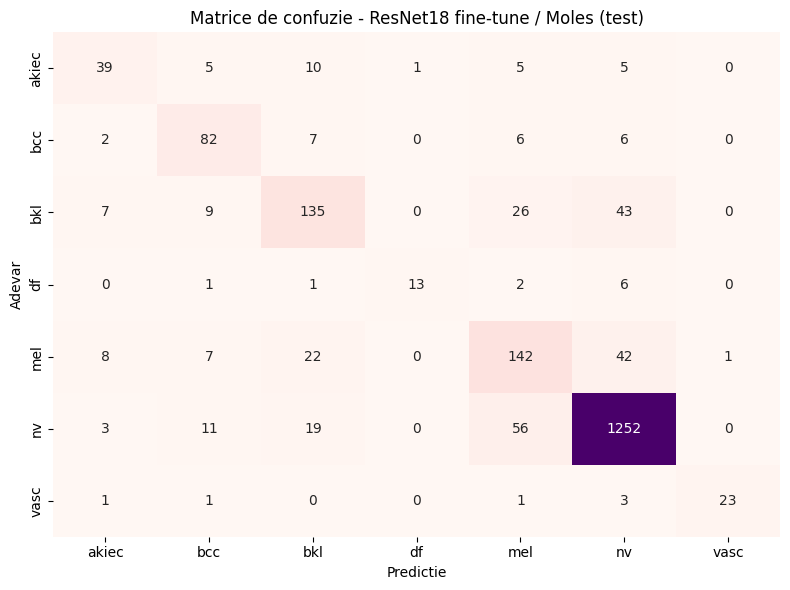

In [216]:
plot_curves(moles_ft_history, title="ResNet18 fine-tune / Moles")
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(moles_ft_history["lr_backbone"], label="backbone lr", marker='o', markersize=3, color='blue')
plt.plot(moles_ft_history["lr_head"], label="head lr", marker='s', markersize=3, color='orange')
plt.axvline(x=3 - 1, color='red', linestyle='--', alpha=0.7, label="End of warmup (Epoca 3)")

plt.xlabel("Epoca")
plt.ylabel("Learning rate (log scale)")
plt.yscale('log')
plt.title("Evolutia Learning Rate-ului (Warmup + Cosine Decay)")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

moles_ft_results = evaluate_full(moles_ft, moles_ft_test_loader,
                                 class_names=MOLES_CLASS_NAMES,
                                 title="ResNet18 fine-tune / Moles (test)")

## 3.4.2 Fine-tuning ResNet18 pe setul EMOTIONS

In [221]:
emo_labels = emo_ft_train_ds.get_labels()
emo_counts = np.bincount(emo_labels)
sample_weights = 1.0 / emo_counts[emo_labels]
sampler = WeightedRandomSampler(torch.from_numpy(sample_weights).double(),
                                num_samples=len(emo_labels), replacement=True)
emo_ft_balanced_loader = DataLoader(emo_ft_train_ds, batch_size=32,       # ← 32 nu 64
                                     sampler=sampler, num_workers=2, drop_last=True)

emo_ft = make_finetune_model(num_classes=len(EMOTIONS_CLASS_NAMES),
                              freeze_backbone=False).to(device)

emo_ft_history = fit_finetune(emo_ft, emo_ft_balanced_loader, emo_ft_test_loader,
                              num_epochs=80,       
                              backbone_lr=5e-5, head_lr=1e-3,
                              warmup_epochs=5, use_warmup=True,
                              use_mixup=True)

Ep 01/80 | train loss=1.7661 acc=0.266 | test acc=0.440 F1=0.3714 *BEST* | 65.5s
Ep 02/80 | train loss=1.4869 acc=0.362 | test acc=0.581 F1=0.4896 *BEST* | 61.8s
Ep 03/80 | train loss=1.3149 acc=0.395 | test acc=0.669 F1=0.5751 *BEST* | 59.9s
Ep 04/80 | train loss=1.2230 acc=0.467 | test acc=0.714 F1=0.6282 *BEST* | 59.3s
Ep 05/80 | train loss=1.1369 acc=0.471 | test acc=0.662 F1=0.5978 | 59.1s
Ep 06/80 | train loss=1.0775 acc=0.494 | test acc=0.702 F1=0.6141 | 59.0s
Ep 07/80 | train loss=1.0448 acc=0.490 | test acc=0.715 F1=0.6518 *BEST* | 60.0s
Ep 08/80 | train loss=0.9970 acc=0.522 | test acc=0.764 F1=0.6737 *BEST* | 59.6s
Ep 09/80 | train loss=0.9626 acc=0.511 | test acc=0.759 F1=0.6613 | 60.2s
Ep 10/80 | train loss=0.9543 acc=0.522 | test acc=0.779 F1=0.7036 *BEST* | 60.7s
Ep 11/80 | train loss=0.9515 acc=0.509 | test acc=0.776 F1=0.6774 | 60.9s
Ep 12/80 | train loss=0.8897 acc=0.557 | test acc=0.775 F1=0.6941 | 59.5s
Ep 13/80 | train loss=0.8919 acc=0.573 | test acc=0.789 F1=0.69

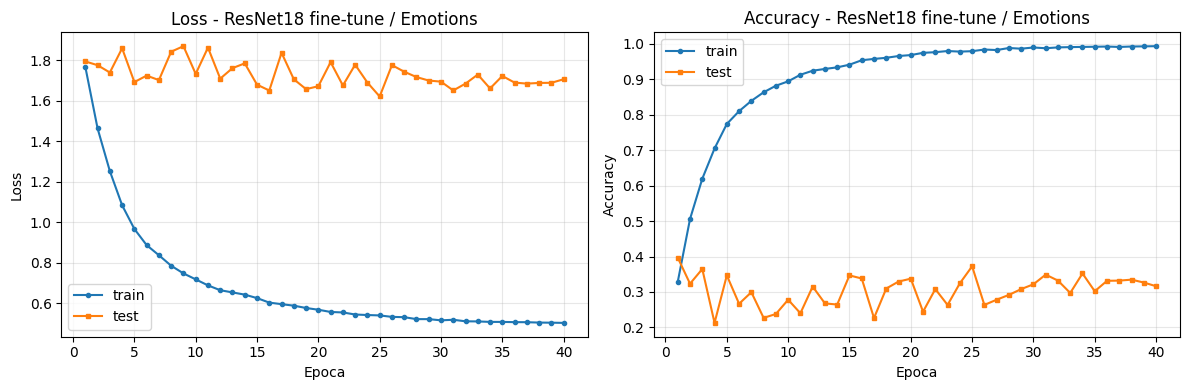

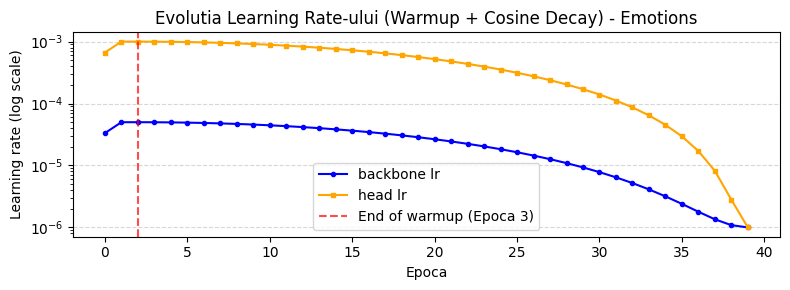


 Rezultate pentru ResNet18 fine-tune / Emotions (test) 
Accuracy : 0.8122
F1-macro : 0.7074
F1-micro : 0.8122

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.8316    0.8446    0.8380       193
        Fear     0.6154    0.3810    0.4706        42
     Disgust     0.5867    0.4112    0.4835       107
   Happiness     0.9228    0.9189    0.9208       715
     Sadness     0.7882    0.7643    0.7761       297
       Anger     0.6667    0.7238    0.6941       105
     Neutral     0.7254    0.8175    0.7687       378

    accuracy                         0.8122      1837
   macro avg     0.7338    0.6945    0.7074      1837
weighted avg     0.8096    0.8122    0.8087      1837



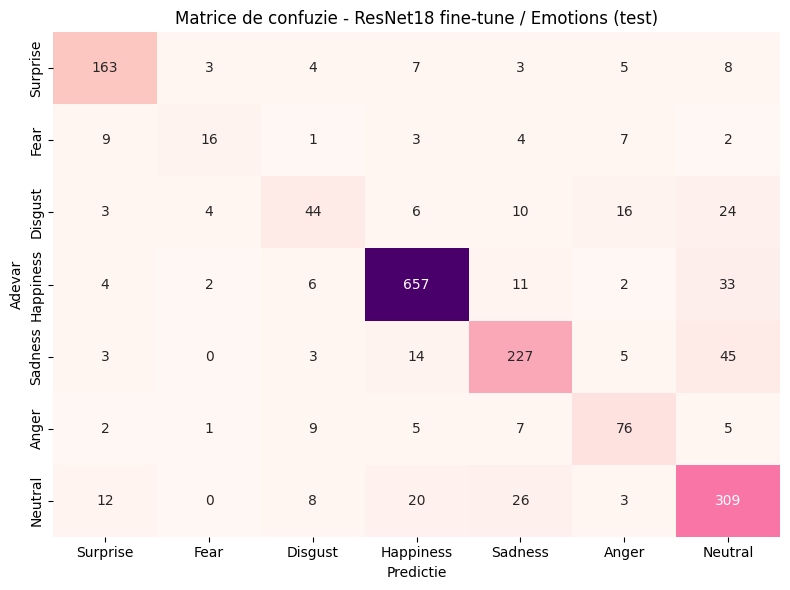

In [130]:
# curbele de Loss si Accuracy pentru Emotions
plot_curves(emo_ft_history, title="ResNet18 fine-tune / Emotions")
plt.show()

#evolutia LR-ului
plt.figure(figsize=(8, 3))
plt.plot(emo_ft_history["lr_backbone"], label="backbone lr", marker='o', markersize=3, color='blue')
plt.plot(emo_ft_history["lr_head"], label="head lr", marker='s', markersize=3, color='orange')
plt.axvline(x=3 - 1, color='red', linestyle='--', alpha=0.7, label="End of warmup (Epoca 3)")

plt.xlabel("Epoca")
plt.ylabel("Learning rate (log scale)")
plt.yscale('log')
plt.title("Evolutia Learning Rate-ului (Warmup + Cosine Decay) - Emotions")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Matricea de Confuzie
emo_ft_results = evaluate_full(emo_ft, emo_ft_test_loader,
                               class_names=emo_class_list,
                               title="ResNet18 fine-tune / Emotions (test)")

## 3.4.3 Salvare modele si comparatie cu MLP / CNN

In [204]:
torch.save(moles_ft.state_dict(), f"{SAVE_DIR}/resnet18_moles.pt")
torch.save(emo_ft.state_dict(),   f"{SAVE_DIR}/resnet18_emotions.pt")
with open(f"{SAVE_DIR}/history_resnet18_moles.pkl", "wb") as f:
    pickle.dump(moles_ft_history, f)
with open(f"{SAVE_DIR}/history_resnet18_emotions.pkl", "wb") as f:
    pickle.dump(emo_ft_history, f)

print(f"Modele fine-tuned salvate in {SAVE_DIR}")

# Tabel comparativ
print(f"{'Model':<30} {'Params':>12} {'Acc':>8} {'F1-macro':>10}")
print(f"{'MLP / Moles':<30} {sum(p.numel() for p in moles_mlp.parameters()):>12,} "
      f"{moles_results['acc']:>8.4f} {moles_results['f1_macro']:>10.4f}")
print(f"{'CNN / Moles':<30} {sum(p.numel() for p in moles_cnn.parameters()):>12,} "
      f"{moles_cnn_results['acc']:>8.4f} {moles_cnn_results['f1_macro']:>10.4f}")
print(f"{'ResNet18 (FT) / Moles':<30} {sum(p.numel() for p in moles_ft.parameters()):>12,} "
      f"{moles_ft_results['acc']:>8.4f} {moles_ft_results['f1_macro']:>10.4f}")
print(f"{'MLP / Emotions':<30} {sum(p.numel() for p in emo_mlp.parameters()):>12,} "
      f"{emo_results['acc']:>8.4f} {emo_results['f1_macro']:>10.4f}")
print(f"{'CNN / Emotions':<30} {sum(p.numel() for p in emo_cnn.parameters()):>12,} "
      f"{emo_cnn_results['acc']:>8.4f} {emo_cnn_results['f1_macro']:>10.4f}")
print(f"{'ResNet18 (FT) / Emotions':<30} {sum(p.numel() for p in emo_ft.parameters()):>12,} "
      f"{emo_ft_results['acc']:>8.4f} {emo_ft_results['f1_macro']:>10.4f}")


Modele fine-tuned salvate in /kaggle/working/models
Model                                Params      Acc   F1-macro
MLP / Moles                      28,972,295   0.7229     0.3500
CNN / Moles                         424,359   0.7544     0.4505
ResNet18 (FT) / Moles            11,180,103   0.8417     0.7344
MLP / Emotions                   28,972,295   0.6119     0.4803
CNN / Emotions                      422,823   0.6995     0.5793
ResNet18 (FT) / Emotions         11,180,103   0.8122     0.7074


# Cerinta 3.5: Rezultatele antrenarii evaluate prin ablatii

In [41]:
def print_ablation_table(results_dict, title=""):
    """Tabel formatat cu metricile pentru fiecare varianta a unei ablatii."""
    print(f"{title}")
    print(f"{'Varianta':<40} {'Acc':>10} {'F1-macro':>10} {'F1-micro':>10}")
    for name, r in results_dict.items():
        print(f"{name:<40} {r['acc']:>10.4f} {r['f1_macro']:>10.4f} {r['f1_micro']:>10.4f}")

def plot_ablation_curves(histories_dict, title="", metric="test_acc"):
    """Plot suprapus pentru curbele de test_acc/test_loss ale variantelor unei ablatii."""
    plt.figure(figsize=(10, 4))
    for name, h in histories_dict.items():
        plt.plot(range(1, len(h[metric]) + 1), h[metric], label=name, marker='o', markersize=3)
    plt.xlabel("Epoca")
    plt.ylabel(metric)
    plt.title(f"{metric} - {title}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_ablation_curves_grid(histories_dict, title=""):
    """Plot 2x2: train/test loss/acc pentru toate variantele."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in histories_dict.items():
        axes[0].plot(h["test_loss"], label=name, marker='o', markersize=3)
        axes[1].plot(h["test_acc"], label=name, marker='o', markersize=3)
    axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Test Loss")
    axes[0].set_title(f"Test Loss - {title}"); axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].set_xlabel("Epoca"); axes[1].set_ylabel("Test Accuracy")
    axes[1].set_title(f"Test Accuracy - {title}"); axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


## 3.5.1 Ablatie: MLP cu / fara Dropout

In [42]:
# MLP FARA dropout pe Moles
moles_mlp_nodrop = MLP(num_classes=len(MOLES_CLASS_NAMES),
                       use_dropout=False, use_batchnorm=True).to(device)
print(f"Parametri MLP no-drop: {sum(p.numel() for p in moles_mlp_nodrop.parameters()):,}")
moles_mlp_nodrop_history = fit(moles_mlp_nodrop, moles_train_loader, moles_test_loader,
                               num_epochs=NUM_EPOCHS, lr=1e-3, weight_decay=1e-4)


Parametri MLP no-drop: 28,972,295
Epoca 01/25 | train loss=1.0299 acc=0.640 | test loss=0.9340 acc=0.680 | 15.0s
Epoca 02/25 | train loss=0.9023 acc=0.683 | test loss=0.9101 acc=0.684 | 11.9s
Epoca 03/25 | train loss=0.8779 acc=0.686 | test loss=0.8863 acc=0.684 | 11.7s
Epoca 04/25 | train loss=0.8713 acc=0.686 | test loss=0.9140 acc=0.680 | 11.2s
Epoca 05/25 | train loss=0.8544 acc=0.695 | test loss=0.8562 acc=0.702 | 11.6s
Epoca 06/25 | train loss=0.8402 acc=0.695 | test loss=0.8625 acc=0.692 | 11.6s
Epoca 07/25 | train loss=0.8359 acc=0.694 | test loss=0.9129 acc=0.681 | 11.6s
Epoca 08/25 | train loss=0.8288 acc=0.699 | test loss=0.9458 acc=0.695 | 11.7s
Epoca 09/25 | train loss=0.8150 acc=0.704 | test loss=0.8349 acc=0.699 | 11.3s
Epoca 10/25 | train loss=0.7943 acc=0.705 | test loss=0.8269 acc=0.701 | 11.5s
Epoca 11/25 | train loss=0.7904 acc=0.708 | test loss=0.8169 acc=0.707 | 11.9s
Epoca 12/25 | train loss=0.7775 acc=0.712 | test loss=0.8136 acc=0.705 | 11.4s
Epoca 13/25 | trai

In [43]:
# MLP FARA dropout pe Emotions
emo_mlp_nodrop = MLP(num_classes=len(EMOTIONS_CLASS_NAMES),
                     use_dropout=False, use_batchnorm=True).to(device)
emo_mlp_nodrop_history = fit(emo_mlp_nodrop, emo_train_loader, emo_test_loader,
                             num_epochs=NUM_EPOCHS, lr=1e-3, weight_decay=1e-4)


Epoca 01/25 | train loss=1.5540 acc=0.422 | test loss=1.3486 acc=0.500 | 25.7s
Epoca 02/25 | train loss=1.4219 acc=0.479 | test loss=1.3397 acc=0.504 | 18.4s
Epoca 03/25 | train loss=1.3872 acc=0.494 | test loss=1.2959 acc=0.529 | 18.3s
Epoca 04/25 | train loss=1.3518 acc=0.506 | test loss=1.2544 acc=0.538 | 18.1s
Epoca 05/25 | train loss=1.3203 acc=0.515 | test loss=1.2667 acc=0.540 | 18.8s
Epoca 06/25 | train loss=1.3006 acc=0.523 | test loss=1.2293 acc=0.557 | 18.2s
Epoca 07/25 | train loss=1.2993 acc=0.524 | test loss=1.2531 acc=0.549 | 18.6s
Epoca 08/25 | train loss=1.2795 acc=0.534 | test loss=1.2090 acc=0.561 | 18.2s
Epoca 09/25 | train loss=1.2695 acc=0.540 | test loss=1.2125 acc=0.552 | 18.5s
Epoca 10/25 | train loss=1.2598 acc=0.537 | test loss=1.1877 acc=0.570 | 18.2s
Epoca 11/25 | train loss=1.2399 acc=0.546 | test loss=1.1901 acc=0.557 | 18.7s
Epoca 12/25 | train loss=1.2341 acc=0.549 | test loss=1.2403 acc=0.552 | 18.4s
Epoca 13/25 | train loss=1.2250 acc=0.548 | test los


 Rezultate pentru MLP no-dropout / Moles 
Accuracy : 0.7324
F1-macro : 0.4145
F1-micro : 0.7324

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.4146    0.2615    0.3208        65
         bcc     0.5532    0.5049    0.5279       103
         bkl     0.4837    0.3364    0.3968       220
          df     0.3333    0.0435    0.0769        23
         mel     0.4386    0.1126    0.1792       222
          nv     0.7881    0.9567    0.8643      1341
        vasc     0.5556    0.5172    0.5357        29

    accuracy                         0.7324      2003
   macro avg     0.5096    0.3904    0.4145      2003
weighted avg     0.6831    0.7324    0.6883      2003



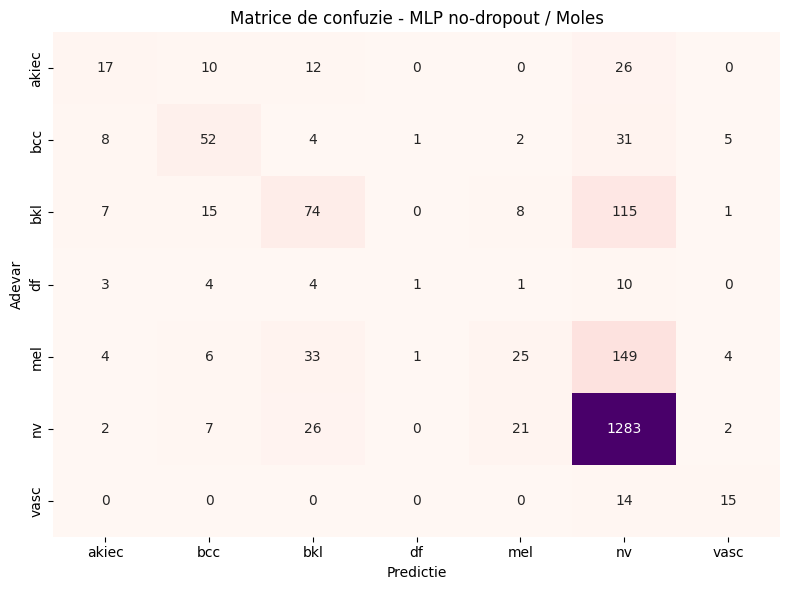


 Rezultate pentru MLP no-dropout / Emotions 
Accuracy : 0.6081
F1-macro : 0.4980
F1-micro : 0.6081

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.5769    0.5440    0.5600       193
        Fear     0.5833    0.1667    0.2593        42
     Disgust     0.4444    0.2991    0.3575       107
   Happiness     0.8495    0.7343    0.7877       715
     Sadness     0.4467    0.4512    0.4489       297
       Anger     0.4646    0.5619    0.5086       105
     Neutral     0.4848    0.6746    0.5642       378

    accuracy                         0.6081      1837
   macro avg     0.5500    0.4902    0.4980      1837
weighted avg     0.6290    0.6081    0.6099      1837



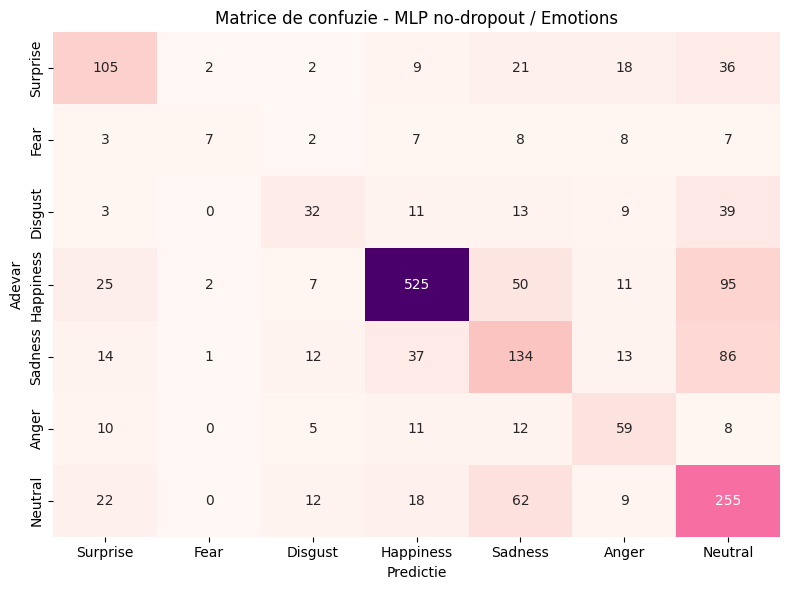

ABLATIA 3.5.1: MLP cu/fara Dropout
Varianta                                        Acc   F1-macro   F1-micro
MLP CU dropout - Moles                       0.7229     0.3500     0.7229
MLP FARA dropout - Moles                     0.7324     0.4145     0.7324
MLP CU dropout - Emotions                    0.6119     0.4803     0.6119
MLP FARA dropout - Emotions                  0.6081     0.4980     0.6081


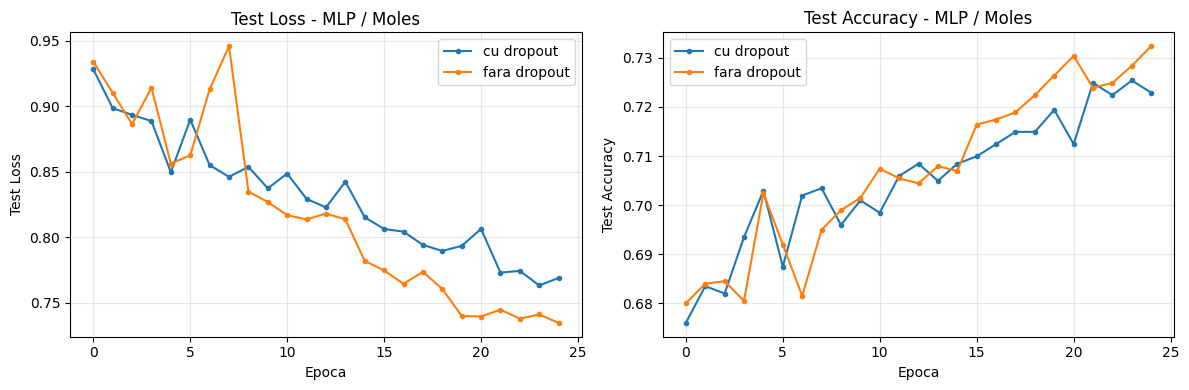

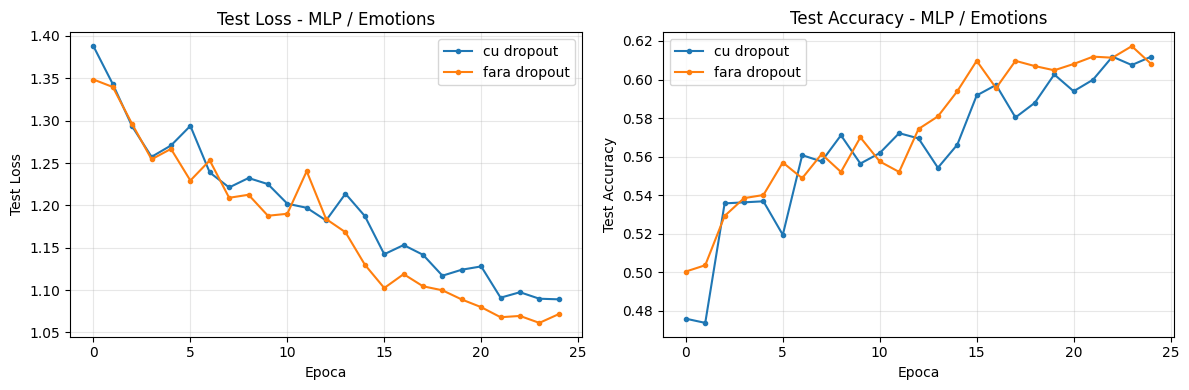

In [44]:
# Evaluare + compararea ablatiei 3.5.1
moles_mlp_nodrop_results = evaluate_full(moles_mlp_nodrop, moles_test_loader,
                                         class_names=MOLES_CLASS_NAMES,
                                         title="MLP no-dropout / Moles")
emo_mlp_nodrop_results = evaluate_full(emo_mlp_nodrop, emo_test_loader,
                                       class_names=emo_class_list,
                                       title="MLP no-dropout / Emotions")

# Tabel comparativ
print_ablation_table({
    "MLP CU dropout - Moles":    moles_results,
    "MLP FARA dropout - Moles":  moles_mlp_nodrop_results,
    "MLP CU dropout - Emotions": emo_results,
    "MLP FARA dropout - Emotions": emo_mlp_nodrop_results,
}, title="ABLATIA 3.5.1: MLP cu/fara Dropout")

# Plot curbele suprapuse
plot_ablation_curves_grid({
    "cu dropout":    moles_history,
    "fara dropout":  moles_mlp_nodrop_history,
}, title="MLP / Moles")

plot_ablation_curves_grid({
    "cu dropout":    emo_history,
    "fara dropout":  emo_mlp_nodrop_history,
}, title="MLP / Emotions")


## 3.5.2 Ablatie: CNN cu / fara BatchNorm

In [45]:
# CNN FARA BatchNorm pe Moles
moles_cnn_nobn = SimpleCNN(num_classes=len(MOLES_CLASS_NAMES),
                           first_kernel=5,  # acelasi ca baseline
                           use_batchnorm=False,
                           dropout=0.3).to(device)
print(f"Parametri CNN no-BN (Moles): {sum(p.numel() for p in moles_cnn_nobn.parameters()):,}")
moles_cnn_nobn_history = fit(moles_cnn_nobn, moles_train_loader, moles_test_loader,
                             num_epochs=NUM_EPOCHS, lr=1e-3, weight_decay=1e-4)


Parametri CNN no-BN (Moles): 423,751
Epoca 01/25 | train loss=1.1006 acc=0.663 | test loss=0.9971 acc=0.669 | 13.3s
Epoca 02/25 | train loss=0.9928 acc=0.669 | test loss=0.9635 acc=0.669 | 11.3s
Epoca 03/25 | train loss=0.9546 acc=0.666 | test loss=0.9575 acc=0.669 | 11.4s
Epoca 04/25 | train loss=0.9472 acc=0.668 | test loss=0.9555 acc=0.669 | 11.4s
Epoca 05/25 | train loss=0.9098 acc=0.670 | test loss=0.8938 acc=0.669 | 11.6s
Epoca 06/25 | train loss=0.8970 acc=0.668 | test loss=0.8817 acc=0.668 | 11.3s
Epoca 07/25 | train loss=0.8846 acc=0.672 | test loss=0.8599 acc=0.678 | 11.6s
Epoca 08/25 | train loss=0.8638 acc=0.677 | test loss=0.8455 acc=0.670 | 11.7s
Epoca 09/25 | train loss=0.8418 acc=0.680 | test loss=0.8600 acc=0.685 | 11.4s
Epoca 10/25 | train loss=0.8319 acc=0.690 | test loss=0.8138 acc=0.691 | 11.7s
Epoca 11/25 | train loss=0.8076 acc=0.699 | test loss=0.8014 acc=0.707 | 11.5s
Epoca 12/25 | train loss=0.8123 acc=0.698 | test loss=0.8357 acc=0.693 | 11.3s
Epoca 13/25 | t

In [46]:
# CNN FARA BatchNorm pe Emotions
emo_cnn_nobn = SimpleCNN(num_classes=len(EMOTIONS_CLASS_NAMES),
                         first_kernel=3,
                         use_batchnorm=False,
                         dropout=0.3).to(device)
emo_cnn_nobn_history = fit(emo_cnn_nobn, emo_train_loader, emo_test_loader,
                           num_epochs=NUM_EPOCHS, lr=1e-3, weight_decay=1e-4)


Epoca 01/25 | train loss=1.6570 acc=0.383 | test loss=1.6211 acc=0.389 | 24.9s
Epoca 02/25 | train loss=1.6108 acc=0.394 | test loss=1.5980 acc=0.403 | 19.6s
Epoca 03/25 | train loss=1.5889 acc=0.399 | test loss=1.5832 acc=0.404 | 19.3s
Epoca 04/25 | train loss=1.5706 acc=0.405 | test loss=1.5732 acc=0.405 | 19.9s
Epoca 05/25 | train loss=1.5571 acc=0.413 | test loss=1.5648 acc=0.404 | 19.3s
Epoca 06/25 | train loss=1.5429 acc=0.423 | test loss=1.5527 acc=0.415 | 18.6s
Epoca 07/25 | train loss=1.5371 acc=0.432 | test loss=1.5475 acc=0.419 | 18.5s
Epoca 08/25 | train loss=1.5140 acc=0.442 | test loss=1.5303 acc=0.421 | 18.4s
Epoca 09/25 | train loss=1.4896 acc=0.450 | test loss=1.5235 acc=0.425 | 18.7s
Epoca 10/25 | train loss=1.4638 acc=0.466 | test loss=1.5173 acc=0.440 | 18.7s
Epoca 11/25 | train loss=1.4489 acc=0.471 | test loss=1.4761 acc=0.437 | 18.7s
Epoca 12/25 | train loss=1.4310 acc=0.475 | test loss=1.4623 acc=0.454 | 19.0s
Epoca 13/25 | train loss=1.4046 acc=0.487 | test los


 Rezultate pentru CNN no-BN / Moles 
Accuracy : 0.7194
F1-macro : 0.2947
F1-micro : 0.7194

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.2000    0.0615    0.0941        65
         bcc     0.4086    0.3689    0.3878       103
         bkl     0.4463    0.3591    0.3980       220
          df     0.0000    0.0000    0.0000        23
         mel     0.5000    0.2387    0.3232       222
          nv     0.7884    0.9448    0.8596      1341
        vasc     0.0000    0.0000    0.0000        29

    accuracy                         0.7194      2003
   macro avg     0.3348    0.2819    0.2947      2003
weighted avg     0.6598    0.7194    0.6780      2003



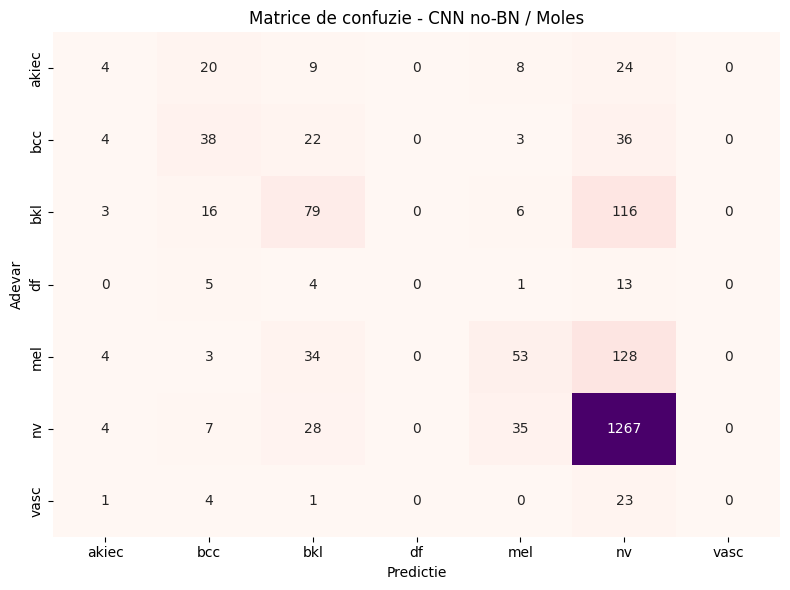


 Rezultate pentru CNN no-BN / Emotions 
Accuracy : 0.5041
F1-macro : 0.2577
F1-micro : 0.5041

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.3846    0.1554    0.2214       193
        Fear     0.0000    0.0000    0.0000        42
     Disgust     0.0000    0.0000    0.0000       107
   Happiness     0.7158    0.7678    0.7409       715
     Sadness     0.2774    0.1279    0.1751       297
       Anger     0.3333    0.1143    0.1702       105
     Neutral     0.3626    0.7857    0.4962       378

    accuracy                         0.5041      1837
   macro avg     0.2962    0.2787    0.2577      1837
weighted avg     0.4575    0.5041    0.4518      1837



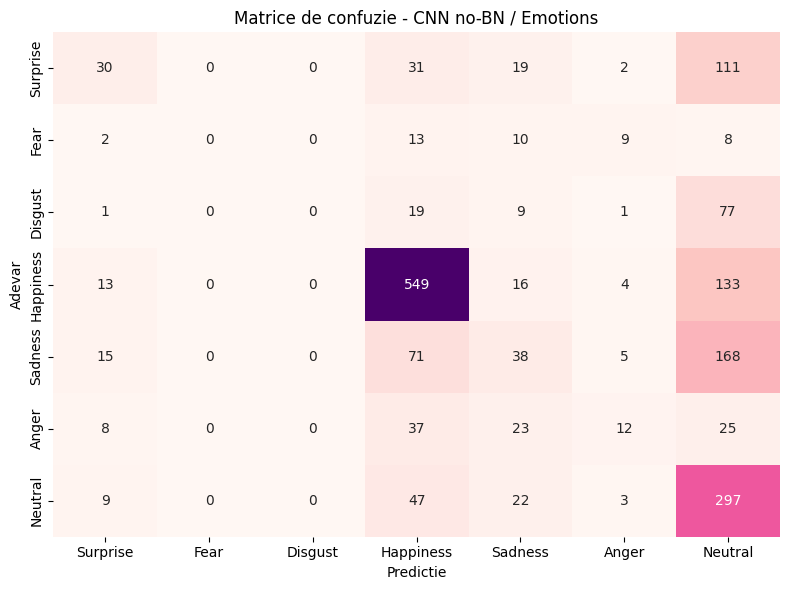

ABLATIA 3.5.2: CNN cu/fara BatchNorm
Varianta                                        Acc   F1-macro   F1-micro
CNN CU BN - Moles                            0.7544     0.4505     0.7544
CNN FARA BN - Moles                          0.7194     0.2947     0.7194
CNN CU BN - Emotions                         0.6995     0.5793     0.6995
CNN FARA BN - Emotions                       0.5041     0.2577     0.5041


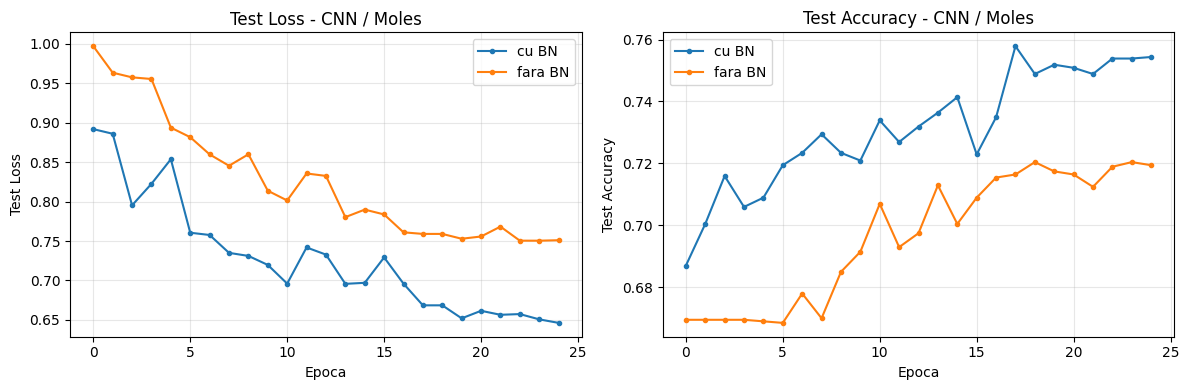

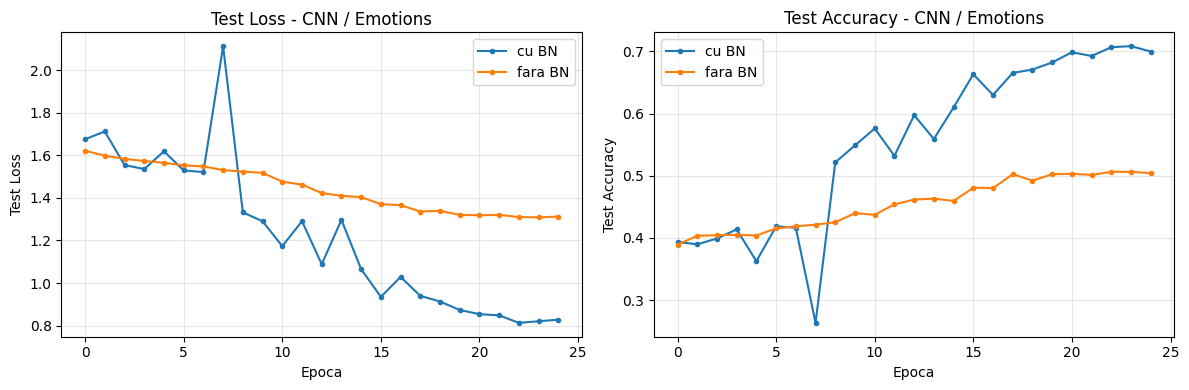

In [205]:
# Evaluare + compararea ablatiei 3.5.2
moles_cnn_nobn_results = evaluate_full(moles_cnn_nobn, moles_test_loader,
                                       class_names=MOLES_CLASS_NAMES,
                                       title="CNN no-BN / Moles")
emo_cnn_nobn_results = evaluate_full(emo_cnn_nobn, emo_test_loader,
                                     class_names=emo_class_list,
                                     title="CNN no-BN / Emotions")

print_ablation_table({
    "CNN CU BN - Moles":      moles_cnn_results,
    "CNN FARA BN - Moles":    moles_cnn_nobn_results,
    "CNN CU BN - Emotions":   emo_cnn_results,
    "CNN FARA BN - Emotions": emo_cnn_nobn_results,
}, title="ABLATIA 3.5.2: CNN cu/fara BatchNorm")

plot_ablation_curves_grid({
    "cu BN":   moles_cnn_history,
    "fara BN": moles_cnn_nobn_history,
}, title="CNN / Moles")

plot_ablation_curves_grid({
    "cu BN":   emo_cnn_history,
    "fara BN": emo_cnn_nobn_history,
}, title="CNN / Emotions")


## 3.5.3 Ablatie: CNN cu diferite configuratii de augmentare

In [48]:
# === MOLES — variantele de augmentare ===
moles_noaug_t = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MOLES_MEAN, MOLES_STD),
])
moles_geom_t = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomVerticalFlip(0.5),
    transforms.RandomRotation(180),
    # FARA ColorJitter
    transforms.ToTensor(),
    transforms.Normalize(MOLES_MEAN, MOLES_STD),
])
moles_color_t = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    # FARA transformari geometrice aleatoare
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MOLES_MEAN, MOLES_STD),
])

# === EMOTIONS — variantele de augmentare ===
emo_noaug_t = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(EMOTIONS_MEAN, EMOTIONS_STD),
])
emo_geom_t = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(EMOTIONS_MEAN, EMOTIONS_STD),
])
emo_color_t = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(EMOTIONS_MEAN, EMOTIONS_STD),
])

# Helper care creeaza un DataLoader cu un transform dat
def make_train_loader(dataset_cls, csv_path, img_dir_or_root, transform, **kwargs):
    """Construieste un train_loader cu transform-ul specificat."""
    if dataset_cls == MolesDataset:
        ds = MolesDataset(csv_path, img_dir_or_root, transform=transform)
    else:
        ds = EmotionsDataset(csv_path, img_dir_or_root, transform=transform)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True,
                      num_workers=2, drop_last=True)
moles_noaug_loader = make_train_loader(MolesDataset, MOLES_TRAIN_CSV, MOLES_TRAIN_IMG_DIR, moles_noaug_t)
moles_geom_loader  = make_train_loader(MolesDataset, MOLES_TRAIN_CSV, MOLES_TRAIN_IMG_DIR, moles_geom_t)
moles_color_loader = make_train_loader(MolesDataset, MOLES_TRAIN_CSV, MOLES_TRAIN_IMG_DIR, moles_color_t)

emo_noaug_loader = make_train_loader(EmotionsDataset, EMOTIONS_TRAIN_CSV, EMOTIONS_IMG_ROOT, emo_noaug_t)
emo_geom_loader  = make_train_loader(EmotionsDataset, EMOTIONS_TRAIN_CSV, EMOTIONS_IMG_ROOT, emo_geom_t)
emo_color_loader = make_train_loader(EmotionsDataset, EMOTIONS_TRAIN_CSV, EMOTIONS_IMG_ROOT, emo_color_t)


Dataset inițializat. S-au găsit 10434 poze valide!
Dataset inițializat. S-au găsit 10434 poze valide!
Dataset inițializat. S-au găsit 10434 poze valide!


In [49]:
# === CNN cu NO_AUG pe Moles + Emotions ===
moles_cnn_noaug = SimpleCNN(num_classes=7, first_kernel=5).to(device)
moles_cnn_noaug_history = fit(moles_cnn_noaug, moles_noaug_loader, moles_test_loader,
                              num_epochs=NUM_EPOCHS)

emo_cnn_noaug = SimpleCNN(num_classes=7, first_kernel=3).to(device)
emo_cnn_noaug_history = fit(emo_cnn_noaug, emo_noaug_loader, emo_test_loader,
                            num_epochs=NUM_EPOCHS)


Epoca 01/25 | train loss=0.9615 acc=0.669 | test loss=0.8688 acc=0.691 | 11.0s
Epoca 02/25 | train loss=0.8165 acc=0.702 | test loss=0.8046 acc=0.715 | 8.8s
Epoca 03/25 | train loss=0.7867 acc=0.711 | test loss=0.7942 acc=0.700 | 8.9s
Epoca 04/25 | train loss=0.7465 acc=0.718 | test loss=0.7354 acc=0.721 | 8.8s
Epoca 05/25 | train loss=0.7420 acc=0.723 | test loss=0.7270 acc=0.722 | 8.8s
Epoca 06/25 | train loss=0.7311 acc=0.725 | test loss=0.7489 acc=0.719 | 8.7s
Epoca 07/25 | train loss=0.7117 acc=0.734 | test loss=0.7334 acc=0.729 | 8.8s
Epoca 08/25 | train loss=0.6915 acc=0.745 | test loss=0.6915 acc=0.739 | 8.9s
Epoca 09/25 | train loss=0.6837 acc=0.740 | test loss=0.7089 acc=0.739 | 9.2s
Epoca 10/25 | train loss=0.6833 acc=0.743 | test loss=0.7171 acc=0.728 | 9.2s
Epoca 11/25 | train loss=0.6602 acc=0.751 | test loss=0.6608 acc=0.757 | 9.0s
Epoca 12/25 | train loss=0.6576 acc=0.753 | test loss=0.7431 acc=0.722 | 8.9s
Epoca 13/25 | train loss=0.6444 acc=0.757 | test loss=0.6850 ac

In [50]:
# === CNN cu GEOM_ONLY pe Moles + Emotions ===
moles_cnn_geom = SimpleCNN(num_classes=7, first_kernel=5).to(device)
moles_cnn_geom_history = fit(moles_cnn_geom, moles_geom_loader, moles_test_loader,
                             num_epochs=NUM_EPOCHS)

emo_cnn_geom = SimpleCNN(num_classes=7, first_kernel=3).to(device)
emo_cnn_geom_history = fit(emo_cnn_geom, emo_geom_loader, emo_test_loader,
                           num_epochs=NUM_EPOCHS)


Epoca 01/25 | train loss=1.0244 acc=0.649 | test loss=0.9400 acc=0.687 | 12.6s
Epoca 02/25 | train loss=0.8411 acc=0.690 | test loss=0.8282 acc=0.703 | 9.6s
Epoca 03/25 | train loss=0.8169 acc=0.697 | test loss=0.8160 acc=0.713 | 10.1s
Epoca 04/25 | train loss=0.7933 acc=0.705 | test loss=0.8497 acc=0.687 | 10.0s
Epoca 05/25 | train loss=0.7726 acc=0.715 | test loss=0.8325 acc=0.702 | 9.7s
Epoca 06/25 | train loss=0.7489 acc=0.717 | test loss=0.7561 acc=0.718 | 9.9s
Epoca 07/25 | train loss=0.7291 acc=0.725 | test loss=0.7401 acc=0.727 | 9.9s
Epoca 08/25 | train loss=0.7282 acc=0.727 | test loss=0.7434 acc=0.726 | 9.8s
Epoca 09/25 | train loss=0.7143 acc=0.731 | test loss=0.7494 acc=0.726 | 9.8s
Epoca 10/25 | train loss=0.6969 acc=0.738 | test loss=0.7315 acc=0.727 | 9.9s
Epoca 11/25 | train loss=0.6786 acc=0.744 | test loss=0.7281 acc=0.729 | 9.8s
Epoca 12/25 | train loss=0.6659 acc=0.751 | test loss=0.7356 acc=0.732 | 10.7s
Epoca 13/25 | train loss=0.6598 acc=0.751 | test loss=0.7017

In [51]:
# === CNN cu COLOR_ONLY pe Moles + Emotions ===
moles_cnn_color = SimpleCNN(num_classes=7, first_kernel=5).to(device)
moles_cnn_color_history = fit(moles_cnn_color, moles_color_loader, moles_test_loader,
                              num_epochs=NUM_EPOCHS)

emo_cnn_color = SimpleCNN(num_classes=7, first_kernel=3).to(device)
emo_cnn_color_history = fit(emo_cnn_color, emo_color_loader, emo_test_loader,
                            num_epochs=NUM_EPOCHS)


Epoca 01/25 | train loss=1.0735 acc=0.638 | test loss=0.8512 acc=0.701 | 13.8s
Epoca 02/25 | train loss=0.8399 acc=0.702 | test loss=0.8664 acc=0.693 | 10.9s
Epoca 03/25 | train loss=0.8113 acc=0.705 | test loss=0.7869 acc=0.705 | 11.0s
Epoca 04/25 | train loss=0.7856 acc=0.707 | test loss=0.8380 acc=0.713 | 11.0s
Epoca 05/25 | train loss=0.7603 acc=0.718 | test loss=0.7667 acc=0.718 | 10.8s
Epoca 06/25 | train loss=0.7450 acc=0.721 | test loss=0.7448 acc=0.731 | 10.8s
Epoca 07/25 | train loss=0.7290 acc=0.733 | test loss=0.7294 acc=0.723 | 10.8s
Epoca 08/25 | train loss=0.7234 acc=0.732 | test loss=0.7617 acc=0.732 | 10.8s
Epoca 09/25 | train loss=0.7059 acc=0.735 | test loss=0.6939 acc=0.753 | 10.7s
Epoca 10/25 | train loss=0.6955 acc=0.740 | test loss=0.7187 acc=0.743 | 11.3s
Epoca 11/25 | train loss=0.6780 acc=0.747 | test loss=0.7419 acc=0.724 | 10.6s
Epoca 12/25 | train loss=0.6752 acc=0.744 | test loss=0.6703 acc=0.744 | 10.7s
Epoca 13/25 | train loss=0.6723 acc=0.744 | test los


 Rezultate pentru CNN no-aug / Moles 
Accuracy : 0.7813
F1-macro : 0.5340
F1-micro : 0.7813

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.5800    0.4462    0.5043        65
         bcc     0.6036    0.6505    0.6262       103
         bkl     0.5512    0.5136    0.5318       220
          df     0.0000    0.0000    0.0000        23
         mel     0.5478    0.3874    0.4538       222
          nv     0.8603    0.9321    0.8948      1341
        vasc     0.7692    0.6897    0.7273        29

    accuracy                         0.7813      2003
   macro avg     0.5589    0.5171    0.5340      2003
weighted avg     0.7582    0.7813    0.7668      2003



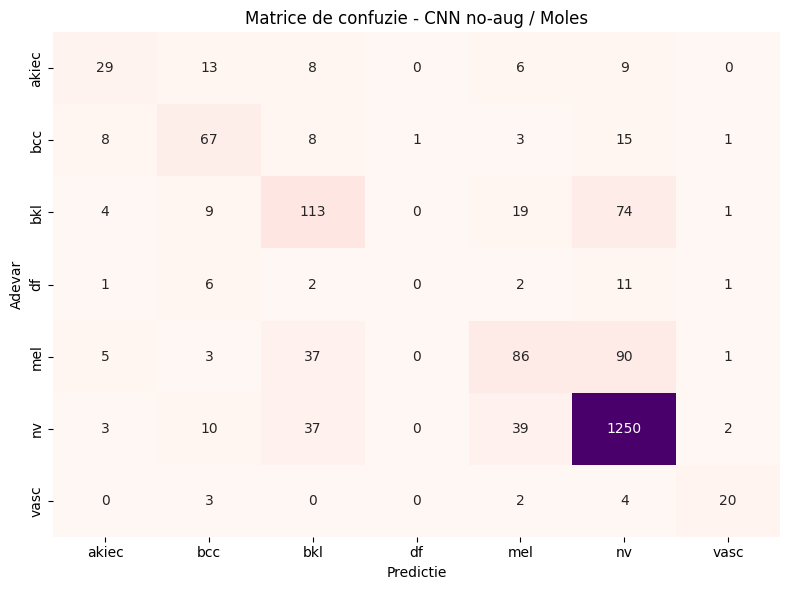


 Rezultate pentru CNN geom-only / Moles 
Accuracy : 0.7634
F1-macro : 0.4850
F1-micro : 0.7634

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.4286    0.3231    0.3684        65
         bcc     0.7049    0.4175    0.5244       103
         bkl     0.4684    0.5045    0.4858       220
          df     0.3333    0.0435    0.0769        23
         mel     0.5404    0.3919    0.4543       222
          nv     0.8494    0.9336    0.8895      1341
        vasc     0.7778    0.4828    0.5957        29

    accuracy                         0.7634      2003
   macro avg     0.5861    0.4424    0.4850      2003
weighted avg     0.7452    0.7634    0.7477      2003



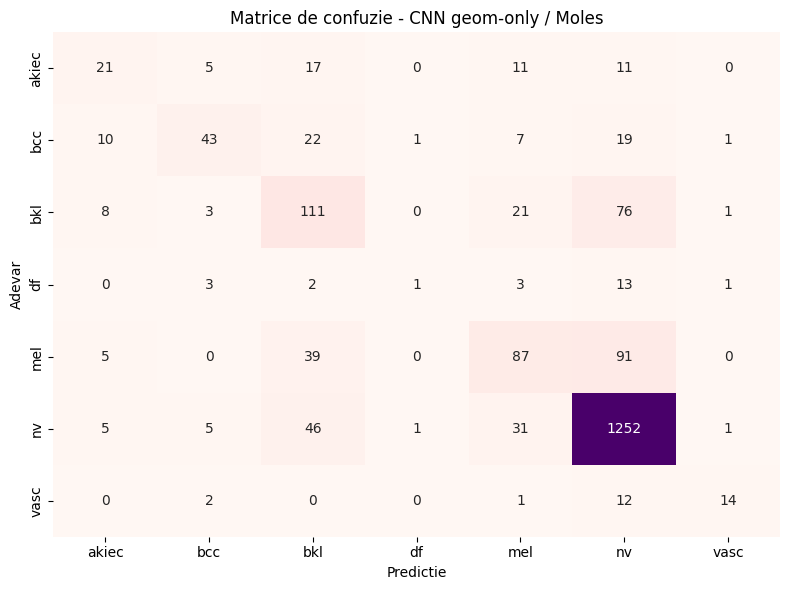


 Rezultate pentru CNN color-only / Moles 
Accuracy : 0.7778
F1-macro : 0.5254
F1-micro : 0.7778

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.5000    0.3538    0.4144        65
         bcc     0.5789    0.6408    0.6083       103
         bkl     0.5556    0.4773    0.5134       220
          df     0.5000    0.0435    0.0800        23
         mel     0.5694    0.3694    0.4481       222
          nv     0.8494    0.9418    0.8932      1341
        vasc     0.8571    0.6207    0.7200        29

    accuracy                         0.7778      2003
   macro avg     0.6301    0.4925    0.5254      2003
weighted avg     0.7569    0.7778    0.7601      2003



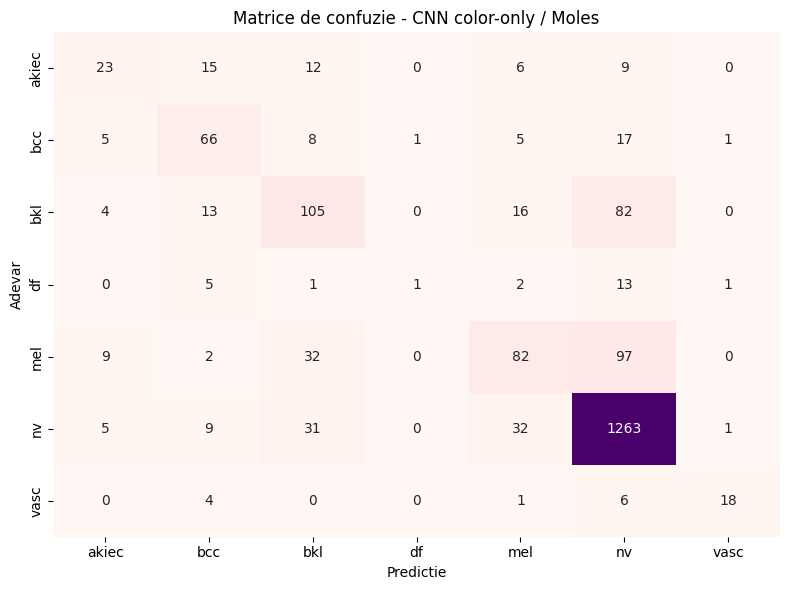


 Rezultate pentru CNN no-aug / Emotions 
Accuracy : 0.7300
F1-macro : 0.6314
F1-micro : 0.7300

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.7637    0.7202    0.7413       193
        Fear     0.6552    0.4524    0.5352        42
     Disgust     0.4000    0.3551    0.3762       107
   Happiness     0.8533    0.8783    0.8656       715
     Sadness     0.6154    0.6195    0.6174       297
       Anger     0.6042    0.5524    0.5771       105
     Neutral     0.6875    0.7275    0.7069       378

    accuracy                         0.7300      1837
   macro avg     0.6542    0.6151    0.6314      1837
weighted avg     0.7261    0.7300    0.7272      1837



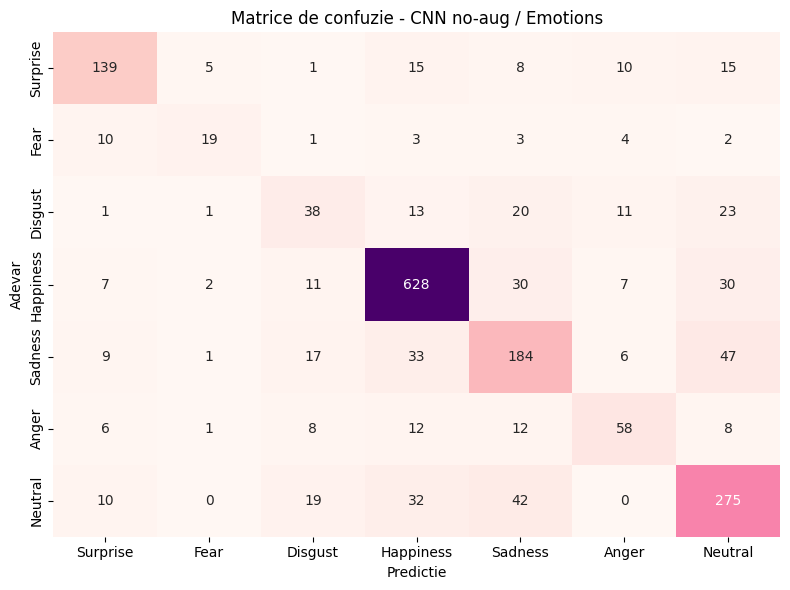


 Rezultate pentru CNN geom-only / Emotions 
Accuracy : 0.7011
F1-macro : 0.5840
F1-micro : 0.7011

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.7500    0.7306    0.7402       193
        Fear     0.4783    0.2619    0.3385        42
     Disgust     0.3267    0.3084    0.3173       107
   Happiness     0.9078    0.8126    0.8576       715
     Sadness     0.5643    0.6061    0.5844       297
       Anger     0.5191    0.6476    0.5763       105
     Neutral     0.6299    0.7249    0.6740       378

    accuracy                         0.7011      1837
   macro avg     0.5966    0.5846    0.5840      1837
weighted avg     0.7126    0.7011    0.7039      1837



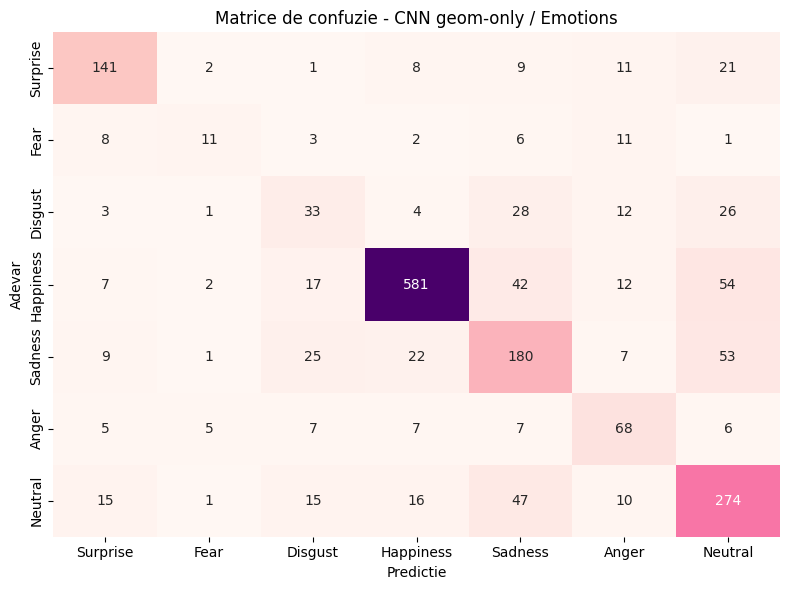


 Rezultate pentru CNN color-only / Emotions 
Accuracy : 0.7305
F1-macro : 0.6258
F1-micro : 0.7305

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.7286    0.7513    0.7398       193
        Fear     0.6800    0.4048    0.5075        42
     Disgust     0.4691    0.3551    0.4043       107
   Happiness     0.8687    0.8699    0.8693       715
     Sadness     0.6019    0.6566    0.6280       297
       Anger     0.5714    0.4952    0.5306       105
     Neutral     0.6808    0.7222    0.7009       378

    accuracy                         0.7305      1837
   macro avg     0.6572    0.6079    0.6258      1837
weighted avg     0.7276    0.7305    0.7273      1837



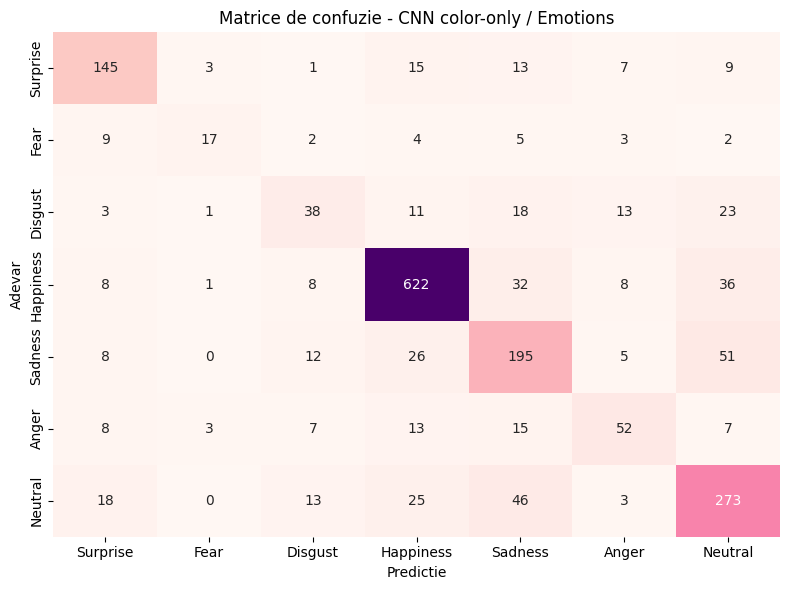

In [52]:
# Evaluare + comparare ablatia 3.5.3 (4 variante per dataset)
moles_cnn_noaug_results = evaluate_full(moles_cnn_noaug, moles_test_loader,
                                        class_names=MOLES_CLASS_NAMES,
                                        title="CNN no-aug / Moles")
moles_cnn_geom_results  = evaluate_full(moles_cnn_geom,  moles_test_loader,
                                        class_names=MOLES_CLASS_NAMES,
                                        title="CNN geom-only / Moles")
moles_cnn_color_results = evaluate_full(moles_cnn_color, moles_test_loader,
                                        class_names=MOLES_CLASS_NAMES,
                                        title="CNN color-only / Moles")

emo_cnn_noaug_results = evaluate_full(emo_cnn_noaug, emo_test_loader,
                                      class_names=emo_class_list,
                                      title="CNN no-aug / Emotions")
emo_cnn_geom_results  = evaluate_full(emo_cnn_geom, emo_test_loader,
                                      class_names=emo_class_list,
                                      title="CNN geom-only / Emotions")
emo_cnn_color_results = evaluate_full(emo_cnn_color, emo_test_loader,
                                      class_names=emo_class_list,
                                      title="CNN color-only / Emotions")


ABLATIA 3.5.3: CNN cu diferite augmentari / Moles
Varianta                                        Acc   F1-macro   F1-micro
CNN fara aug - Moles                         0.7813     0.5340     0.7813
CNN geom-only - Moles                        0.7634     0.4850     0.7634
CNN color-only - Moles                       0.7778     0.5254     0.7778
CNN toate aug (baseline) - Moles             0.7544     0.4505     0.7544
ABLATIA 3.5.3: CNN cu diferite augmentari / Emotions
Varianta                                        Acc   F1-macro   F1-micro
CNN fara aug - Emotions                      0.7300     0.6314     0.7300
CNN geom-only - Emotions                     0.7011     0.5840     0.7011
CNN color-only - Emotions                    0.7305     0.6258     0.7305
CNN toate aug (baseline) - Emotions          0.6995     0.5793     0.6995


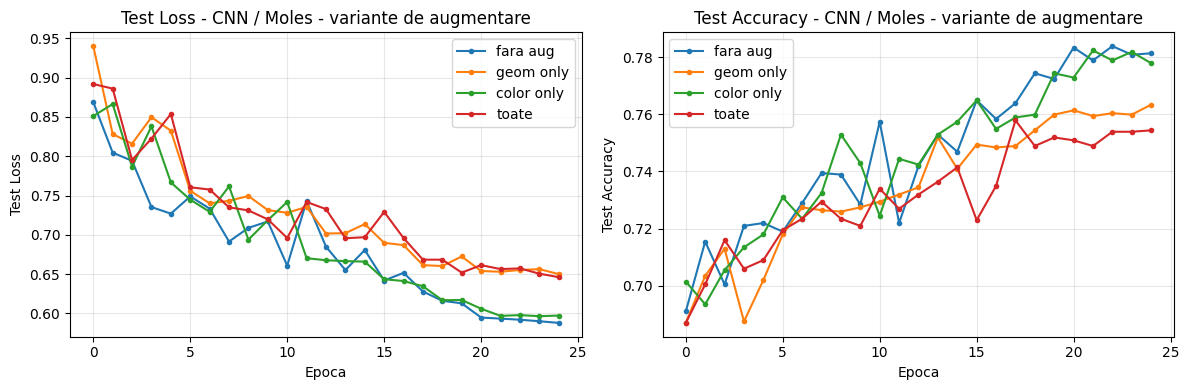

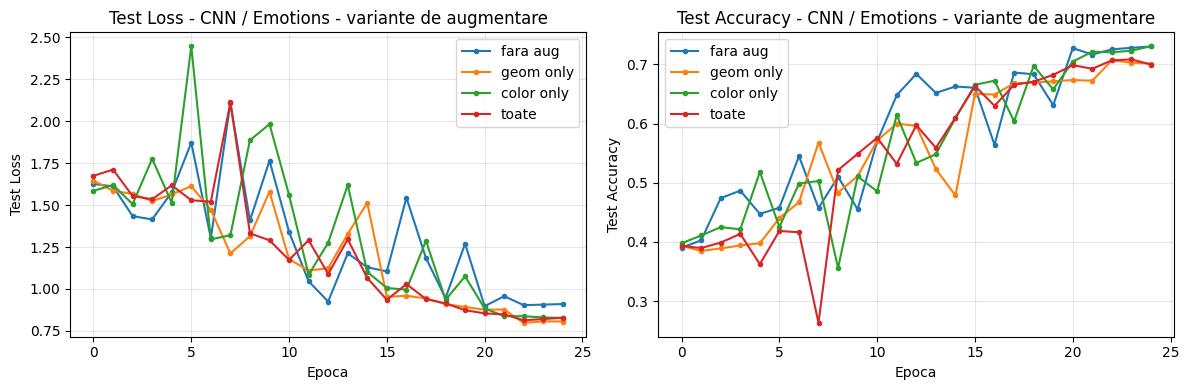

In [206]:
# Tabel + curbe comparative pentru ablatia 3.5.3
print_ablation_table({
    "CNN fara aug - Moles":           moles_cnn_noaug_results,
    "CNN geom-only - Moles":          moles_cnn_geom_results,
    "CNN color-only - Moles":         moles_cnn_color_results,
    "CNN toate aug (baseline) - Moles": moles_cnn_results,
}, title="ABLATIA 3.5.3: CNN cu diferite augmentari / Moles")

print_ablation_table({
    "CNN fara aug - Emotions":           emo_cnn_noaug_results,
    "CNN geom-only - Emotions":          emo_cnn_geom_results,
    "CNN color-only - Emotions":         emo_cnn_color_results,
    "CNN toate aug (baseline) - Emotions": emo_cnn_results,
}, title="ABLATIA 3.5.3: CNN cu diferite augmentari / Emotions")

plot_ablation_curves_grid({
    "fara aug":   moles_cnn_noaug_history,
    "geom only":  moles_cnn_geom_history,
    "color only": moles_cnn_color_history,
    "toate":      moles_cnn_history,
}, title="CNN / Moles - variante de augmentare")

plot_ablation_curves_grid({
    "fara aug":   emo_cnn_noaug_history,
    "geom only":  emo_cnn_geom_history,
    "color only": emo_cnn_color_history,
    "toate":      emo_cnn_history,
}, title="CNN / Emotions - variante de augmentare")


## 3.5.4 Ablatie: CNN cu / fara tehnici pentru dezechilibrul claselor

In [54]:
# Construim WeightedRandomSampler pentru ambele seturi
from torch.utils.data import WeightedRandomSampler

def build_balanced_loader(dataset, batch_size=BATCH_SIZE):
    """Construieste un loader cu sampling invers proportional cu frecventa clasei."""
    labels = dataset.get_labels()
    class_counts = np.bincount(labels)
    print(f"Distributia claselor: {dict(enumerate(class_counts))}")
    # Pondere invers proportionala -> clasa rara va fi extrasa mai des
    class_weights = 1.0 / class_counts
    sample_weights = class_weights[labels]
    sampler = WeightedRandomSampler(
        weights=torch.from_numpy(sample_weights).double(),
        num_samples=len(sample_weights),
        replacement=True,
    )
    # IMPORTANT: NU folosim shuffle=True cand avem sampler
    return DataLoader(dataset, batch_size=batch_size, sampler=sampler,
                      num_workers=2, drop_last=True)

print("--- Moles ---")
moles_balanced_loader = build_balanced_loader(moles_train_ds)
print("\n--- Emotions ---")
emo_balanced_loader = build_balanced_loader(emotions_train_ds)


--- Moles ---
Distributia claselor: {0: np.int64(196), 1: np.int64(308), 2: np.int64(660), 3: np.int64(69), 4: np.int64(668), 5: np.int64(4023), 6: np.int64(85)}

--- Emotions ---
Distributia claselor: {0: np.int64(1097), 1: np.int64(239), 2: np.int64(610), 3: np.int64(4057), 4: np.int64(1685), 5: np.int64(600), 6: np.int64(2146)}


In [55]:
# CNN cu BALANCED sampler pe Moles
moles_cnn_balanced = SimpleCNN(num_classes=7, first_kernel=5).to(device)
moles_cnn_balanced_history = fit(moles_cnn_balanced, moles_balanced_loader,
                                 moles_test_loader, num_epochs=NUM_EPOCHS,
                                 lr=1e-3, weight_decay=1e-4)


Epoca 01/25 | train loss=1.5189 acc=0.424 | test loss=1.3317 acc=0.527 | 12.1s
Epoca 02/25 | train loss=1.2958 acc=0.505 | test loss=1.3109 acc=0.517 | 11.7s
Epoca 03/25 | train loss=1.2182 acc=0.531 | test loss=1.0999 acc=0.568 | 11.5s
Epoca 04/25 | train loss=1.1390 acc=0.566 | test loss=1.0155 acc=0.625 | 11.6s
Epoca 05/25 | train loss=1.1090 acc=0.574 | test loss=1.3337 acc=0.498 | 11.5s
Epoca 06/25 | train loss=1.0614 acc=0.600 | test loss=1.2394 acc=0.566 | 11.6s
Epoca 07/25 | train loss=1.0214 acc=0.615 | test loss=1.3019 acc=0.507 | 11.6s
Epoca 08/25 | train loss=1.0241 acc=0.612 | test loss=0.9742 acc=0.613 | 11.5s
Epoca 09/25 | train loss=0.9750 acc=0.623 | test loss=1.5978 acc=0.422 | 11.8s
Epoca 10/25 | train loss=0.9556 acc=0.633 | test loss=1.1069 acc=0.593 | 11.6s
Epoca 11/25 | train loss=0.9261 acc=0.644 | test loss=1.0067 acc=0.603 | 11.4s
Epoca 12/25 | train loss=0.9134 acc=0.661 | test loss=1.0495 acc=0.592 | 11.3s
Epoca 13/25 | train loss=0.8956 acc=0.656 | test los

In [56]:
# CNN cu BALANCED sampler pe Emotions
emo_cnn_balanced = SimpleCNN(num_classes=7, first_kernel=3).to(device)
emo_cnn_balanced_history = fit(emo_cnn_balanced, emo_balanced_loader,
                               emo_test_loader, num_epochs=NUM_EPOCHS,
                               lr=1e-3, weight_decay=1e-4)


Epoca 01/25 | train loss=1.8853 acc=0.226 | test loss=1.8166 acc=0.289 | 21.4s
Epoca 02/25 | train loss=1.8343 acc=0.265 | test loss=1.7726 acc=0.342 | 18.9s
Epoca 03/25 | train loss=1.7980 acc=0.285 | test loss=1.8412 acc=0.237 | 18.6s
Epoca 04/25 | train loss=1.7564 acc=0.310 | test loss=1.8175 acc=0.213 | 18.3s
Epoca 05/25 | train loss=1.6496 acc=0.364 | test loss=1.7349 acc=0.335 | 18.6s
Epoca 06/25 | train loss=1.5437 acc=0.421 | test loss=1.7642 acc=0.319 | 18.4s
Epoca 07/25 | train loss=1.4503 acc=0.459 | test loss=1.6785 acc=0.388 | 18.5s
Epoca 08/25 | train loss=1.3431 acc=0.497 | test loss=1.8958 acc=0.302 | 18.5s
Epoca 09/25 | train loss=1.2566 acc=0.533 | test loss=1.6452 acc=0.421 | 18.1s
Epoca 10/25 | train loss=1.1926 acc=0.560 | test loss=2.2845 acc=0.315 | 18.4s
Epoca 11/25 | train loss=1.1398 acc=0.582 | test loss=1.8680 acc=0.389 | 18.2s
Epoca 12/25 | train loss=1.0712 acc=0.606 | test loss=1.4272 acc=0.487 | 18.6s
Epoca 13/25 | train loss=1.0430 acc=0.615 | test los


 Rezultate pentru CNN balanced sampler / Moles 
Accuracy : 0.6665
F1-macro : 0.5429
F1-micro : 0.6665

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.3529    0.7385    0.4776        65
         bcc     0.4581    0.6893    0.5504       103
         bkl     0.4563    0.5455    0.4969       220
          df     0.1970    0.5652    0.2921        23
         mel     0.3612    0.6036    0.4519       222
          nv     0.9515    0.6883    0.7988      1341
        vasc     0.6190    0.8966    0.7324        29

    accuracy                         0.6665      2003
   macro avg     0.4851    0.6753    0.5429      2003
weighted avg     0.7734    0.6665    0.6972      2003



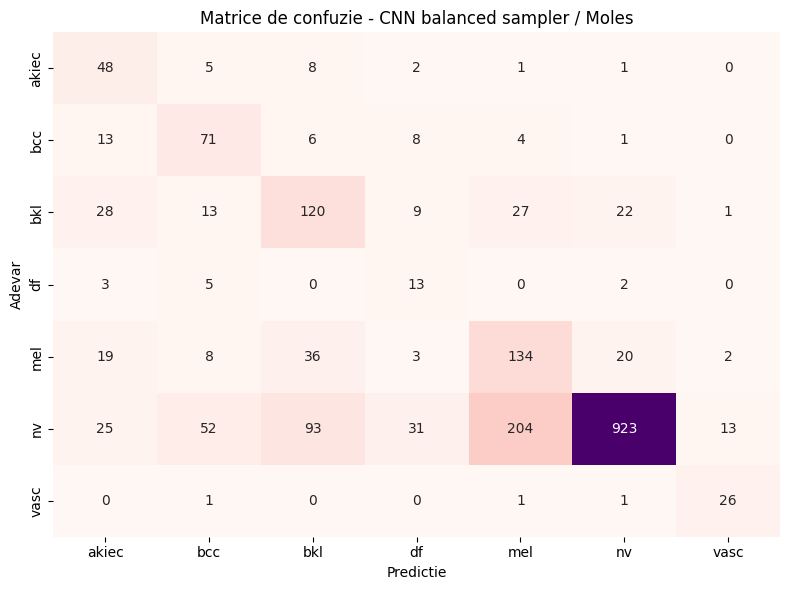


 Rezultate pentru CNN balanced sampler / Emotions 
Accuracy : 0.6418
F1-macro : 0.5627
F1-micro : 0.6418

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.7020    0.7202    0.7110       193
        Fear     0.2212    0.5476    0.3151        42
     Disgust     0.2751    0.4860    0.3514       107
   Happiness     0.9495    0.6839    0.7951       715
     Sadness     0.5405    0.6061    0.5714       297
       Anger     0.5000    0.7048    0.5850       105
     Neutral     0.6343    0.5873    0.6099       378

    accuracy                         0.6418      1837
   macro avg     0.5461    0.6194    0.5627      1837
weighted avg     0.7109    0.6418    0.6632      1837



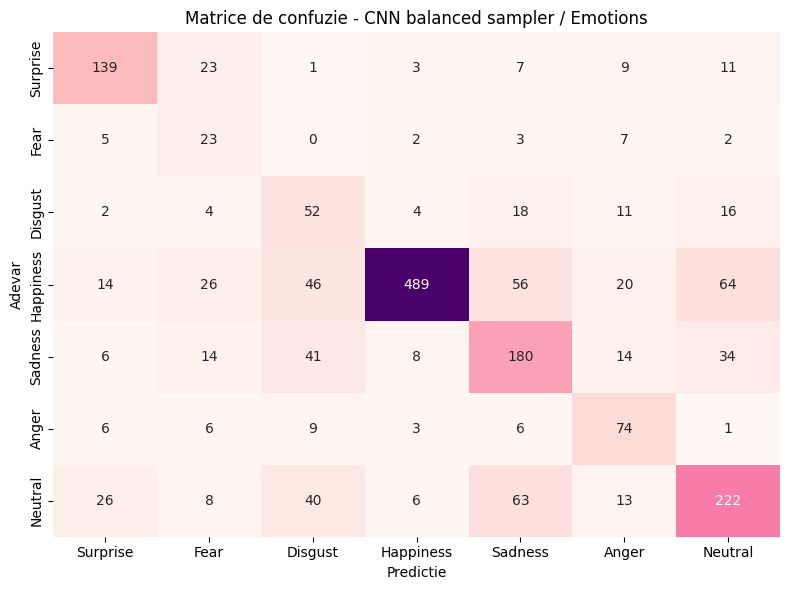

ABLATIA 3.5.4: CNN cu/fara WeightedRandomSampler
Varianta                                        Acc   F1-macro   F1-micro
CNN FARA balanced - Moles                    0.7544     0.4505     0.7544
CNN CU balanced - Moles                      0.6665     0.5429     0.6665
CNN FARA balanced - Emotions                 0.6995     0.5793     0.6995
CNN CU balanced - Emotions                   0.6418     0.5627     0.6418


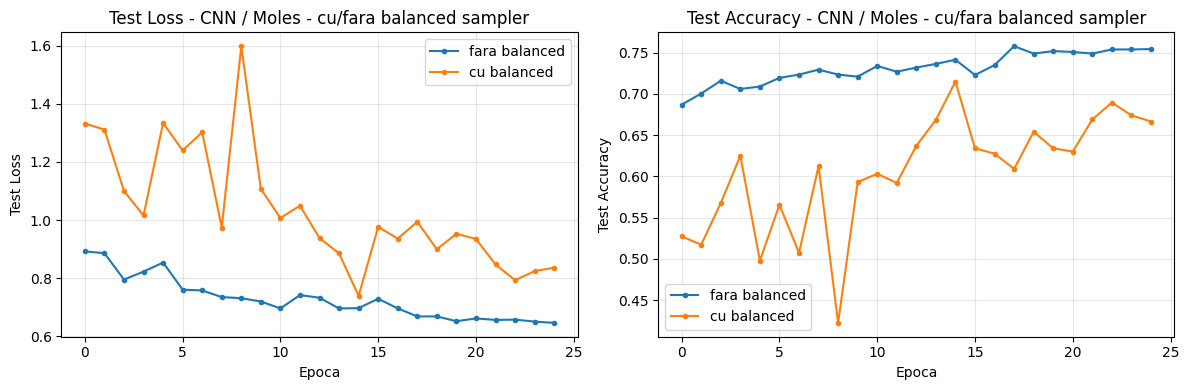

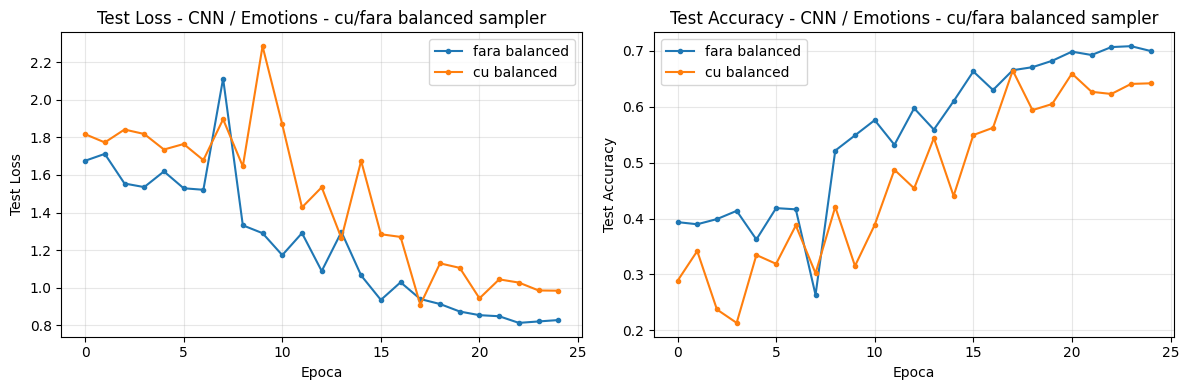

In [57]:
# Evaluare + comparare 3.5.4
moles_cnn_balanced_results = evaluate_full(moles_cnn_balanced, moles_test_loader,
                                           class_names=MOLES_CLASS_NAMES,
                                           title="CNN balanced sampler / Moles")
emo_cnn_balanced_results = evaluate_full(emo_cnn_balanced, emo_test_loader,
                                         class_names=emo_class_list,
                                         title="CNN balanced sampler / Emotions")

print_ablation_table({
    "CNN FARA balanced - Moles":     moles_cnn_results,
    "CNN CU balanced - Moles":       moles_cnn_balanced_results,
    "CNN FARA balanced - Emotions":  emo_cnn_results,
    "CNN CU balanced - Emotions":    emo_cnn_balanced_results,
}, title="ABLATIA 3.5.4: CNN cu/fara WeightedRandomSampler")

plot_ablation_curves_grid({
    "fara balanced":    moles_cnn_history,
    "cu balanced":      moles_cnn_balanced_history,
}, title="CNN / Moles - cu/fara balanced sampler")

plot_ablation_curves_grid({
    "fara balanced":    emo_cnn_history,
    "cu balanced":      emo_cnn_balanced_history,
}, title="CNN / Emotions - cu/fara balanced sampler")


## 3.5.5 Ablatie: ResNet18 frozen backbone, cu / fara warmup

In [209]:
# ResNet18 frozen backbone CU warmup - Moles
moles_frozen_warmup = make_finetune_model(num_classes=len(MOLES_CLASS_NAMES),
                                          freeze_backbone=True).to(device)
n_train = sum(p.numel() for p in moles_frozen_warmup.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in moles_frozen_warmup.parameters())
print(f"Frozen ResNet18: {n_train:,} trainable / {n_total:,} total")

moles_frozen_warmup_history = fit_finetune(
    moles_frozen_warmup, moles_ft_train_loader, moles_ft_test_loader,
    num_epochs=NUM_EPOCHS_FT, head_lr=1e-3, warmup_epochs=3,
    use_warmup=True, weight_decay=1e-4,
)


Frozen ResNet18: 3,591 trainable / 11,180,103 total


KeyboardInterrupt: 

In [59]:
# ResNet18 frozen backbone fara warmup - Moles
moles_frozen_nowarmup = make_finetune_model(num_classes=len(MOLES_CLASS_NAMES),
                                            freeze_backbone=True).to(device)
moles_frozen_nowarmup_history = fit_finetune(
    moles_frozen_nowarmup, moles_ft_train_loader, moles_ft_test_loader,
    num_epochs=NUM_EPOCHS_FT, head_lr=1e-3,
    use_warmup=False, weight_decay=1e-4,
)


Epoca 01/20 | train loss=1.0075 acc=0.677 | test loss=0.9338 acc=0.677 | lr_bb=0.00e+00 lr_hd=9.94e-04 | 22.1s
Epoca 02/20 | train loss=0.8331 acc=0.707 | test loss=0.9425 acc=0.643 | lr_bb=0.00e+00 lr_hd=9.76e-04 | 22.5s
Epoca 03/20 | train loss=0.7768 acc=0.718 | test loss=0.8013 acc=0.712 | lr_bb=0.00e+00 lr_hd=9.46e-04 | 22.3s
Epoca 04/20 | train loss=0.7614 acc=0.718 | test loss=0.7615 acc=0.734 | lr_bb=0.00e+00 lr_hd=9.05e-04 | 22.5s
Epoca 05/20 | train loss=0.7544 acc=0.722 | test loss=0.7499 acc=0.731 | lr_bb=0.00e+00 lr_hd=8.54e-04 | 22.7s
Epoca 06/20 | train loss=0.7415 acc=0.727 | test loss=0.7599 acc=0.728 | lr_bb=0.00e+00 lr_hd=7.94e-04 | 22.8s
Epoca 07/20 | train loss=0.7162 acc=0.741 | test loss=0.7788 acc=0.704 | lr_bb=0.00e+00 lr_hd=7.27e-04 | 22.6s
Epoca 08/20 | train loss=0.7077 acc=0.737 | test loss=0.7798 acc=0.709 | lr_bb=0.00e+00 lr_hd=6.55e-04 | 22.3s
Epoca 09/20 | train loss=0.7052 acc=0.743 | test loss=0.7450 acc=0.731 | lr_bb=0.00e+00 lr_hd=5.78e-04 | 22.7s
E

In [60]:
# ResNet18 frozen backbone cu warmup - Emotions
emo_frozen_warmup = make_finetune_model(num_classes=len(EMOTIONS_CLASS_NAMES),
                                        freeze_backbone=True).to(device)
emo_frozen_warmup_history = fit_finetune(
    emo_frozen_warmup, emo_ft_train_loader, emo_ft_test_loader,
    num_epochs=NUM_EPOCHS_FT, head_lr=1e-3, warmup_epochs=3,
    use_warmup=True, weight_decay=1e-4,
)


Epoca 01/20 | train loss=1.6115 acc=0.390 | test loss=1.5604 acc=0.417 | lr_bb=0.00e+00 lr_hd=6.67e-04 | 40.5s
Epoca 02/20 | train loss=1.4567 acc=0.452 | test loss=1.4172 acc=0.480 | lr_bb=0.00e+00 lr_hd=1.00e-03 | 35.3s
Epoca 03/20 | train loss=1.3765 acc=0.488 | test loss=1.3688 acc=0.494 | lr_bb=0.00e+00 lr_hd=1.00e-03 | 36.3s
Epoca 04/20 | train loss=1.3341 acc=0.506 | test loss=1.3352 acc=0.512 | lr_bb=0.00e+00 lr_hd=9.91e-04 | 36.1s
Epoca 05/20 | train loss=1.2961 acc=0.526 | test loss=1.3213 acc=0.509 | lr_bb=0.00e+00 lr_hd=9.66e-04 | 35.9s
Epoca 06/20 | train loss=1.2853 acc=0.532 | test loss=1.3197 acc=0.522 | lr_bb=0.00e+00 lr_hd=9.25e-04 | 35.6s
Epoca 07/20 | train loss=1.2790 acc=0.531 | test loss=1.3249 acc=0.507 | lr_bb=0.00e+00 lr_hd=8.70e-04 | 36.0s
Epoca 08/20 | train loss=1.2583 acc=0.541 | test loss=1.3153 acc=0.511 | lr_bb=0.00e+00 lr_hd=8.01e-04 | 38.4s
Epoca 09/20 | train loss=1.2632 acc=0.530 | test loss=1.2962 acc=0.515 | lr_bb=0.00e+00 lr_hd=7.23e-04 | 36.8s
E

In [210]:
# ResNet18 frozen backbone fara warmup - Emotions
emo_frozen_nowarmup = make_finetune_model(num_classes=len(EMOTIONS_CLASS_NAMES),
                                          freeze_backbone=True).to(device)
emo_frozen_nowarmup_history = fit_finetune(
    emo_frozen_nowarmup, emo_ft_train_loader, emo_ft_test_loader,
    num_epochs=NUM_EPOCHS_FT, head_lr=1e-3,
    use_warmup=False, weight_decay=1e-4,
)


Ep 01/40 | train loss=1.6390 acc=0.414 | test acc=0.466 F1=0.3102 *BEST* | 59.0s
Ep 02/40 | train loss=1.4928 acc=0.492 | test acc=0.500 F1=0.3452 *BEST* | 54.5s
Ep 03/40 | train loss=1.4674 acc=0.508 | test acc=0.511 F1=0.3609 *BEST* | 53.8s


KeyboardInterrupt: 


 Rezultate pentru ResNet18 frozen + warmup / Moles 
Accuracy : 0.7384
F1-macro : 0.4472
F1-micro : 0.7384

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.8182    0.1385    0.2368        65
         bcc     0.4815    0.5049    0.4929       103
         bkl     0.4741    0.5409    0.5053       220
          df     0.0000    0.0000    0.0000        23
         mel     0.4059    0.4369    0.4208       222
          nv     0.8645    0.8852    0.8747      1341
        vasc     0.7143    0.5172    0.6000        29

    accuracy                         0.7384      2003
   macro avg     0.5369    0.4319    0.4472      2003
weighted avg     0.7375    0.7384    0.7295      2003



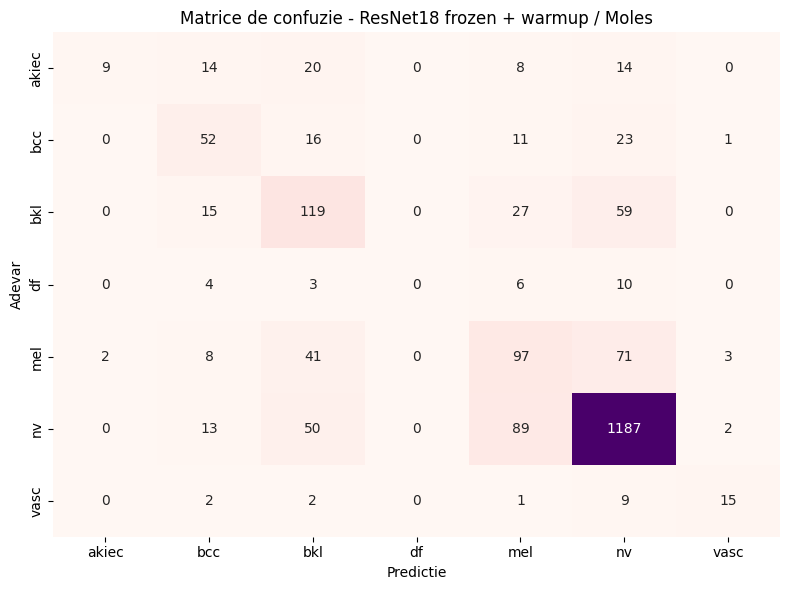


 Rezultate pentru ResNet18 frozen + no-warmup / Moles 
Accuracy : 0.7299
F1-macro : 0.4664
F1-micro : 0.7299

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.5625    0.2769    0.3711        65
         bcc     0.5054    0.4563    0.4796       103
         bkl     0.4722    0.5409    0.5042       220
          df     0.0000    0.0000    0.0000        23
         mel     0.3668    0.4775    0.4149       222
          nv     0.8778    0.8628    0.8703      1341
        vasc     0.7895    0.5172    0.6250        29

    accuracy                         0.7299      2003
   macro avg     0.5106    0.4474    0.4664      2003
weighted avg     0.7359    0.7299    0.7297      2003



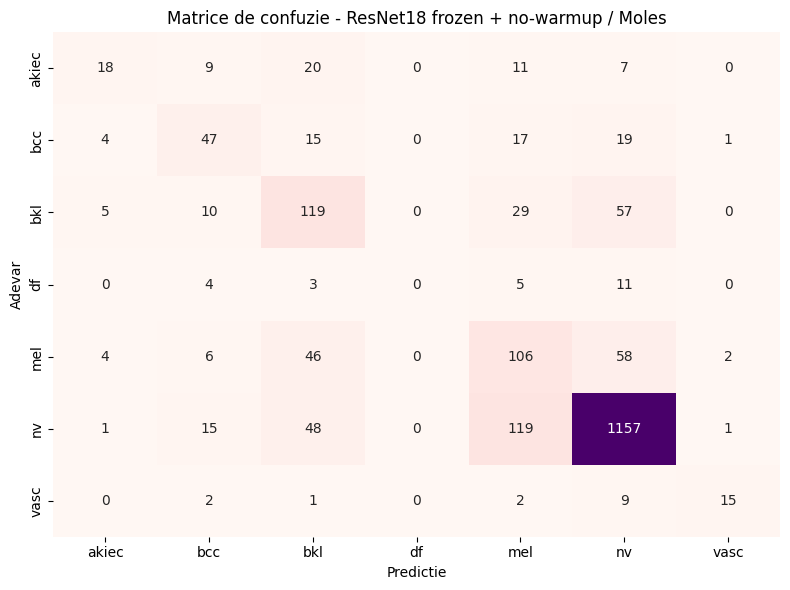


 Rezultate pentru ResNet18 frozen + warmup / Emotions 
Accuracy : 0.5340
F1-macro : 0.3873
F1-micro : 0.5340

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.4216    0.5855    0.4902       193
        Fear     0.3810    0.1905    0.2540        42
     Disgust     0.0714    0.0093    0.0165       107
   Happiness     0.6436    0.7301    0.6841       715
     Sadness     0.4815    0.3502    0.4055       297
       Anger     0.4638    0.3048    0.3678       105
     Neutral     0.4589    0.5317    0.4926       378

    accuracy                         0.5340      1837
   macro avg     0.4174    0.3860    0.3873      1837
weighted avg     0.5065    0.5340    0.5125      1837



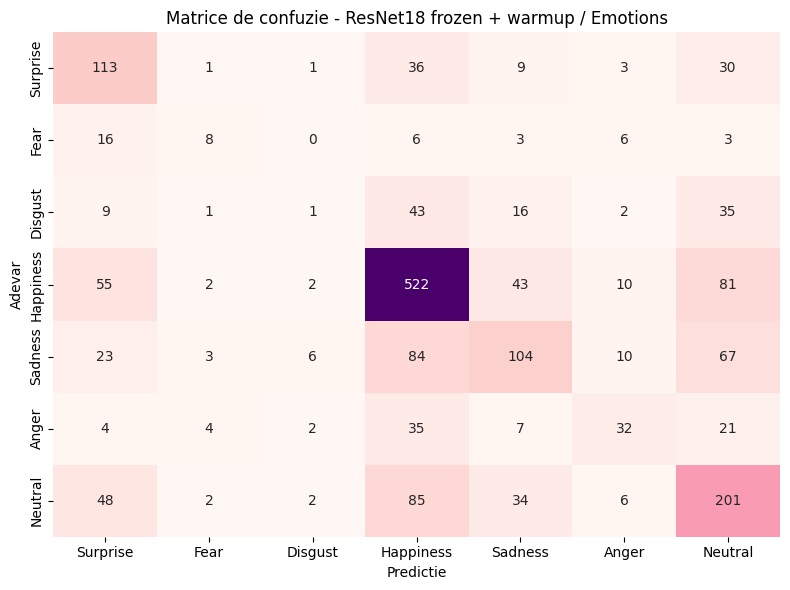


 Rezultate pentru ResNet18 frozen + no-warmup / Emotions 
Accuracy : 0.5215
F1-macro : 0.3748
F1-micro : 0.5215

Classification report per-clasa:
              precision    recall  f1-score   support

    Surprise     0.4066    0.5751    0.4764       193
        Fear     0.3810    0.1905    0.2540        42
     Disgust     0.0769    0.0093    0.0167       107
   Happiness     0.6198    0.7343    0.6722       715
     Sadness     0.4791    0.3468    0.4023       297
       Anger     0.4328    0.2762    0.3372       105
     Neutral     0.4514    0.4788    0.4647       378

    accuracy                         0.5215      1837
   macro avg     0.4068    0.3730    0.3748      1837
weighted avg     0.4922    0.5215    0.4984      1837



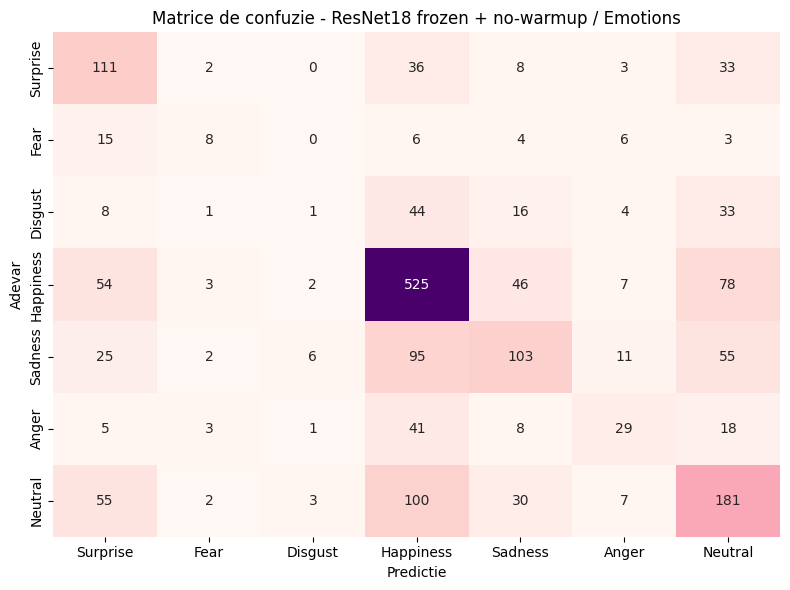

ABLATIA 3.5.5: Frozen backbone cu/fara warmup
Varianta                                        Acc   F1-macro   F1-micro
Frozen + warmup   - Moles                    0.7384     0.4472     0.7384
Frozen + NO warmup - Moles                   0.7299     0.4664     0.7299
Frozen + warmup   - Emotions                 0.5340     0.3873     0.5340
Frozen + NO warmup - Emotions                0.5215     0.3748     0.5215


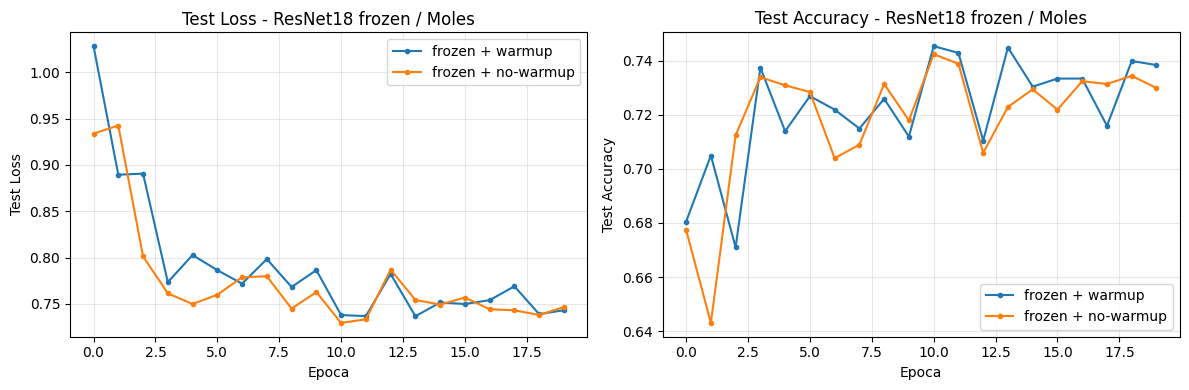

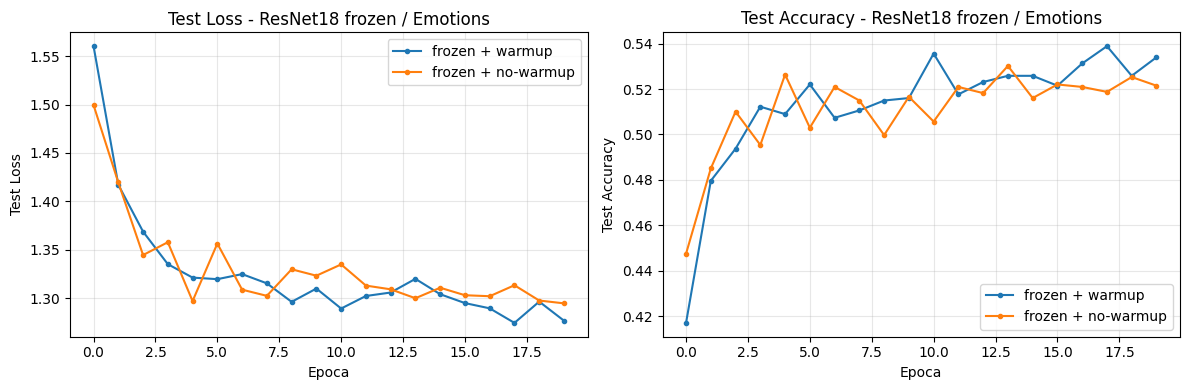

In [62]:
# Evaluare + comparare 3.5.5
moles_frozen_warmup_results = evaluate_full(moles_frozen_warmup, moles_ft_test_loader,
                                            class_names=MOLES_CLASS_NAMES,
                                            title="ResNet18 frozen + warmup / Moles")
moles_frozen_nowarmup_results = evaluate_full(moles_frozen_nowarmup, moles_ft_test_loader,
                                              class_names=MOLES_CLASS_NAMES,
                                              title="ResNet18 frozen + no-warmup / Moles")
emo_frozen_warmup_results = evaluate_full(emo_frozen_warmup, emo_ft_test_loader,
                                          class_names=emo_class_list,
                                          title="ResNet18 frozen + warmup / Emotions")
emo_frozen_nowarmup_results = evaluate_full(emo_frozen_nowarmup, emo_ft_test_loader,
                                            class_names=emo_class_list,
                                            title="ResNet18 frozen + no-warmup / Emotions")

print_ablation_table({
    "Frozen + warmup   - Moles":    moles_frozen_warmup_results,
    "Frozen + NO warmup - Moles":   moles_frozen_nowarmup_results,
    "Frozen + warmup   - Emotions": emo_frozen_warmup_results,
    "Frozen + NO warmup - Emotions": emo_frozen_nowarmup_results,
}, title="ABLATIA 3.5.5: Frozen backbone cu/fara warmup")

plot_ablation_curves_grid({
    "frozen + warmup":    moles_frozen_warmup_history,
    "frozen + no-warmup": moles_frozen_nowarmup_history,
}, title="ResNet18 frozen / Moles")

plot_ablation_curves_grid({
    "frozen + warmup":    emo_frozen_warmup_history,
    "frozen + no-warmup": emo_frozen_nowarmup_history,
}, title="ResNet18 frozen / Emotions")


## 3.5.6 Tabel sumar - toate modelele si ablatiile

In [208]:
print("REZULTATE COMPLETE")
print(f"{'Model / Configuratie':<50} {'Acc':>10} {'F1-macro':>10} {'F1-micro':>10}")

def print_row(name, res_dict_name):
    res = globals().get(res_dict_name)
    if res is not None:
        print(f"{name:<50} {res['acc']:>10.4f} {res['f1_macro']:>10.4f} {res['f1_micro']:>10.4f}")
    else:
        print(f"{name:<50} {'N/A':>10} {'N/A':>10} {'N/A':>10}")

print("--- MLP ---")
print_row("MLP cu dropout - Moles (baseline)", "moles_results")
print_row("MLP fara dropout - Moles", "moles_mlp_nodrop_results")
print_row("MLP cu dropout - Emotions (baseline)", "emo_results")
print_row("MLP fara dropout - Emotions", "emo_mlp_nodrop_results")

print("--- CNN (BN ablation) ---")
print_row("CNN cu BN, toate aug - Moles (baseline)", "moles_cnn_results")
print_row("CNN fara BN - Moles", "moles_cnn_nobn_results")
print_row("CNN cu BN, toate aug - Emotions (baseline)", "emo_cnn_results")
print_row("CNN fara BN - Emotions", "emo_cnn_nobn_results")

print("--- CNN (augmentation ablation) ---")
print_row("CNN fara aug - Moles", "moles_cnn_noaug_results")
print_row("CNN geom-only - Moles", "moles_cnn_geom_results")
print_row("CNN color-only - Moles", "moles_cnn_color_results")
print_row("CNN fara aug - Emotions", "emo_cnn_noaug_results")
print_row("CNN geom-only - Emotions", "emo_cnn_geom_results")
print_row("CNN color-only - Emotions", "emo_cnn_color_results")

print("--- CNN (imbalance ablation) ---")
print_row("CNN balanced sampler - Moles", "moles_cnn_balanced_results")
print_row("CNN balanced sampler - Emotions", "emo_cnn_balanced_results")

print("--- ResNet18 ---")
print_row("ResNet18 full FT + warmup - Moles (3.4)", "moles_ft_results")
print_row("ResNet18 frozen + warmup - Moles", "moles_frozen_warmup_results")
print_row("ResNet18 frozen, NO warmup - Moles", "moles_frozen_nowarmup_results")
print_row("ResNet18 full FT + warmup - Emotions (3.4)", "emo_ft_results")
print_row("ResNet18 frozen + warmup - Emotions", "emo_frozen_warmup_results")
print_row("ResNet18 frozen, NO warmup - Emotions", "emo_frozen_nowarmup_results")
print("=" * 80)

REZULTATE COMPLETE
Model / Configuratie                                      Acc   F1-macro   F1-micro
--- MLP ---
MLP cu dropout - Moles (baseline)                      0.7229     0.3500     0.7229
MLP fara dropout - Moles                               0.7324     0.4145     0.7324
MLP cu dropout - Emotions (baseline)                   0.6119     0.4803     0.6119
MLP fara dropout - Emotions                            0.6081     0.4980     0.6081
--- CNN (BN ablation) ---
CNN cu BN, toate aug - Moles (baseline)                0.7544     0.4505     0.7544
CNN fara BN - Moles                                    0.7194     0.2947     0.7194
CNN cu BN, toate aug - Emotions (baseline)             0.6995     0.5793     0.6995
CNN fara BN - Emotions                                 0.5041     0.2577     0.5041
--- CNN (augmentation ablation) ---
CNN fara aug - Moles                                   0.7813     0.5340     0.7813
CNN geom-only - Moles                                  0.7634     0

In [169]:
# Salvez toate modelele ablatiilor
torch.save(moles_mlp_nodrop.state_dict(), f"{SAVE_DIR}/mlp_moles_nodrop.pt")
torch.save(emo_mlp_nodrop.state_dict(),   f"{SAVE_DIR}/mlp_emotions_nodrop.pt")
torch.save(moles_cnn_nobn.state_dict(),   f"{SAVE_DIR}/cnn_moles_nobn.pt")
torch.save(emo_cnn_nobn.state_dict(),     f"{SAVE_DIR}/cnn_emotions_nobn.pt")
torch.save(moles_cnn_noaug.state_dict(),  f"{SAVE_DIR}/cnn_moles_noaug.pt")
torch.save(moles_cnn_geom.state_dict(),   f"{SAVE_DIR}/cnn_moles_geom.pt")
torch.save(moles_cnn_color.state_dict(),  f"{SAVE_DIR}/cnn_moles_color.pt")
torch.save(emo_cnn_noaug.state_dict(),    f"{SAVE_DIR}/cnn_emotions_noaug.pt")
torch.save(emo_cnn_geom.state_dict(),     f"{SAVE_DIR}/cnn_emotions_geom.pt")
torch.save(emo_cnn_color.state_dict(),    f"{SAVE_DIR}/cnn_emotions_color.pt")
torch.save(moles_cnn_balanced.state_dict(), f"{SAVE_DIR}/cnn_moles_balanced.pt")
torch.save(emo_cnn_balanced.state_dict(), f"{SAVE_DIR}/cnn_emotions_balanced.pt")
torch.save(moles_frozen_warmup.state_dict(),   f"{SAVE_DIR}/resnet18_moles_frozen_warmup.pt")
torch.save(moles_frozen_nowarmup.state_dict(), f"{SAVE_DIR}/resnet18_moles_frozen_nowarmup.pt")
torch.save(emo_frozen_warmup.state_dict(),     f"{SAVE_DIR}/resnet18_emotions_frozen_warmup.pt")
torch.save(emo_frozen_nowarmup.state_dict(),   f"{SAVE_DIR}/resnet18_emotions_frozen_nowarmup.pt")
print(f"Toate modelele ablatiilor salvate in {SAVE_DIR}")


Toate modelele ablatiilor salvate in /kaggle/working/models


# Kaggle: Generarea submisiilor pe seturile de test private

In [223]:
import glob
import pandas as pd
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image


class EmotionsKaggleDataset(Dataset):
    def __init__(self, csv_path, test_root, transform=None):
        df = pd.read_csv(csv_path)
        df.columns = [c.strip() for c in df.columns]
        self.ids = df['id'].astype(str).str.strip().tolist()
        paths = glob.glob(os.path.join(test_root, '*', '*.jpg'))
        self.name2path = {os.path.basename(p): p for p in paths}
        self.transform = transform
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, idx):
        fname = self.ids[idx]
        img = Image.open(self.name2path[fname]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, 0

@torch.no_grad()
def predict_batched(model, loader, device):
    model.eval()
    all_preds = []
    for images, _ in loader:
        images = images.to(device)
        all_preds.append(model(images).argmax(1).cpu().numpy())
    return np.concatenate(all_preds)

@torch.no_grad()
def predict_tta_5(model, dataset_class, dataset_args, tta_transforms, device, batch_size=32):
    """TTA cu 5 variante: mediaza softmax probabilities."""
    model.eval()
    sum_probs = None
    all_extra = None
    for tf in tta_transforms:
        ds = dataset_class(**dataset_args, transform=tf)
        dl = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=2)
        batch_probs, batch_extra = [], []
        for imgs, extra in dl:
            probs = torch.softmax(model(imgs.to(device)), dim=1).cpu()
            batch_probs.append(probs)
            if isinstance(extra, (list, tuple)):
                batch_extra.extend(extra)
            else:
                batch_extra.extend(extra.numpy().tolist())
        probs = torch.cat(batch_probs, dim=0)
        if sum_probs is None:
            sum_probs = probs
            all_extra = batch_extra
        else:
            sum_probs += probs

    avg_probs = sum_probs / len(tta_transforms)
    preds = avg_probs.argmax(dim=1).numpy()
    return preds

moles_tta_transforms = [
    moles_ft_eval_transform,  # 1. original
    transforms.Compose([transforms.Resize((224,224)), transforms.RandomHorizontalFlip(p=1.0),
                        transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    transforms.Compose([transforms.Resize((224,224)), transforms.RandomVerticalFlip(p=1.0),
                        transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    transforms.Compose([transforms.Resize((224,224)), transforms.RandomRotation(degrees=(10,10)),
                        transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    transforms.Compose([transforms.Resize((224,224)), transforms.RandomRotation(degrees=(-10,-10)),
                        transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
]

emo_tta_transforms = [
    emo_ft_eval_transform,  # 1. original
    transforms.Compose([transforms.Resize((224,224)), transforms.RandomHorizontalFlip(p=1.0),
                        transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    transforms.Compose([transforms.Resize((224,224)), transforms.RandomRotation(degrees=(10,10)),
                        transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    transforms.Compose([transforms.Resize((224,224)), transforms.RandomRotation(degrees=(-10,-10)),
                        transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    transforms.Compose([transforms.Resize((224,224)), transforms.ColorJitter(brightness=0.1, contrast=0.1),
                        transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
]

def make_moles_submission(model, transform, out_name, use_tta=False):
    ds = MolesDataset(MOLES_KAGGLE_CSV, MOLES_KAGGLE_IMG_DIR, transform=transform)
    loader = DataLoader(ds, batch_size=128, shuffle=False, num_workers=2)
    preds = predict_tta(model, loader, device) if use_tta else predict_batched(model, loader, device)
    sub = pd.DataFrame({'id': pd.read_csv(MOLES_KAGGLE_CSV)['imagine'], 'Prediction': preds.astype(int)})
    sub.to_csv(f"{WORK_DIR}/{out_name}", index=False)
    print(f"Salvat: {out_name} ({len(sub)} randuri)")

def make_emotions_submission(model, transform, out_name, use_tta=False):
    test_root = f"{dataset_emotii}/DATASET/test"
    ds = EmotionsKaggleDataset(EMOTIONS_REMOTE_TEST_CSV, test_root, transform=transform)
    loader = DataLoader(ds, batch_size=128, shuffle=False, num_workers=2)
    preds = predict_tta(model, loader, device) if use_tta else predict_batched(model, loader, device)
    df_t = pd.read_csv(EMOTIONS_REMOTE_TEST_CSV); df_t.columns = [c.strip() for c in df_t.columns]
    sub = pd.DataFrame({'id': df_t['id'], 'label': preds + 1})
    sub.to_csv(f"{WORK_DIR}/{out_name}", index=False)
    print(f"Salvat: {out_name} ({len(sub)} randuri)")

In [ ]:
# MOLES submissions
make_moles_submission(moles_mlp, moles_eval_transform, "sub_moles_mlp.csv")
make_moles_submission(moles_cnn_balanced, moles_eval_transform, "sub_moles_cnn.csv")

# Moles ResNet cu TTA 5 variante
preds_m = predict_tta_5(moles_ft, MolesDataset,
                        {'csv_path': MOLES_KAGGLE_CSV, 'img_dir': MOLES_KAGGLE_IMG_DIR},
                        moles_tta_transforms, device)
sub_m = pd.DataFrame({'id': pd.read_csv(MOLES_KAGGLE_CSV)['imagine'], 'Prediction': preds_m.astype(int)})
sub_m.to_csv(f"{WORK_DIR}/sub_moles_resnet18.csv", index=False)
print(f"Moles ResNet TTA5 salvat ({len(sub_m)} randuri)")

In [2]:
# EMOTIONS
make_emotions_submission(emo_mlp, emotions_eval_transform, "sub_emotions_mlp.csv")
make_emotions_submission(emo_cnn_balanced, emotions_eval_transform, "sub_emotions_cnn.csv")
test_root = f"{dataset_emotii}/DATASET/test"
preds_e = predict_tta_5(emo_ft, EmotionsKaggleDataset,
                        {'csv_path': EMOTIONS_REMOTE_TEST_CSV, 'test_root': test_root},
                        emo_tta_transforms, device)
df_t = pd.read_csv(EMOTIONS_REMOTE_TEST_CSV)
df_t.columns = [c.strip() for c in df_t.columns]
sub_e = pd.DataFrame({'id': df_t['id'], 'label': preds_e + 1})
sub_e.to_csv(f"{WORK_DIR}/sub_emotions_resnet18.csv", index=False)
print(f"Emotions ResNet TTA5 salvat ({len(sub_e)} randuri)")

NameError: name 'make_emotions_submission' is not defined

# BONUS: Curriculum Learning

In [87]:
# Pas 1: Calculul dificultatii fiecarui exemplu 
from torch.utils.data import Subset

print("Antrenez CNN sonda (3 epoci) pentru a calcula dificultatea exemplelor...")
probe_model = SimpleCNN(num_classes=len(MOLES_CLASS_NAMES), first_kernel=5).to(device)
probe_criterion = nn.CrossEntropyLoss(reduction='none') 
probe_optimizer = optim.Adam(probe_model.parameters(), lr=1e-3, weight_decay=1e-4)

# Antrenare
probe_loader = DataLoader(moles_train_ds, batch_size=64, shuffle=True, num_workers=2, drop_last=False)
for epoch in range(3):
    probe_model.train()
    for imgs, lbls in probe_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        probe_optimizer.zero_grad()
        loss = probe_criterion(probe_model(imgs), lbls).mean()
        loss.backward()
        probe_optimizer.step()
    print(f"  Sonda epoca {epoch+1}/3 completata")

print("Calculez dificultatea per exemplu...")
moles_probe_ds = MolesDataset(MOLES_TRAIN_CSV, MOLES_TRAIN_IMG_DIR,
                              transform=moles_eval_transform)
probe_eval_loader = DataLoader(moles_probe_ds, batch_size=128, shuffle=False, num_workers=2)

probe_model.eval()
all_losses = []
with torch.no_grad():
    for imgs, lbls in probe_eval_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        losses = probe_criterion(probe_model(imgs), lbls)
        all_losses.append(losses.cpu().numpy())

difficulties = np.concatenate(all_losses)
sorted_indices = np.argsort(difficulties)

print(f"Exemplul cel mai usor: loss = {difficulties[sorted_indices[0]]:.4f}")
print(f"Exemplul cel mai greu: loss = {difficulties[sorted_indices[-1]]:.4f}")
print(f"Mediana: {np.median(difficulties):.4f}")

Antrenez CNN sonda (3 epoci) pentru a calcula dificultatea exemplelor...
  Sonda epoca 1/3 completata
  Sonda epoca 2/3 completata
  Sonda epoca 3/3 completata
Calculez dificultatea per exemplu...
Exemplul cel mai usor: loss = 0.0003
Exemplul cel mai greu: loss = 7.4982
Mediana: 0.4971


/tmp/ipykernel_57/2012238952.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(class_diffs, labels=MOLES_CLASS_NAMES)


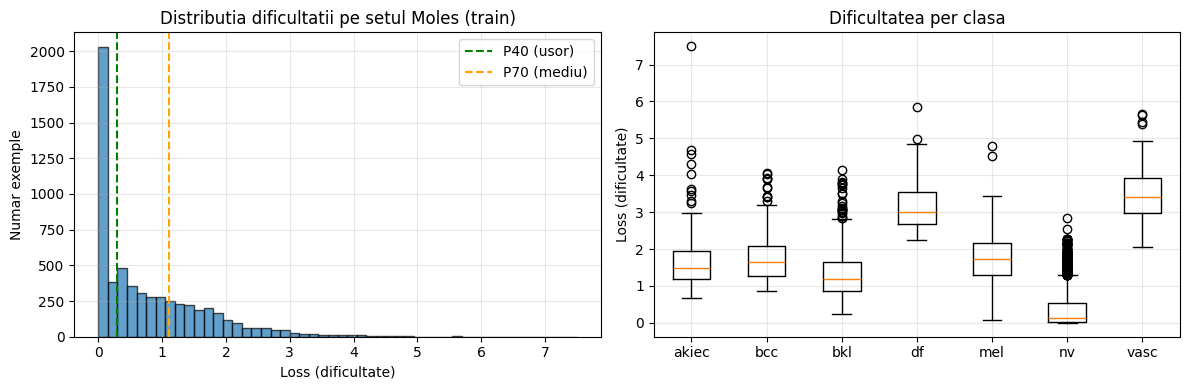

  akiec : mediana loss = 1.486, N = 196
  bcc   : mediana loss = 1.649, N = 308
  bkl   : mediana loss = 1.197, N = 660
  df    : mediana loss = 3.009, N = 69
  mel   : mediana loss = 1.740, N = 668
  nv    : mediana loss = 0.143, N = 4023
  vasc  : mediana loss = 3.422, N = 85


In [88]:
# Vizualizare distributia dificultatii
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma dificultatii
axes[0].hist(difficulties, bins=50, edgecolor='black', alpha=0.7)
axes[0].set_xlabel("Loss (dificultate)")
axes[0].set_ylabel("Numar exemple")
axes[0].set_title("Distributia dificultatii pe setul Moles (train)")
axes[0].axvline(x=np.percentile(difficulties, 40), color='green', linestyle='--', label='P40 (usor)')
axes[0].axvline(x=np.percentile(difficulties, 70), color='orange', linestyle='--', label='P70 (mediu)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Dificultatea per clasa
labels = moles_train_ds.get_labels()
class_diffs = [difficulties[labels == c] for c in range(len(MOLES_CLASS_NAMES))]
axes[1].boxplot(class_diffs, labels=MOLES_CLASS_NAMES)
axes[1].set_ylabel("Loss (dificultate)")
axes[1].set_title("Dificultatea per clasa")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

for i, name in enumerate(MOLES_CLASS_NAMES):
    med = np.median(class_diffs[i])
    print(f"  {name:6s}: mediana loss = {med:.3f}, N = {len(class_diffs[i])}")


In [89]:
# Antrenare CNN cu Curriculum Learning
print("Antrenez CNN cu curriculum (usor -> greu)...")

model_curriculum = SimpleCNN(num_classes=len(MOLES_CLASS_NAMES), first_kernel=5).to(device)
criterion_cl = nn.CrossEntropyLoss()
optimizer_cl = optim.Adam(model_curriculum.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_cl = optim.lr_scheduler.CosineAnnealingLR(optimizer_cl, T_max=NUM_EPOCHS)

curriculum_history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [],
                      "frac_used": []}

for epoch in range(NUM_EPOCHS):
    t0 = time.time()
    if epoch < 8:
        frac = 0.4 
    elif epoch < 16:
        frac = 0.7  
    else:
        frac = 1.0 

    n_samples = int(len(sorted_indices) * frac)
    current_indices = sorted_indices[:n_samples].tolist()
    subset = Subset(moles_train_ds, current_indices)
    subset_loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=2, drop_last=True)

    # Train
    model_curriculum.train()
    tr_loss, tr_correct, tr_seen = 0.0, 0, 0
    for imgs, lbls in subset_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_cl.zero_grad()
        out = model_curriculum(imgs)
        loss = criterion_cl(out, lbls)
        loss.backward()
        optimizer_cl.step()
        tr_loss += loss.item() * imgs.size(0)
        tr_correct += (out.argmax(1) == lbls).sum().item()
        tr_seen += lbls.size(0)
    scheduler_cl.step()

    # Eval 
    te_loss, te_acc = evaluate(model_curriculum, moles_test_loader,
                               criterion_cl, device)

    curriculum_history["train_loss"].append(tr_loss / tr_seen)
    curriculum_history["train_acc"].append(tr_correct / tr_seen)
    curriculum_history["test_loss"].append(te_loss)
    curriculum_history["test_acc"].append(te_acc)
    curriculum_history["frac_used"].append(frac)

    print(f"Epoca {epoch+1:02d}/{NUM_EPOCHS} | "
          f"date={frac*100:.0f}% ({n_samples}) | "
          f"train loss={tr_loss/tr_seen:.4f} acc={tr_correct/tr_seen:.3f} | "
          f"test loss={te_loss:.4f} acc={te_acc:.3f} | "
          f"{time.time()-t0:.1f}s")


Antrenez CNN cu curriculum (usor -> greu)...
Epoca 01/25 | date=40% (2403) | train loss=1.0299 acc=0.777 | test loss=1.2530 acc=0.669 | 6.8s
Epoca 02/25 | date=40% (2403) | train loss=0.1412 acc=0.997 | test loss=1.4778 acc=0.669 | 6.0s
Epoca 03/25 | date=40% (2403) | train loss=0.0563 acc=0.997 | test loss=1.7531 acc=0.669 | 6.2s
Epoca 04/25 | date=40% (2403) | train loss=0.0388 acc=0.997 | test loss=1.9931 acc=0.669 | 6.0s
Epoca 05/25 | date=40% (2403) | train loss=0.0311 acc=0.997 | test loss=1.8881 acc=0.669 | 6.1s
Epoca 06/25 | date=40% (2403) | train loss=0.0262 acc=0.997 | test loss=2.1042 acc=0.669 | 6.1s
Epoca 07/25 | date=40% (2403) | train loss=0.0247 acc=0.997 | test loss=2.1690 acc=0.669 | 6.0s
Epoca 08/25 | date=40% (2403) | train loss=0.0205 acc=0.996 | test loss=2.0190 acc=0.669 | 6.1s
Epoca 09/25 | date=70% (4206) | train loss=0.3708 acc=0.892 | test loss=1.5170 acc=0.678 | 8.9s
Epoca 10/25 | date=70% (4206) | train loss=0.2704 acc=0.908 | test loss=1.3288 acc=0.667 | 

In [90]:
# === Pas 3: Antrenare CNN cu Anti-Curriculum (greu -> usor) ===
# Invers: incepem cu exemplele GRELE si adaugam treptat pe cele usoare.
# Aceasta varianta este uneori surprinzator de eficace — motiveaza ablatie.

print("\nAntrenez CNN cu anti-curriculum (greu -> usor)...")

model_anti = SimpleCNN(num_classes=len(MOLES_CLASS_NAMES), first_kernel=5).to(device)
criterion_ac = nn.CrossEntropyLoss()
optimizer_ac = optim.Adam(model_anti.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_ac = optim.lr_scheduler.CosineAnnealingLR(optimizer_ac, T_max=NUM_EPOCHS)

reversed_indices = sorted_indices[::-1].copy()  # greu -> usor

anti_history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(NUM_EPOCHS):
    t0 = time.time()
    if epoch < 8:
        frac = 0.4
    elif epoch < 16:
        frac = 0.7
    else:
        frac = 1.0

    n_samples = int(len(reversed_indices) * frac)
    subset = Subset(moles_train_ds, reversed_indices[:n_samples].tolist())
    subset_loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=2, drop_last=True)

    model_anti.train()
    tr_loss, tr_correct, tr_seen = 0.0, 0, 0
    for imgs, lbls in subset_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_ac.zero_grad()
        out = model_anti(imgs)
        loss = criterion_ac(out, lbls)
        loss.backward()
        optimizer_ac.step()
        tr_loss += loss.item() * imgs.size(0)
        tr_correct += (out.argmax(1) == lbls).sum().item()
        tr_seen += lbls.size(0)
    scheduler_ac.step()

    te_loss, te_acc = evaluate(model_anti, moles_test_loader,
                               criterion_ac, device)
    anti_history["train_loss"].append(tr_loss / tr_seen)
    anti_history["train_acc"].append(tr_correct / tr_seen)
    anti_history["test_loss"].append(te_loss)
    anti_history["test_acc"].append(te_acc)

    print(f"Epoca {epoch+1:02d}/{NUM_EPOCHS} | "
          f"date={frac*100:.0f}% ({n_samples}) | "
          f"train loss={tr_loss/tr_seen:.4f} acc={tr_correct/tr_seen:.3f} | "
          f"test loss={te_loss:.4f} acc={te_acc:.3f} | "
          f"{time.time()-t0:.1f}s")



Antrenez CNN cu anti-curriculum (greu -> usor)...
Epoca 01/25 | date=40% (2403) | train loss=1.7763 acc=0.300 | test loss=1.7376 acc=0.236 | 6.6s
Epoca 02/25 | date=40% (2403) | train loss=1.5488 acc=0.370 | test loss=1.6684 acc=0.231 | 6.0s
Epoca 03/25 | date=40% (2403) | train loss=1.5086 acc=0.378 | test loss=1.5938 acc=0.267 | 6.3s
Epoca 04/25 | date=40% (2403) | train loss=1.4485 acc=0.412 | test loss=2.0073 acc=0.207 | 5.9s
Epoca 05/25 | date=40% (2403) | train loss=1.4353 acc=0.419 | test loss=1.8873 acc=0.217 | 6.0s
Epoca 06/25 | date=40% (2403) | train loss=1.4109 acc=0.415 | test loss=1.5805 acc=0.253 | 6.3s
Epoca 07/25 | date=40% (2403) | train loss=1.3784 acc=0.437 | test loss=1.7039 acc=0.239 | 5.9s
Epoca 08/25 | date=40% (2403) | train loss=1.3718 acc=0.452 | test loss=1.6329 acc=0.189 | 6.1s
Epoca 09/25 | date=70% (4206) | train loss=1.1589 acc=0.547 | test loss=0.8706 acc=0.697 | 8.7s
Epoca 10/25 | date=70% (4206) | train loss=1.0761 acc=0.588 | test loss=0.8585 acc=0.


 Rezultate pentru CNN Curriculum / Moles 
Accuracy : 0.7284
F1-macro : 0.3509
F1-micro : 0.7284

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.3137    0.2462    0.2759        65
         bcc     0.5443    0.4175    0.4725       103
         bkl     0.4048    0.4636    0.4322       220
          df     0.0000    0.0000    0.0000        23
         mel     0.4843    0.3468    0.4042       222
          nv     0.8352    0.9105    0.8712      1341
        vasc     0.0000    0.0000    0.0000        29

    accuracy                         0.7284      2003
   macro avg     0.3689    0.3407    0.3509      2003
weighted avg     0.6954    0.7284    0.7088      2003



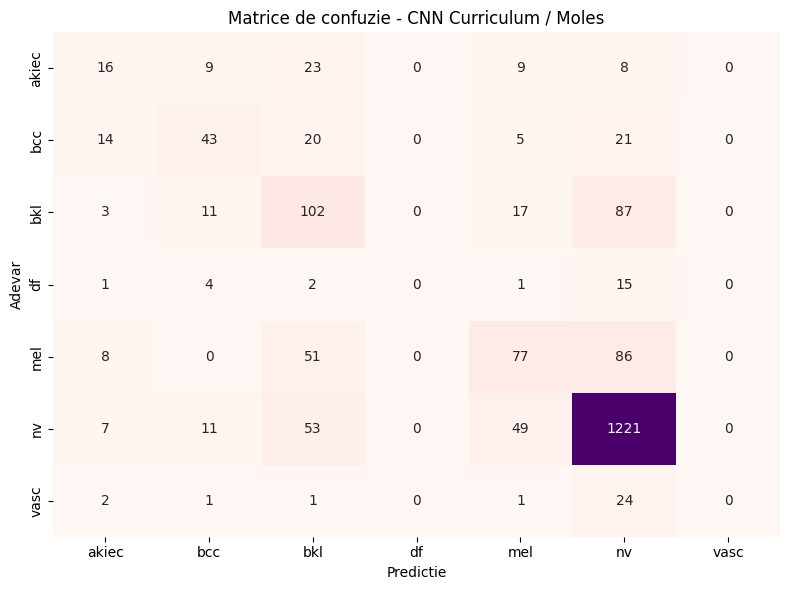


 Rezultate pentru CNN Anti-Curriculum / Moles 
Accuracy : 0.7429
F1-macro : 0.4380
F1-micro : 0.7429

Classification report per-clasa:
              precision    recall  f1-score   support

       akiec     0.3396    0.2769    0.3051        65
         bcc     0.5696    0.4369    0.4945       103
         bkl     0.4124    0.5136    0.4575       220
          df     0.0000    0.0000    0.0000        23
         mel     0.5035    0.3198    0.3912       222
          nv     0.8541    0.9165    0.8842      1341
        vasc     0.7500    0.4138    0.5333        29

    accuracy                         0.7429      2003
   macro avg     0.4899    0.4111    0.4380      2003
weighted avg     0.7241    0.7429    0.7286      2003



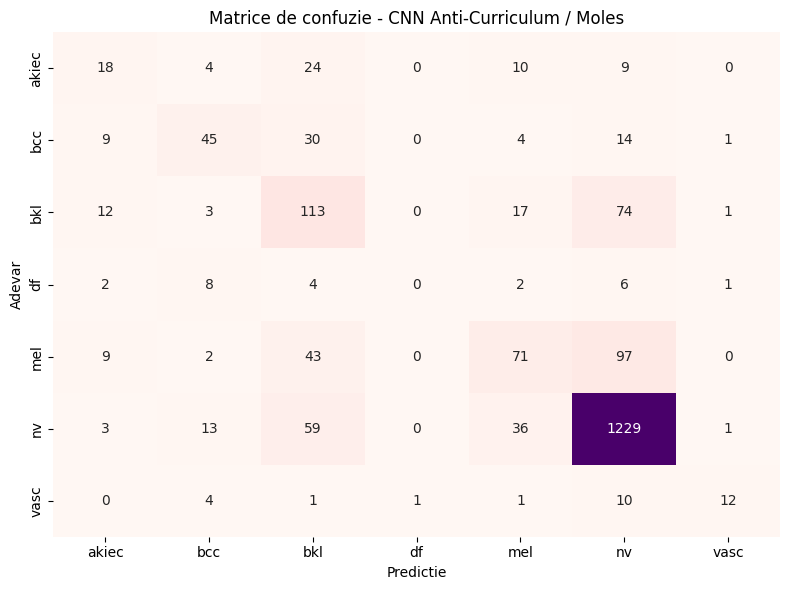

BONUS: Curriculum Learning / Moles
Varianta                                        Acc   F1-macro   F1-micro
CNN baseline (toate datele)                  0.7544     0.4505     0.7544
CNN Curriculum (usor -> greu)                0.7284     0.3509     0.7284
CNN Anti-Curriculum (greu -> usor)           0.7429     0.4380     0.7429


In [92]:
#Baseline vs Curriculum vs Anti-Curriculum

# Evaluare finala
curriculum_results = evaluate_full(model_curriculum, moles_test_loader,
                                   class_names=MOLES_CLASS_NAMES,
                                   title="CNN Curriculum / Moles")
anti_results = evaluate_full(model_anti, moles_test_loader,
                             class_names=MOLES_CLASS_NAMES,
                             title="CNN Anti-Curriculum / Moles")

print_ablation_table({
    "CNN baseline (toate datele)":       moles_cnn_results,
    "CNN Curriculum (usor -> greu)":     curriculum_results,
    "CNN Anti-Curriculum (greu -> usor)": anti_results,
}, title="BONUS: Curriculum Learning / Moles")


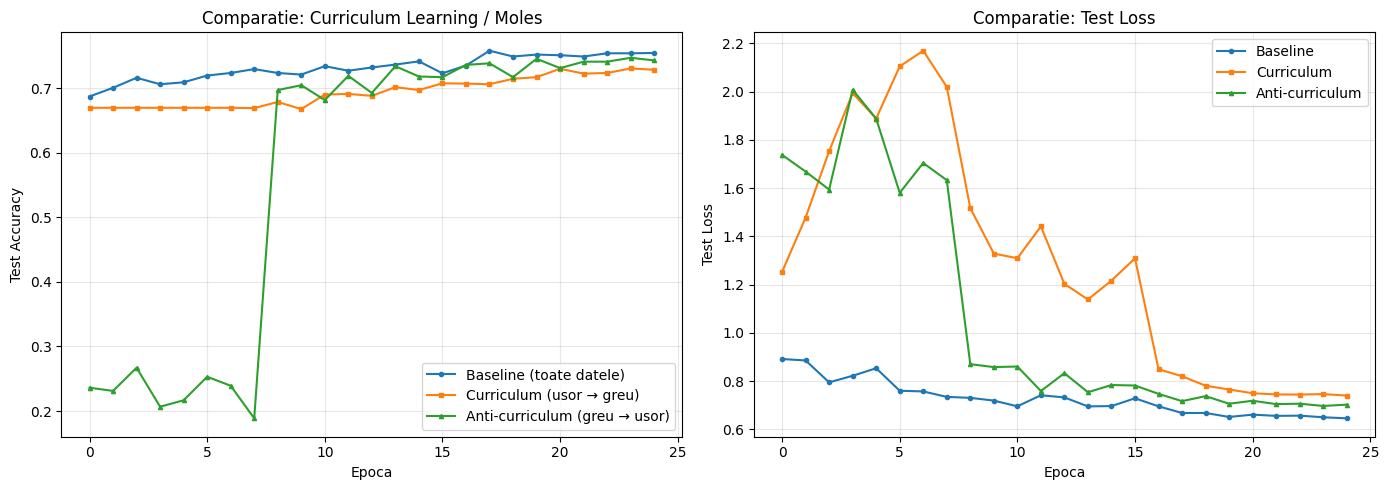

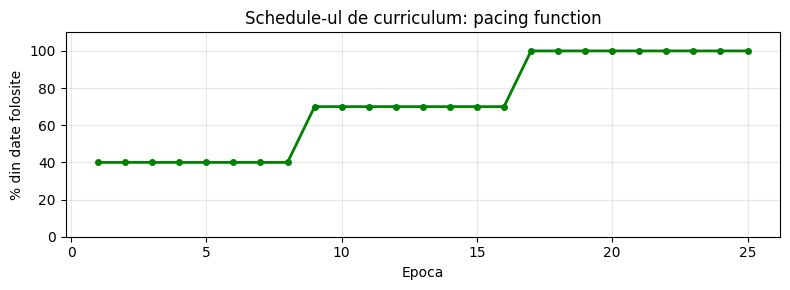

In [93]:
# Plot comparativ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Test accuracy
axes[0].plot(moles_cnn_history["test_acc"],      label="Baseline (toate datele)", marker='o', markersize=3)
axes[0].plot(curriculum_history["test_acc"],      label="Curriculum (usor → greu)", marker='s', markersize=3)
axes[0].plot(anti_history["test_acc"],            label="Anti-curriculum (greu → usor)", marker='^', markersize=3)
axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Test Accuracy")
axes[0].set_title("Comparatie: Curriculum Learning / Moles")
axes[0].legend(); axes[0].grid(alpha=0.3)

# Test loss
axes[1].plot(moles_cnn_history["test_loss"],      label="Baseline", marker='o', markersize=3)
axes[1].plot(curriculum_history["test_loss"],      label="Curriculum", marker='s', markersize=3)
axes[1].plot(anti_history["test_loss"],            label="Anti-curriculum", marker='^', markersize=3)
axes[1].set_xlabel("Epoca"); axes[1].set_ylabel("Test Loss")
axes[1].set_title("Comparatie: Test Loss")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

# Plot pacing function
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(1, NUM_EPOCHS+1), [f*100 for f in curriculum_history["frac_used"]],
        marker='o', markersize=4, color='green', linewidth=2)
ax.set_xlabel("Epoca"); ax.set_ylabel("% din date folosite")
ax.set_title("Schedule-ul de curriculum: pacing function")
ax.set_ylim(0, 110); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


In [ ]:
# antrenare + TTA9 submisie - pt ex 4
import os, glob, time
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from torch.optim.lr_scheduler import LambdaLR, CosineAnnealingLR, SequentialLR
from sklearn.metrics import f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = "/kaggle/working"
dataset_emotii = "/kaggle/input/datasets/oncioiumirunaelena/emotion" 
TRAIN_CSV = f"{dataset_emotii}/splits/train.csv"
TEST_CSV  = f"{dataset_emotii}/splits/local_test.csv"
REMOTE_CSV = f"{dataset_emotii}/splits/remote_test.csv"
IMG_ROOT  = dataset_emotii
TEST_ROOT = f"{dataset_emotii}/DATASET/test"
MEAN, STD = [0.485,0.456,0.406], [0.229,0.224,0.225]

# --- DATASET ---
class EmoDS(Dataset):
    def __init__(self, csv_path, img_root, transform):
        self.df = pd.read_csv(csv_path)
        self.df.columns = [c.strip() for c in self.df.columns]
        pcol = [c for c in self.df.columns if c != 'label'][0]
        self.paths = [os.path.join(img_root, os.path.basename(str(r))) 
                      for r in self.df[pcol]]
        # build path index from actual files
        all_files = glob.glob(os.path.join(img_root, 'DATASET', '*', '*', '*.jpg'))
        self.name2path = {os.path.basename(p): p for p in all_files}
        self.labels = (self.df['label'] - 1).values
        self.transform = transform
    def __len__(self): return len(self.df)
    def get_labels(self): return self.labels
    def __getitem__(self, idx):
        pcol = [c for c in self.df.columns if c != 'label'][0]
        fname = os.path.basename(str(self.df.iloc[idx][pcol]).strip())
        img = Image.open(self.name2path[fname]).convert("RGB")
        if self.transform: img = self.transform(img)
        return img, self.labels[idx]

class EmoTestDS(Dataset):
    def __init__(self, csv_path, test_root, transform):
        df = pd.read_csv(csv_path); df.columns = [c.strip() for c in df.columns]
        self.ids = df['id'].astype(str).str.strip().tolist()
        paths = glob.glob(os.path.join(test_root, '*', '*.jpg'))
        self.name2path = {os.path.basename(p): p for p in paths}
        self.transform = transform
    def __len__(self): return len(self.ids)
    def __getitem__(self, idx):
        img = Image.open(self.name2path[self.ids[idx]]).convert("RGB")
        if self.transform: img = self.transform(img)
        return img, 0

# --- TRANSFORMS ---
train_tf = transforms.Compose([
    transforms.Resize((232,232)), transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(0.5), transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.1)),
])
eval_tf = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])

# --- DATA ---
train_ds = EmoDS(TRAIN_CSV, IMG_ROOT, train_tf)
test_ds  = EmoDS(TEST_CSV,  IMG_ROOT, eval_tf)
labels = train_ds.get_labels()
counts = np.bincount(labels)
sw = 1.0 / counts[labels]
sampler = WeightedRandomSampler(torch.from_numpy(sw).double(), len(labels), replacement=True)
train_loader = DataLoader(train_ds, batch_size=32, sampler=sampler, num_workers=2, drop_last=True)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2)
print(f"Train: {len(train_ds)}, Test: {len(test_ds)}, Device: {device}")

# --- MODEL ---
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, 7)
model = model.to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
bb = [p for n,p in model.named_parameters() if not n.startswith('fc.')]
hd = [p for n,p in model.named_parameters() if n.startswith('fc.')]
optimizer = optim.AdamW([{'params':bb,'lr':5e-5},{'params':hd,'lr':1e-3}], weight_decay=1e-4)
N_EP = 80
warmup = LambdaLR(optimizer, lr_lambda=lambda e: (e+1)/5)
cosine = CosineAnnealingLR(optimizer, T_max=N_EP-5, eta_min=1e-6)
scheduler = SequentialLR(optimizer, [warmup, cosine], milestones=[5])

# --- TRAIN ---
best_f1 = 0
for ep in range(N_EP):
    t0 = time.time()
    model.train()
    tl, tc, tt = 0., 0, 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        # mixup
        lam = np.random.beta(0.2, 0.2)
        idx = torch.randperm(imgs.size(0)).to(device)
        mixed = lam*imgs + (1-lam)*imgs[idx]
        out = model(mixed)
        loss = lam*criterion(out, lbls) + (1-lam)*criterion(out, lbls[idx])
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tl += loss.item()*imgs.size(0); tc += (out.argmax(1)==lbls).sum().item(); tt += lbls.size(0)
    scheduler.step()
    model.eval()
    ap, al = [], []
    with torch.no_grad():
        for imgs, lbls in test_loader:
            ap.append(model(imgs.to(device)).argmax(1).cpu().numpy())
            al.append(lbls.numpy())
    f1 = f1_score(np.concatenate(al), np.concatenate(ap), average='macro')
    mk = ""
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), f"{WORK_DIR}/best_ft.pt")
        mk = " *BEST*"
    if (ep+1)%5==0 or mk:
        print(f"Ep {ep+1:02d}/{N_EP} | loss={tl/tt:.4f} acc={tc/tt:.3f} | F1={f1:.4f}{mk} | {time.time()-t0:.1f}s")
print(f"\nBest F1: {best_f1:.4f}")
model.load_state_dict(torch.load(f"{WORK_DIR}/best_ft.pt"))

# --- TTA9 SUBMISSION ---
tta_tfs = [
    eval_tf,
    transforms.Compose([transforms.Resize((224,224)),transforms.RandomHorizontalFlip(p=1.0),transforms.ToTensor(),transforms.Normalize(MEAN,STD)]),
    transforms.Compose([transforms.Resize((224,224)),transforms.RandomRotation((10,10)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)]),
    transforms.Compose([transforms.Resize((224,224)),transforms.RandomRotation((-10,-10)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)]),
    transforms.Compose([transforms.Resize((224,224)),transforms.ColorJitter(0.1,0.1),transforms.ToTensor(),transforms.Normalize(MEAN,STD)]),
    transforms.Compose([transforms.Resize((224,224)),transforms.RandomRotation((5,5)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)]),
    transforms.Compose([transforms.Resize((224,224)),transforms.RandomRotation((-5,-5)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)]),
    transforms.Compose([transforms.Resize((240,240)),transforms.CenterCrop(224),transforms.ToTensor(),transforms.Normalize(MEAN,STD)]),
    transforms.Compose([transforms.Resize((210,210)),transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)]),
]
sum_probs = None
model.eval()
with torch.no_grad():
    for i, tf in enumerate(tta_tfs):
        ds = EmoTestDS(REMOTE_CSV, TEST_ROOT, tf)
        dl = DataLoader(ds, batch_size=32, shuffle=False, num_workers=2)
        bp = [torch.softmax(model(im.to(device)),1).cpu() for im,_ in dl]
        p = torch.cat(bp, 0)
        sum_probs = p if sum_probs is None else sum_probs + p
        print(f"  TTA {i+1}/9 done")
preds = (sum_probs/len(tta_tfs)).argmax(1).numpy()
df_t = pd.read_csv(REMOTE_CSV); df_t.columns = [c.strip() for c in df_t.columns]
sub = pd.DataFrame({'id': df_t['id'], 'label': preds + 1})
sub.to_csv(f"{WORK_DIR}/sub_emotions_resnet18.csv", index=False)
print(f"\nGata! {len(sub)} randuri salvate. Trimite sub_emotions_resnet18.csv pe Kaggle.")